In [1]:
from fairmd.idp.protein_functions import *
import yaml

databankPath = "/home/sosamuli/work/NMRlipids/IDPdatabank/"  # this is the local path for the cloned Databank
os.environ["NMLDB_ROOT_PATH"] = "/home/sosamuli/work/NMRlipids/IDPdatabank/"

#databankPath = "/home/sosamuli/work/NMRlipids/IDPsimBank/"  # this is the local path for the cloned Databank
#os.environ["NMLDB_ROOT_PATH"] = "/home/sosamuli/work/NMRlipids/IDPsimBank/"


# These two lines include core Databank routines and Databank API
from fairmd.idp.core import *
from fairmd.idp.databankLibrary import *
# This is for plotting
from fairmd.idp.databankio import *
from fairmd.idp.plottings import plotSimulation
#from IPython.display import display, Markdown

# This initializes the databank and stores the information of all simulations into a list.
# Each list item contains the information from README.yaml file of the given simulation.
systems = initialize_databank()

Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.


Databank initialized from the folder: /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Simulations


In [2]:
import yaml
import matplotlib.pyplot as plt
import numpy as np

def read_saxs_yaml(filename):
    """Read q and I(q) data from a SAXS YAML file with flexible key names."""
    with open(filename, 'r') as f:
        data = yaml.safe_load(f)

    q, I, I_std = [], [], []

    for d in data:
        # q key
        q_val = d.get('q[1/A]', d.get('q', None))
        if q_val is None:
            continue

        # Intensity key – support different possible names
        I_key_candidates = ['mean_I(q)[a.u.]', 'mean_Inten[a.u.]', 'I(q)[a.u.]']
        I_val = None
        for key in I_key_candidates:
            if key in d:
                I_val = d[key]
                break
        if I_val is None:
            continue

        # Optional standard deviation
        sd_val = d.get('sd_I(q)[a.u.]', d.get('sd_Inten[a.u.]', None))

        q.append(q_val)
        I.append(I_val)
        I_std.append(sd_val if sd_val is not None else 0.0)

    return np.array(q), np.array(I), np.array(I_std)


def plot_saxs_comparison(saxs_file, maicos_file):
    """Compare SAXS and SAXS_MAICoS YAML files."""
    # Read both files
    q_saxs, I_saxs, I_std = read_saxs_yaml(saxs_file)
    q_maicos, I_maicos, _ = read_saxs_yaml(maicos_file)

    # Normalize for shape comparison
    if np.max(I_maicos) > 0:
        scale = np.max(I_saxs) / np.max(I_maicos)
    else:
        scale = 1.0
    I_maicos_scaled = I_maicos * scale


    # Plot
    plt.figure(figsize=(7, 5))
    plt.errorbar(q_saxs, I_saxs, yerr=I_std, fmt='o-', label='SAXS (reference)', alpha=0.8)
    plt.plot(q_maicos, I_maicos_scaled, 's--', label='SAXS (MAICoS, scaled)', alpha=0.8)

    plt.yscale('log')
    plt.xlabel(r"$q$ (1/Å)")
    plt.ylabel(r"$I(q)$ (a.u.)")
    plt.title("SAXS Comparison: Reference vs MAICoS")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


# Example usage:
# plot_saxs_comparison("SAXS.yaml", "SAXS_MAICoS.yaml")


In [3]:
import yaml
import numpy as np
import matplotlib.pyplot as plt

def read_saxs_yaml(filename):
    """Read q and I(q) data from a SAXS YAML file with flexible key names."""
    with open(filename, 'r') as f:
        data = yaml.safe_load(f)

    q, I, I_std = [], [], []

    for d in data:
        q_val = d.get('q[1/A]', d.get('q', None))
        if q_val is None:
            continue

        # Try different intensity keys
        I_key_candidates = ['mean_I(q)[a.u.]', 'mean_Inten[a.u.]', 'I(q)[a.u.]']
        I_val = None
        for key in I_key_candidates:
            if key in d:
                I_val = d[key]
                break
        if I_val is None:
            continue

        # Optional std deviation
        sd_val = d.get('sd_I(q)[a.u.]', d.get('sd_Inten[a.u.]', 0.0))

        q.append(q_val)
        I.append(I_val)
        I_std.append(sd_val)

    return np.array(q), np.array(I), np.array(I_std)


def read_experimental_saxs(filename):
    """
    Read an experimental SAXS file with columns:
    q, I(q), [error] (error optional).
    Lines starting with text are skipped.
    """
    q, I, err = [], [], []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or not line[0].isdigit():
                continue
            parts = line.split()
            try:
                q_val = float(parts[0])
                I_val = float(parts[1])
                # If there’s a third column and it's not negative, use as error
                if len(parts) >= 3 and float(parts[2]) >= 0:
                    err_val = float(parts[2])
                else:
                    err_val = 0.0
                q.append(q_val)
                I.append(I_val)
                err.append(err_val)
            except ValueError:
                continue
    return np.array(q), np.array(I), np.array(err)


def plot_saxs_comparison(saxs_file, maicos_file, experimental_files=None):
    """Compare SAXS, MAICoS, and experimental SAXS data."""
    q_saxs, I_saxs, I_std = read_saxs_yaml(saxs_file)
    q_maicos, I_maicos, _ = read_saxs_yaml(maicos_file)

    # Normalize MAICoS for shape comparison
    scale = np.max(I_saxs) / np.max(I_maicos) if np.max(I_maicos) > 0 else 1.0
    I_maicos_scaled = I_maicos * scale

    plt.figure(figsize=(7, 5))

    # Plot SAXS (simulation reference)
    plt.errorbar(q_saxs, I_saxs, yerr=I_std, fmt='o-', label='SAXS (reference)', alpha=0.8)

    # Plot MAICoS
    plt.plot(q_maicos, I_maicos_scaled, 's--', label='SAXS (MAICoS, scaled)', alpha=0.8)

    # Plot experimental data files if provided
    if experimental_files:
        for exp_file in experimental_files:
            q_exp, I_exp, err_exp = read_experimental_saxs(exp_file)
            label = f"Experimental ({exp_file.split('/')[-1]})"
            if np.any(err_exp > 0):
                plt.errorbar(q_exp, I_exp, yerr=err_exp, fmt='.-', label=label, alpha=0.7)
            else:
                plt.plot(q_exp, I_exp, '.-', label=label, alpha=0.7)

    plt.yscale('log')
    plt.xlabel(r"$q$ (1/Å)")
    plt.ylabel(r"$I(q)$ (a.u.)")
    plt.title("SAXS Comparison: Simulation vs MAICoS vs Experimental")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


In [4]:
import yaml
import numpy as np
import matplotlib.pyplot as plt

def read_saxs_yaml(filename):
    """Read q and I(q) data from a SAXS YAML file with flexible key names."""
    with open(filename, 'r') as f:
        data = yaml.safe_load(f)

    q, I, I_std = [], [], []
    for d in data:
        q_val = d.get('q[1/A]', d.get('q', None))
        if q_val is None:
            continue

        # Try different intensity keys
        I_key_candidates = ['mean_I(q)[a.u.]', 'mean_Inten[a.u.]', 'I(q)[a.u.]']
        I_val = None
        for key in I_key_candidates:
            if key in d:
                I_val = d[key]
                break
        if I_val is None:
            continue

        # Optional std deviation
        sd_val = d.get('sd_I(q)[a.u.]', d.get('sd_Inten[a.u.]', 0.0))
        q.append(q_val)
        I.append(I_val)
        I_std.append(sd_val)

    return np.array(q), np.array(I), np.array(I_std)


def read_experimental_saxs(filename):
    """
    Read experimental SAXS data file:
    Columns: q(1/nm), I(q), [error] (error optional)
    """
    q, I, err = [], [], []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            # skip non-numeric lines
            if not line or not (line[0].isdigit() or line[0] == '.'):
                continue
            parts = line.split()
            try:
                q_val = float(parts[0]) / 10.0  # convert 1/nm → 1/Å
                I_val = float(parts[1])
                # optional error
                if len(parts) >= 3 and float(parts[2]) >= 0:
                    err_val = float(parts[2])
                else:
                    err_val = 0.0
                q.append(q_val)
                I.append(I_val)
                err.append(err_val)
            except ValueError:
                continue

    return np.array(q), np.array(I), np.array(err)


def align_experimental_to_sim(q_sim, I_sim, q_exp, I_exp):
    """Compute scaling + offset for experimental intensities."""
    # Find overlapping q-range
    q_min, q_max = max(q_sim.min(), q_exp.min()), min(q_sim.max(), q_exp.max())
    mask_sim = (q_sim >= q_min) & (q_sim <= q_max)
    mask_exp = (q_exp >= q_min) & (q_exp <= q_max)

    if np.sum(mask_sim) < 3 or np.sum(mask_exp) < 3:
        return I_exp, 1.0, 0.0  # not enough overlap

    # Interpolate experimental intensities onto simulation q-grid
    I_exp_interp = np.interp(q_sim[mask_sim], q_exp[mask_exp], I_exp[mask_exp])

    # Compute optimal scaling and offset
    # Solve least-squares fit: I_sim ≈ scale * I_exp + offset
    A = np.vstack([I_exp_interp, np.ones_like(I_exp_interp)]).T
    scale, offset = np.linalg.lstsq(A, I_sim[mask_sim], rcond=None)[0]

    I_exp_aligned = I_exp * scale + offset
    return I_exp_aligned, scale, offset


def plot_saxs_comparison(saxs_file, maicos_file, experimental_files=None):
    """Compare SAXS (simulation), MAICoS, and experimental SAXS data."""
    q_saxs, I_saxs, I_std = read_saxs_yaml(saxs_file)
    q_maicos, I_maicos, _ = read_saxs_yaml(maicos_file)
    
    # Normalize MAICoS for shape comparison
    scale_maicos = np.max(I_saxs) / np.max(I_maicos) if np.max(I_maicos) > 0 else 1.0
    I_maicos_scaled = I_maicos * scale_maicos

    plt.figure(figsize=(7, 5))
    plt.errorbar(q_saxs, I_saxs, yerr=I_std, fmt='o-', label='SAXS (simulation)', alpha=0.8)
    plt.plot(q_maicos, I_maicos_scaled, 's--', label='SAXS (MAICoS, scaled)', alpha=0.8)

    # Plot experimental data files
    if experimental_files:
        for exp_file in experimental_files:
            q_exp, I_exp, err_exp = read_experimental_saxs(exp_file)
            I_exp_aligned, scale, offset = align_experimental_to_sim(q_saxs, I_saxs, q_exp, I_exp)
            label = f"Experimental ({exp_file.split('/')[-1]}) [scale={scale:.2g}, offset={offset:.2g}]"

            if np.any(err_exp > 0):
                plt.errorbar(q_exp, I_exp_aligned, yerr=err_exp * scale, fmt='.-', label=label, alpha=0.7)
            else:
                plt.plot(q_exp, I_exp_aligned, '.-', label=label, alpha=0.7)

            print(f"{exp_file}: scale={scale:.3g}, offset={offset:.3g}")

    plt.yscale('log')
    plt.xlabel(r"$q$ (1/Å)")
    plt.ylabel(r"$I(q)$ (a.u.)")
    plt.title("SAXS Comparison: Simulation vs MAICoS vs Experimental")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


Charged sequence with tris [['cKKEEKVP_Tris_HCl_CaCl2_nowater.xtc']] 285
[]


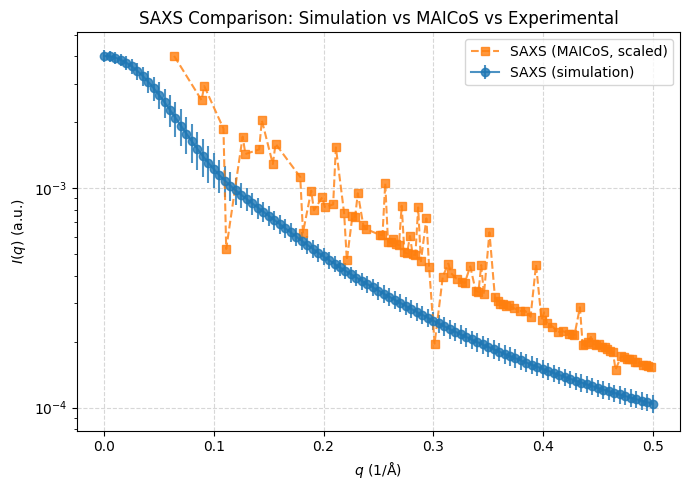

KRS1-72_salt [['KRS1-72_replica_03_CHARMM36M_2000ns.xtc']] 138
[]


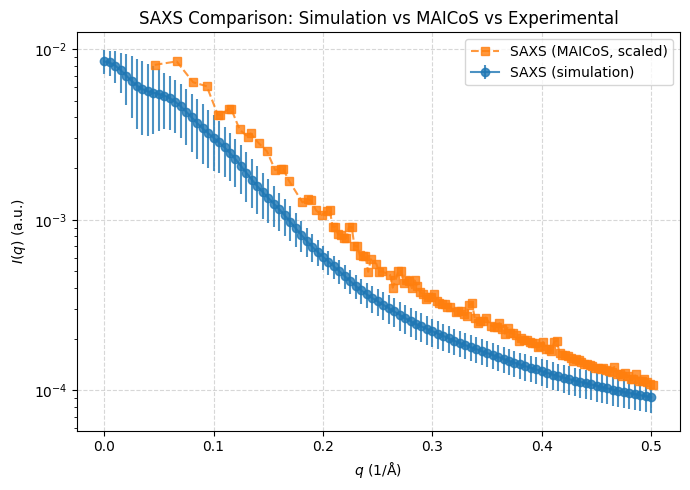

asyn_salt [['aSyn_replica_04_CHARMM36M_2000ns.xtc']] 103
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.42e-06, offset=0.000437
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.85e-05, offset=0.00105
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=7.11e-07, offset=0.000501


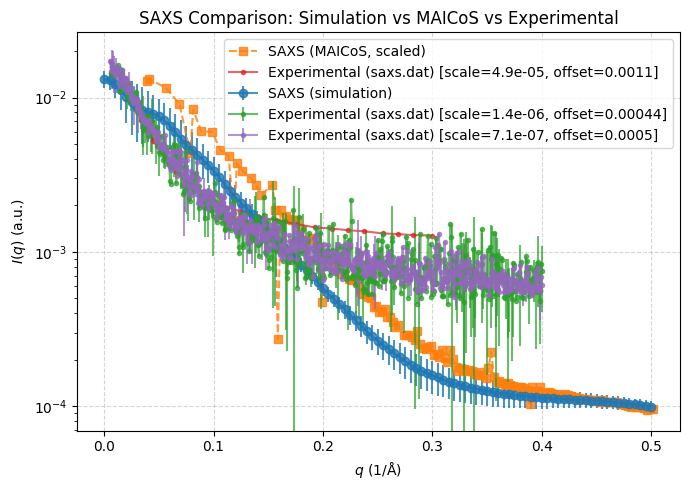

asyn [['replica_03_AMBER99SBWS_md_2000ns.xtc']] 52
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.05e-06, offset=0.000129
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=3.81e-05, offset=0.00039
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=5.23e-07, offset=0.000177


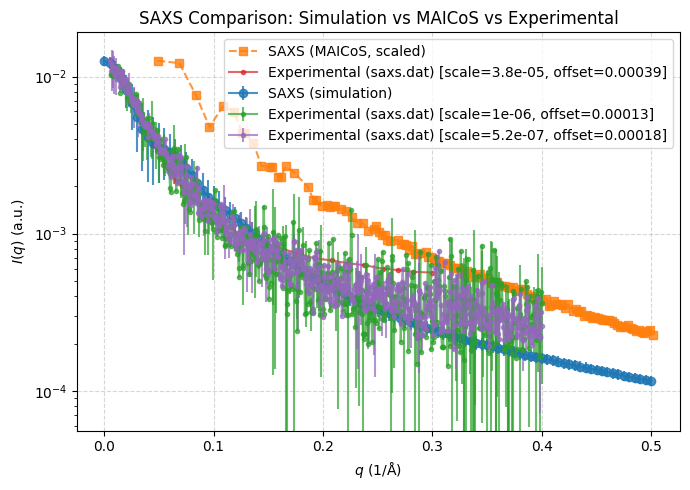

asyn [['replica_02_AMBER99SB-DISP_md_2000ns.xtc']] 53
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.21e-06, offset=0.000274
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.24e-05, offset=0.000688
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=6.03e-07, offset=0.000329


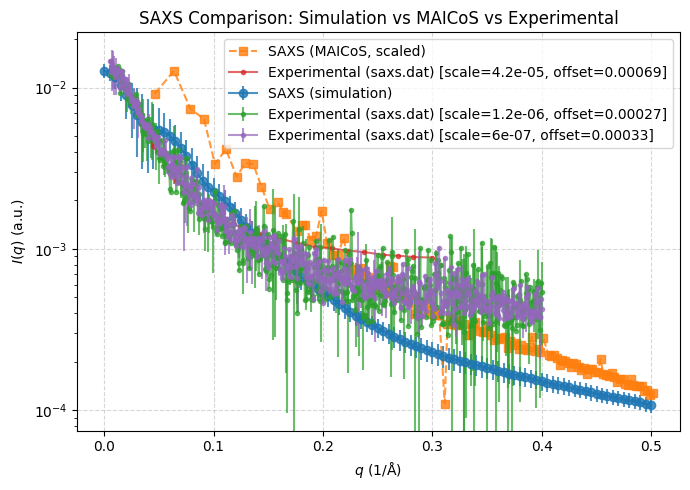

asyn [['replica_02_CHARMM36M_md_2000ns.xtc']] 57
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1e-06, offset=0.000323
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=3.53e-05, offset=0.000685
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=4.99e-07, offset=0.000371


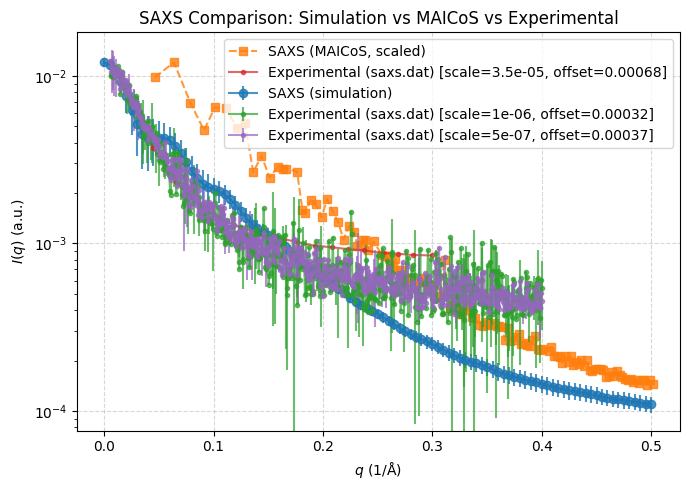

asyn [['replica_01_CHARMM36M_md_2000ns.xtc']] 61
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.38e-06, offset=0.000418
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.74e-05, offset=0.000991
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=6.91e-07, offset=0.00048


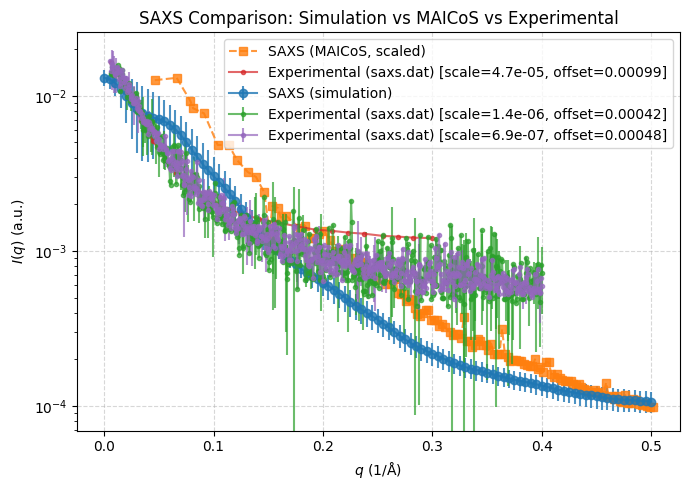

asyn [['replica_02_DESAMBER_md_2000ns.xtc']] 62
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.51e-06, offset=0.0004
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=5.19e-05, offset=0.001
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=7.54e-07, offset=0.000466


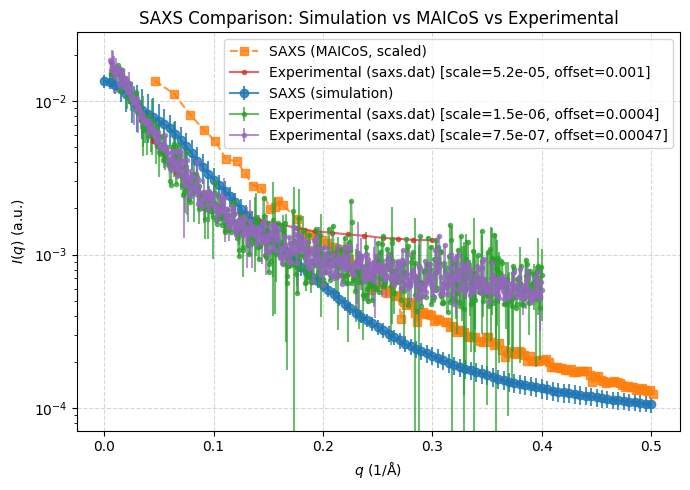

asyn [['replica_02_AMBER99SBWS_md_2000ns.xtc']] 63
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.39e-06, offset=0.000155
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.91e-05, offset=0.000564
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=6.93e-07, offset=0.000215


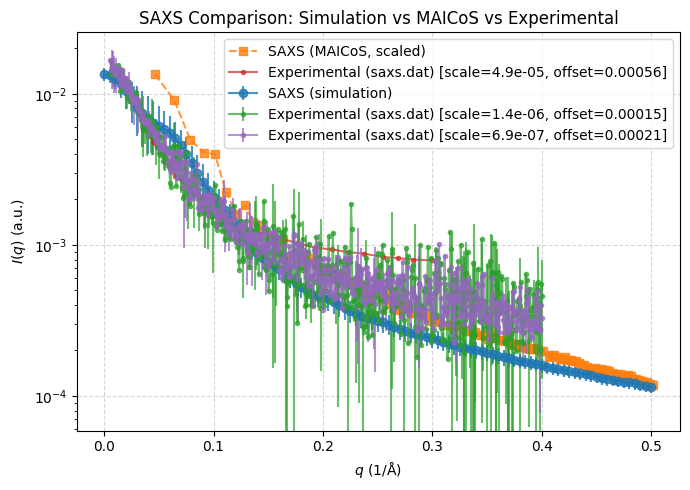

asyn [['replica_04_AMBER99SB-DISP_md_2000ns.xtc']] 65
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.54e-06, offset=0.000274
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=5.37e-05, offset=0.000815
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=7.71e-07, offset=0.000341


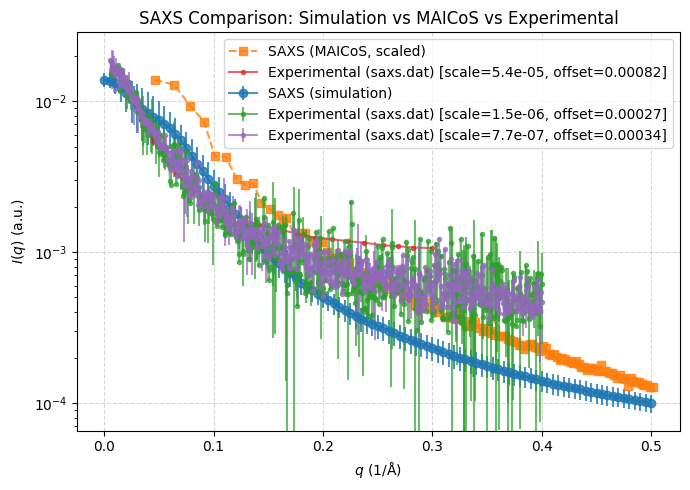

asyn [['replica_01_AMBER99SB-DISP_md_2000ns.xtc']] 66
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.45e-06, offset=0.000299
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=5.04e-05, offset=0.000821
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=7.24e-07, offset=0.000363


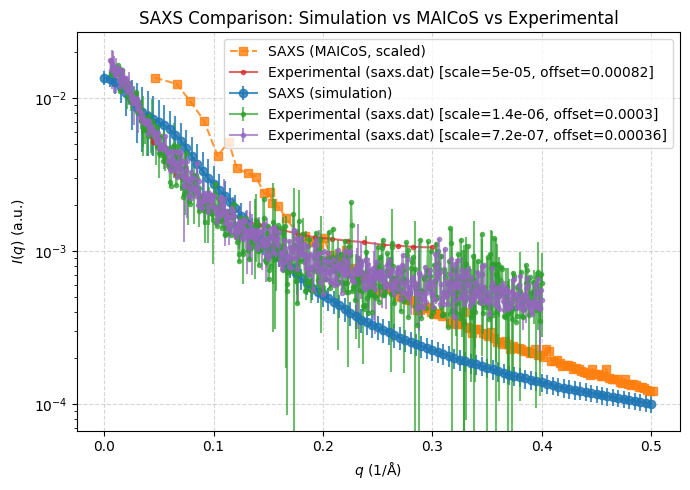

asyn [['replica_04_AMBER99SBWS_md_2000ns.xtc']] 69
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.62e-06, offset=0.000177
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=5.69e-05, offset=0.000689
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=8.1e-07, offset=0.000246


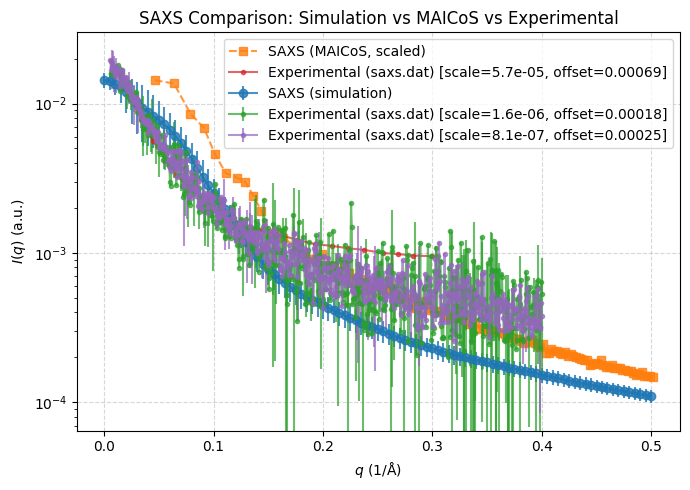

asyn [['replica_01_DESAMBER_md_2000ns.xtc']] 71
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.37e-06, offset=0.000443
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.68e-05, offset=0.00103
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=6.83e-07, offset=0.000504


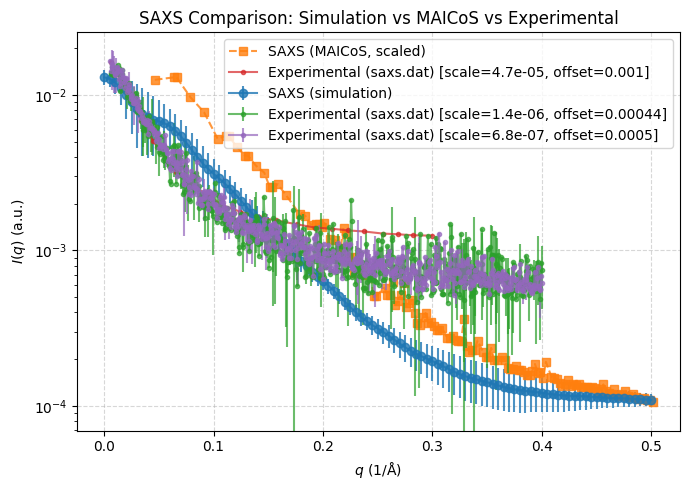

wrapping silk (AcSp1) [['model01_AMBER03WS_md_2000ns.xtc']] 184
[]


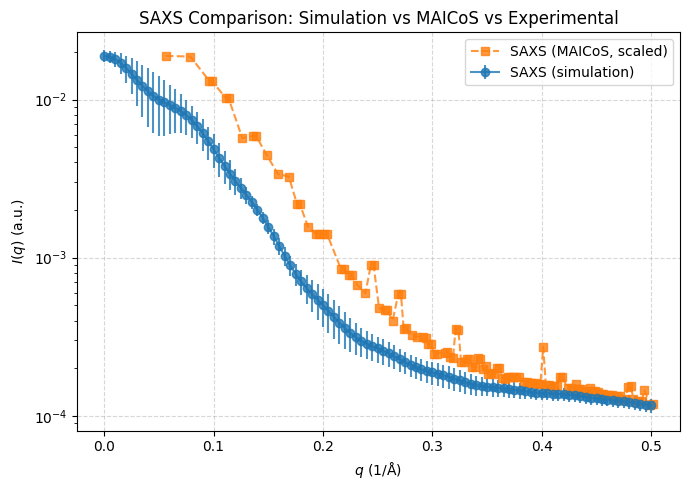

asyn [['replica_05_AMBER99SB-DISP_md_2000ns.xtc']] 73
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.3e-06, offset=0.000265
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.54e-05, offset=0.000718
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=6.47e-07, offset=0.000324


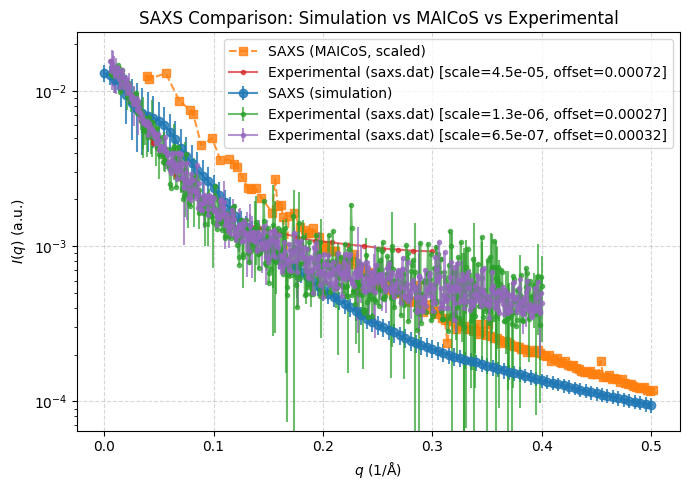

asyn [['replica_03_CHARMM36M_md_2000ns.xtc']] 74
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.56e-06, offset=0.000535
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=5.28e-05, offset=0.00126
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=7.84e-07, offset=0.000603


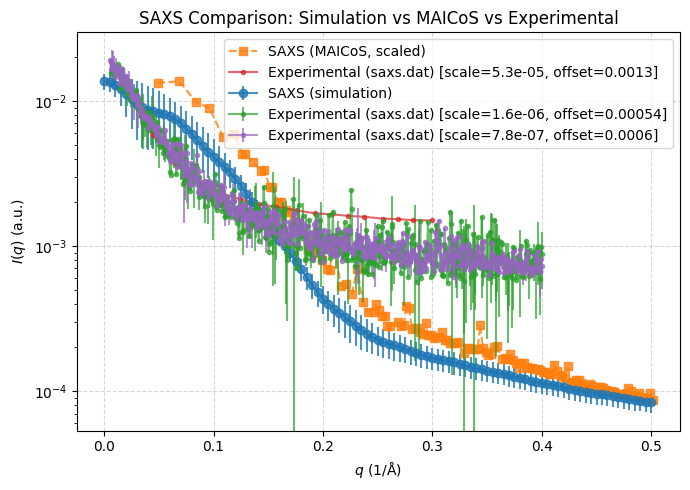

asyn [['replica_03_DESAMBER_md_2000ns.xtc']] 76
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.48e-06, offset=0.000473
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=5.04e-05, offset=0.00112
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=7.4e-07, offset=0.000538


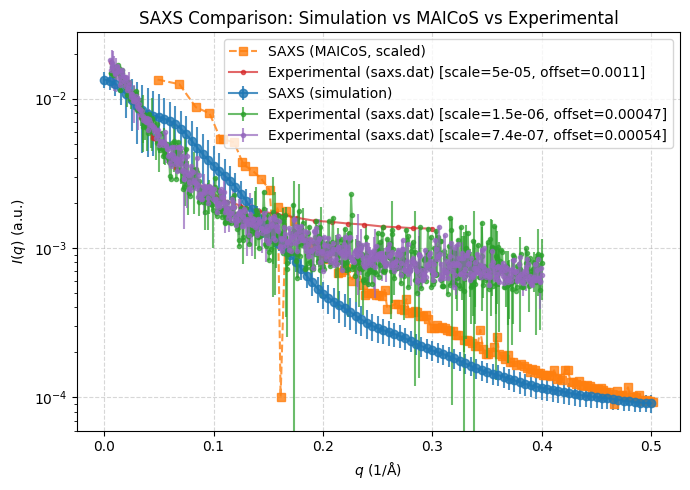

asyn [['replica_04_AMBER03WS_md_2000ns.xtc']] 77
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.6e-06, offset=0.000274
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=5.56e-05, offset=0.000849
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=8.01e-07, offset=0.000343


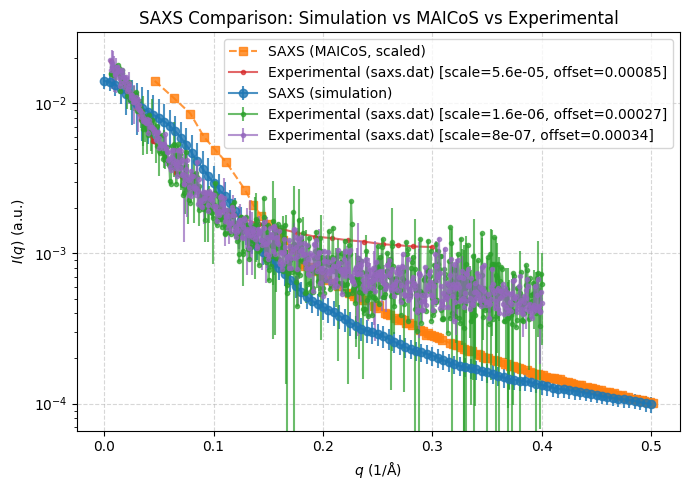

asyn [['replica_03_AMBER03WS_md_2000ns.xtc']] 81
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.45e-06, offset=0.000342
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=5.01e-05, offset=0.000903
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=7.26e-07, offset=0.000405


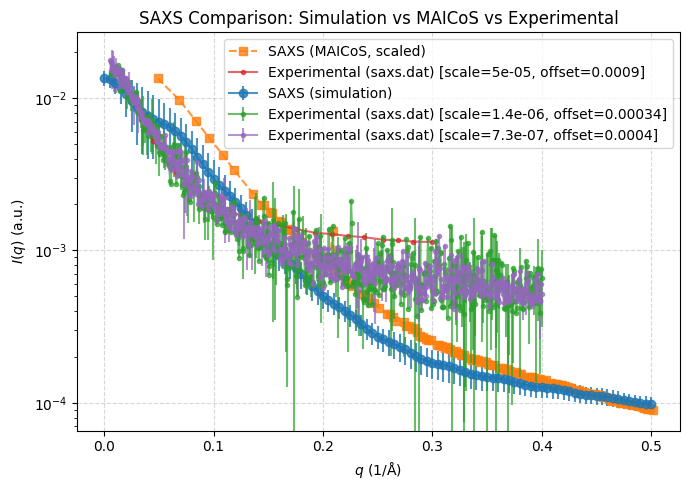

KRS1-72 [['replica_01_AMBER03WS_md_2000ns.xtc']] 99
[]


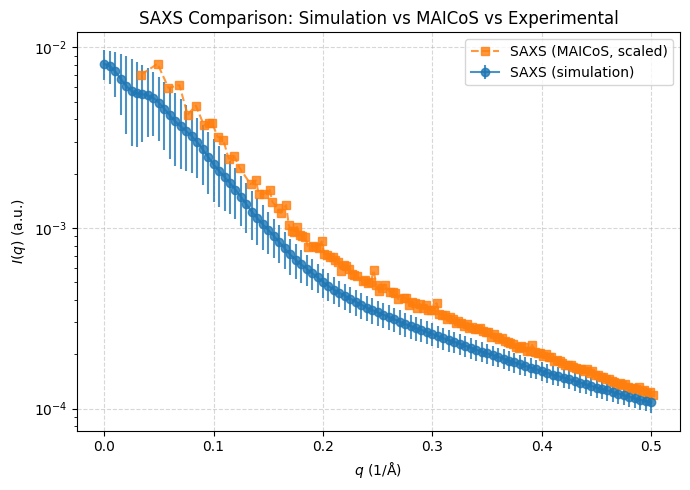

ChiZ1-64 [['replica_01_AMBER03WS_md_1500ns.xtc']] 100
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.3390/biom10060946/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.3390/biom10060946/saxs.dat: scale=1.09, offset=-0.000161


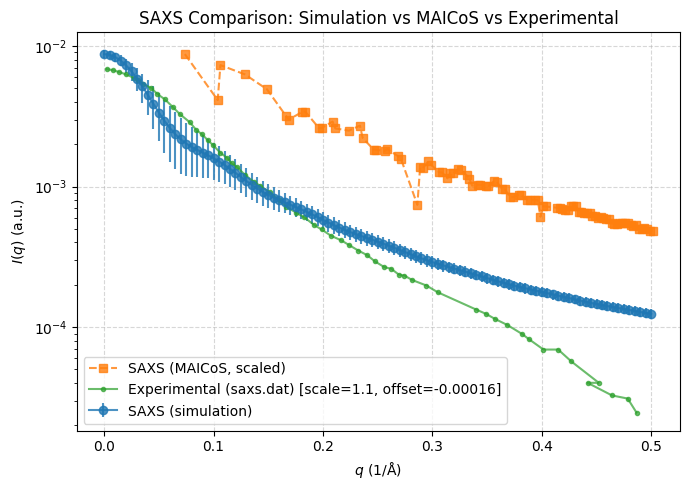

asyn [['replica_05_AMBER99SBWS_md_2000ns.xtc']] 86
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.92e-06, offset=0.000193
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=6.7e-05, offset=0.000827
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=9.62e-07, offset=0.000274


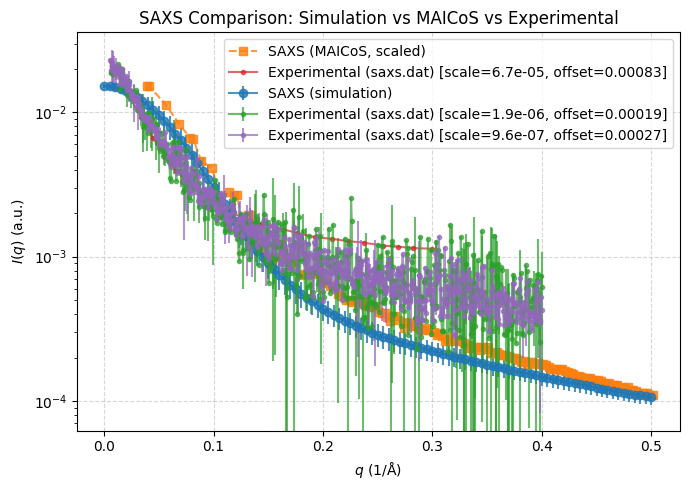

asyn [['replica_02_AMBER03WS_md_2000ns.xtc']] 87
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.41e-06, offset=0.000324
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.9e-05, offset=0.000855
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=7.07e-07, offset=0.000387


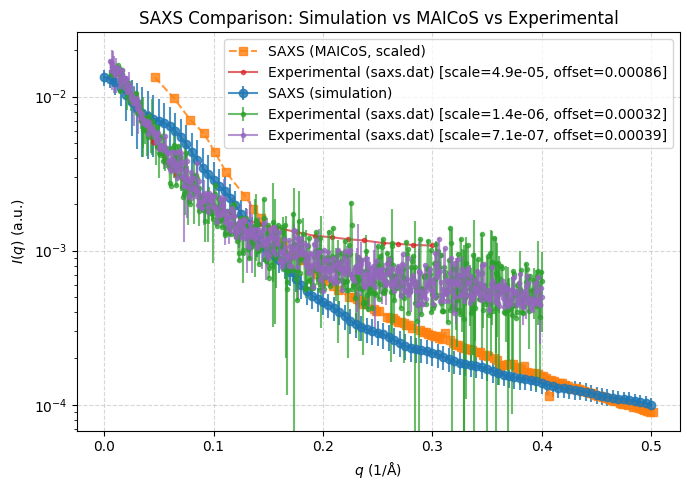

asyn [['replica_05_CHARMM36M_md_2000ns.xtc']] 88
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.41e-06, offset=0.000433
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.81e-05, offset=0.00105
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=7.07e-07, offset=0.000496


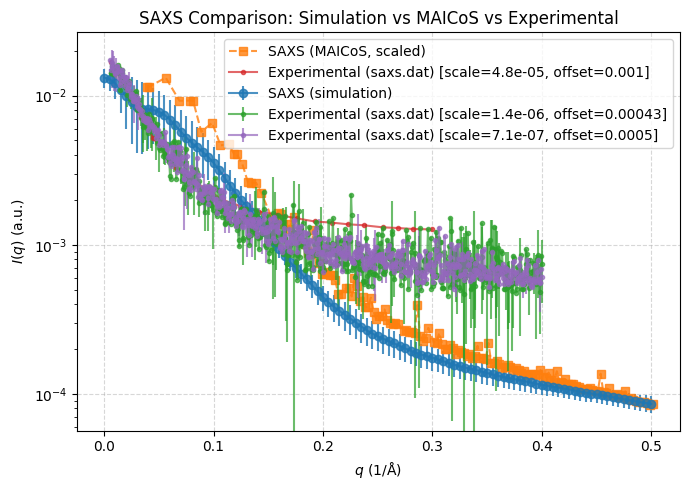

asyn [['replica_03_AMBER99SB-DISP_md_2000ns.xtc']] 89
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.32e-06, offset=0.000302
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.6e-05, offset=0.00078
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=6.59e-07, offset=0.00036


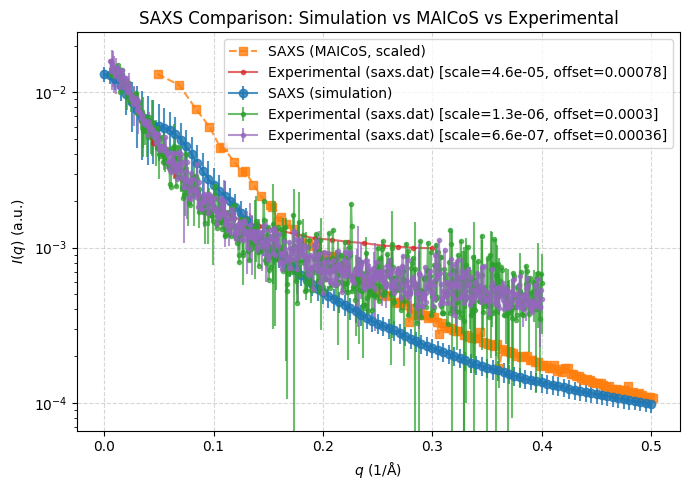

asyn [['replica_04_CHARMM36M_md_2000ns.xtc']] 90
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.16e-06, offset=0.000268
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.1e-05, offset=0.000666
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=5.8e-07, offset=0.000321


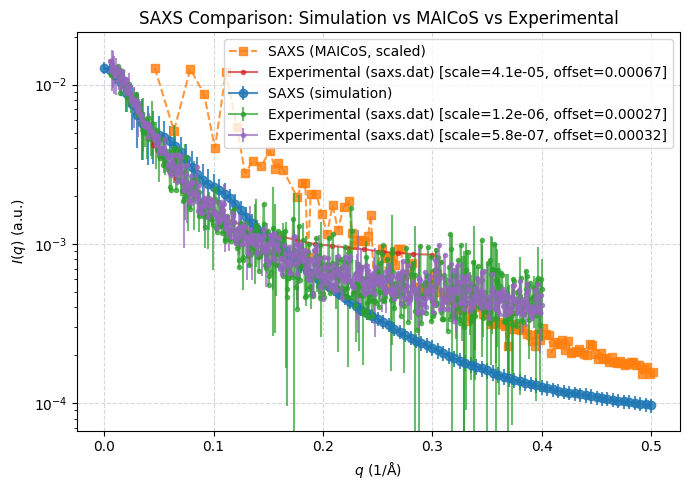

asyn [['replica_05_DESAMBER_md_2000ns.xtc']] 91
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.57e-06, offset=0.000355
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=5.4e-05, offset=0.00097
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=7.86e-07, offset=0.000423


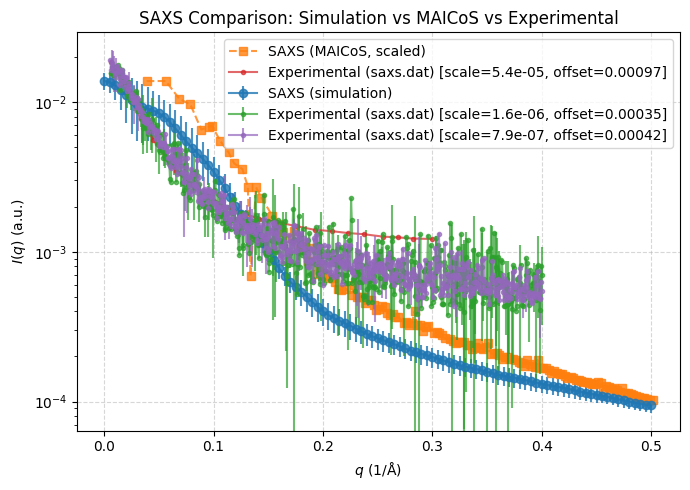

asyn [['replica_05_AMBER03WS_md_2000ns.xtc']] 92
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.37e-06, offset=0.00024
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.79e-05, offset=0.000705
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=6.84e-07, offset=0.000301


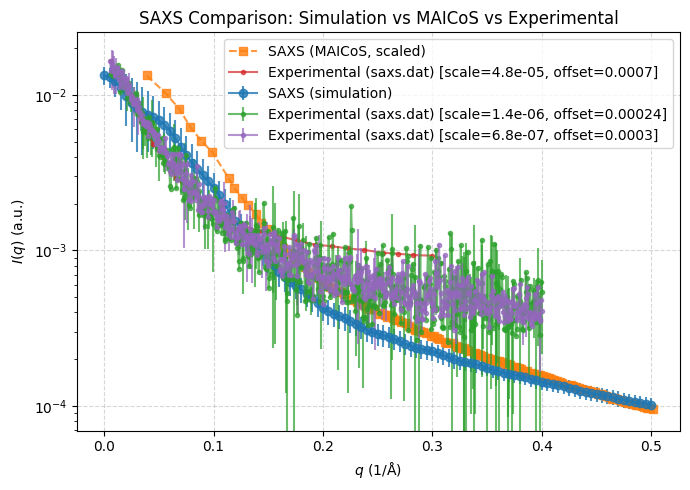

asyn [['replica_04_DESAMBER_md_2000ns.xtc']] 93
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.34e-06, offset=0.000335
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=4.65e-05, offset=0.000847
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=6.7e-07, offset=0.000395


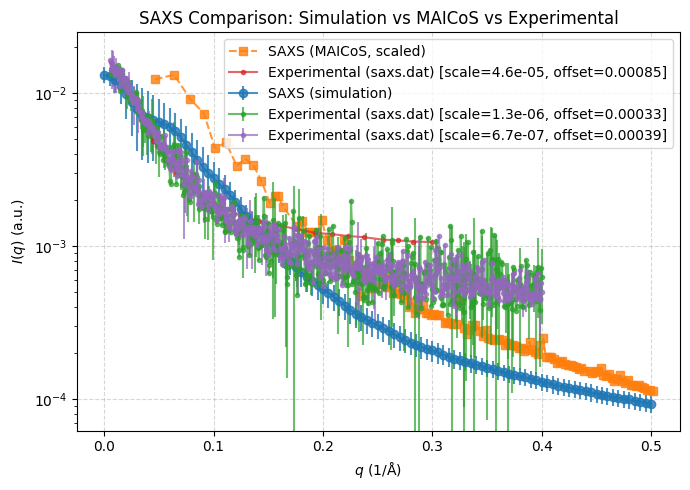

asyn [['replica_01_AMBER03WS_md_2000ns.xtc']] 102
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.47e-06, offset=0.00024
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=5.14e-05, offset=0.000742
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=7.35e-07, offset=0.000304


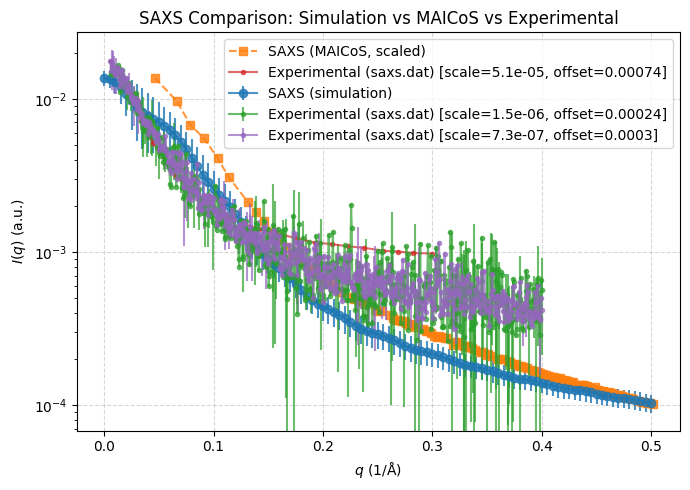

EN2 [['md2_EN2_amber99SBws_model1_nojump.xtc']] 42
[]


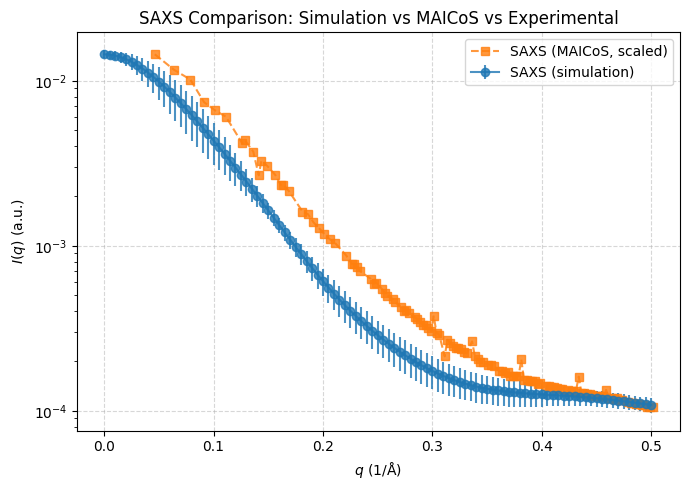

icl2 [['replica_01_AMBER03WS_md_2000ns.xtc']] 101
[]


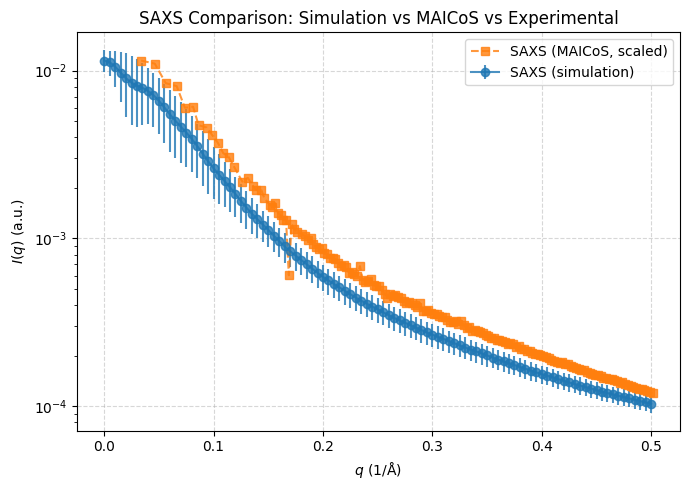

Calmodulin [['md_calmodulin_DESamber_model10_nojump.xtc']] 51
[]


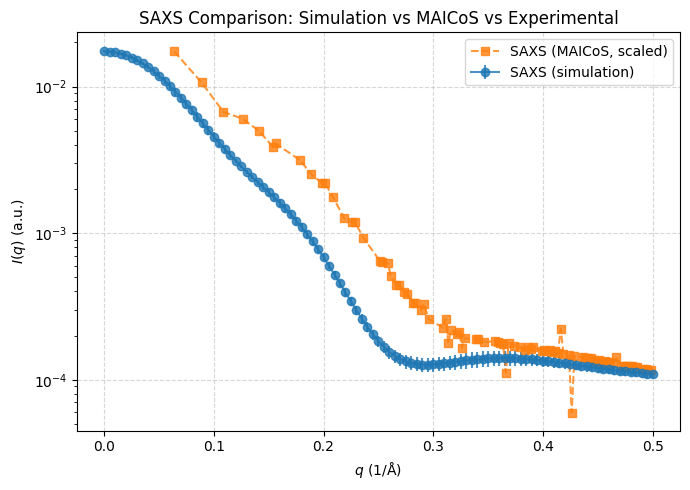

asyn [['replica_01_AMBER99SBWS_md_2000ns.xtc']] 98
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=1.79e-06, offset=0.000148
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=6.28e-05, offset=0.000703
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=8.95e-07, offset=0.000224


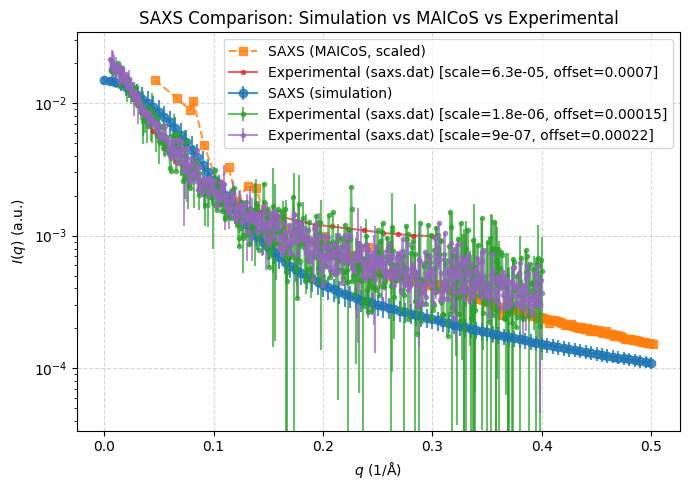

In [5]:
for system in systems:
    SAXS_file = databankPath + 'Data/Simulations/' + system['path'] + 'SAXS.yaml'
    SAXS_MAICOS_file = databankPath + 'Data/Simulations/' + system['path'] + 'SAXS_MAICoS.yaml'
    if os.path.exists(SAXS_file) and os.path.exists(SAXS_MAICOS_file):
        print(system['SYSTEM'], system['TRJ'], system['ID'])
        exp_files = []
        for exp_path in system['EXPERIMENT']['saxs']['path']:
            exp_file_path = databankPath + 'Data/Experiments/saxs/' + exp_path + '/saxs.dat'
            exp_files.append(exp_file_path)
        print(exp_files)
        plot_saxs_comparison(SAXS_file, SAXS_MAICOS_file,exp_files)
        
        

In [6]:
import yaml
import numpy as np
import matplotlib.pyplot as plt

def read_saxs_yaml(filename):
    """Read q and I(q) data from a SAXS YAML file with flexible key names."""
    with open(filename, 'r') as f:
        data = yaml.safe_load(f)

    q, I, I_std = [], [], []
    for d in data:
        q_val = d.get('q[1/A]', d.get('q', None))
        if q_val is None:
            continue

        # Try different possible intensity keys
        I_key_candidates = ['mean_I(q)[a.u.]', 'mean_Inten[a.u.]', 'I(q)[a.u.]']
        I_val = None
        for key in I_key_candidates:
            if key in d:
                I_val = d[key]
                break
        if I_val is None:
            continue

        # Optional standard deviation
        sd_val = d.get('sd_I(q)[a.u.]', d.get('sd_Inten[a.u.]', 0.0))
        q.append(q_val)
        I.append(I_val)
        I_std.append(sd_val)

    return np.array(q), np.array(I), np.array(I_std)


def read_experimental_saxs(filename):
    """
    Read experimental SAXS data file:
    Columns: q(1/nm), I(q), [error] (error optional)
    """
    q, I, err = [], [], []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            # Skip headers and empty lines
            if not line or not (line[0].isdigit() or line[0] == '.'):
                continue
            parts = line.split()
            try:
                q_val = float(parts[0]) / 10.0  # convert 1/nm → 1/Å
                I_val = float(parts[1])
                if len(parts) >= 3 and float(parts[2]) >= 0:
                    err_val = float(parts[2])
                else:
                    err_val = 0.0
                q.append(q_val)
                I.append(I_val)
                err.append(err_val)
            except ValueError:
                continue

    return np.array(q), np.array(I), np.array(err)


def align_experimental_to_maicos(q_maicos, I_maicos, q_exp, I_exp):
    """Fit experimental data (scale + offset) to MAICoS curve via least squares."""
    # Define overlapping q-range
    q_min, q_max = max(q_maicos.min(), q_exp.min()), min(q_maicos.max(), q_exp.max())
    mask_maicos = (q_maicos >= q_min) & (q_maicos <= q_max)
    mask_exp = (q_exp >= q_min) & (q_exp <= q_max)

    if np.sum(mask_maicos) < 3 or np.sum(mask_exp) < 3:
        return I_exp, 1.0, 0.0  # insufficient overlap

    # Interpolate experimental intensities onto MAICoS q-grid
    I_exp_interp = np.interp(q_maicos[mask_maicos], q_exp[mask_exp], I_exp[mask_exp])

    # Fit: I_maicos ≈ scale * I_exp_interp + offset
    A = np.vstack([I_exp_interp, np.ones_like(I_exp_interp)]).T
    scale, offset = np.linalg.lstsq(A, I_maicos[mask_maicos], rcond=None)[0]

    I_exp_aligned = I_exp * scale + offset
    return I_exp_aligned, scale, offset


def plot_saxs_comparison_to_maicos(saxs_file, maicos_file, experimental_files=None):
    """
    Compare SAXS (reference), MAICoS, and experimental data.
    Aligns experimental intensities to MAICoS using scale + offset fitting.
    """
    # Load simulation data
    q_saxs, I_saxs, I_std = read_saxs_yaml(saxs_file)
    q_maicos, I_maicos, _ = read_saxs_yaml(maicos_file)

    # Normalize MAICoS to SAXS for visual comparison
    scale_maicos = np.max(I_saxs) / np.max(I_maicos) if np.max(I_maicos) > 0 else 1.0
    I_maicos_scaled = I_maicos * scale_maicos

    plt.figure(figsize=(7, 5))

    # Plot reference SAXS
    plt.errorbar(q_saxs, I_saxs, yerr=I_std, fmt='o-', label='SAXS (reference)', alpha=0.8)

    # Plot MAICoS
    plt.plot(q_maicos, I_maicos_scaled, 's--', label='MAICoS (scaled)', alpha=0.8)

    # Plot experimental datasets aligned to MAICoS
    if experimental_files:
        for exp_file in experimental_files:
            q_exp, I_exp, err_exp = read_experimental_saxs(exp_file)
            I_exp_aligned, scale, offset = align_experimental_to_maicos(q_maicos, I_maicos_scaled, q_exp, I_exp)

            label = f"Experimental ({exp_file.split('/')[-1]}) [scale={scale:.2g}, offset={offset:.2g}]"
            if np.any(err_exp > 0):
                plt.errorbar(q_exp, I_exp_aligned, yerr=err_exp * scale, fmt='.-', label=label, alpha=0.7)
            else:
                plt.plot(q_exp, I_exp_aligned, '.-', label=label, alpha=0.7)

            print(f"{exp_file}: scale={scale:.3g}, offset={offset:.3g}")

    #plt.yscale('log')
    plt.xlabel(r"$q$ (1/Å)")
    plt.ylabel(r"$I(q)$ (a.u.)")
    plt.title("SAXS Comparison: MAICoS vs Experimental (Fitted) vs Reference")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


Charged sequence with tris [['cKKEEKVP_Tris_HCl_CaCl2_nowater.xtc']] 285
[]


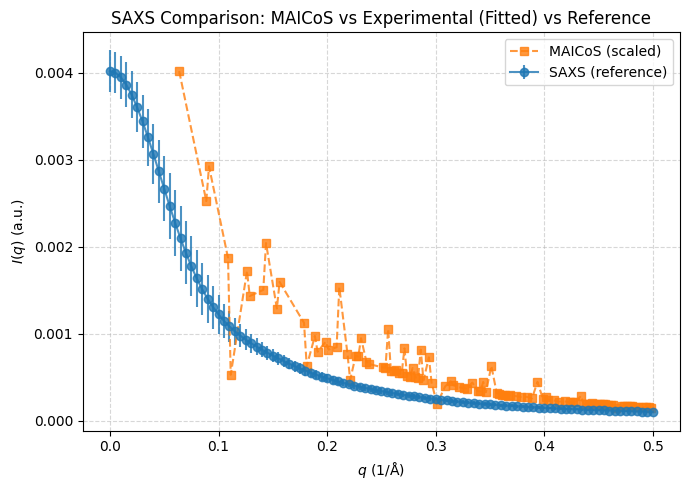

KRS1-72_salt [['KRS1-72_replica_03_CHARMM36M_2000ns.xtc']] 138
[]


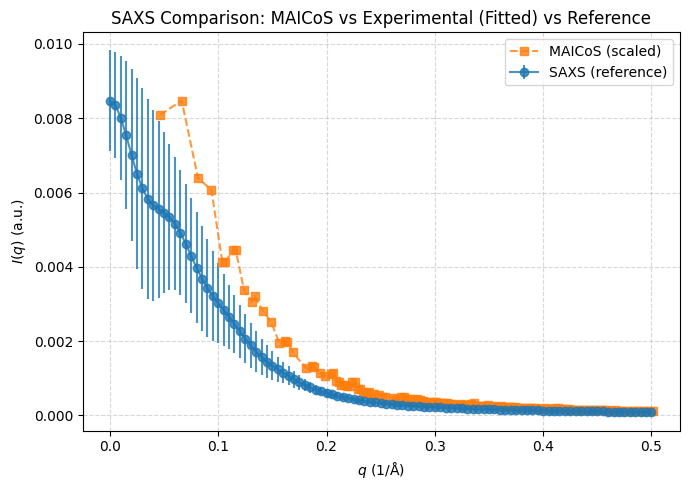

asyn_salt [['aSyn_replica_04_CHARMM36M_2000ns.xtc']] 103
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.45e-06, offset=-0.00032
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000175, offset=-0.000292
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.65e-06, offset=-0.000114


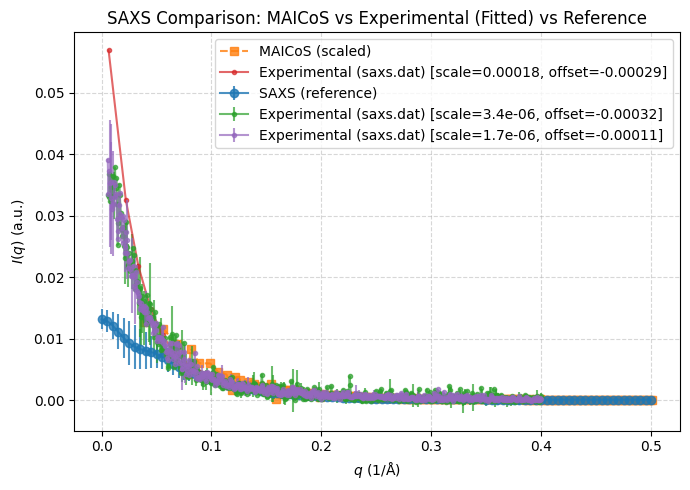

asyn [['replica_03_AMBER99SBWS_md_2000ns.xtc']] 52
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.95e-06, offset=-6.19e-05
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.00024, offset=-0.000184
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2.02e-06, offset=0.000191


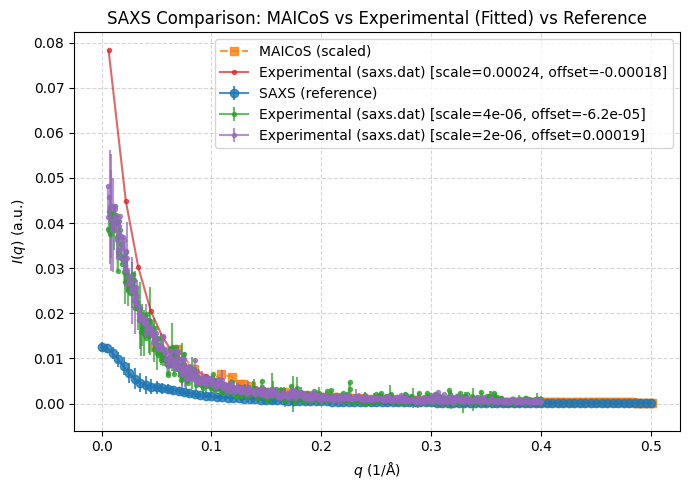

asyn [['replica_02_AMBER99SB-DISP_md_2000ns.xtc']] 53
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.16e-06, offset=-0.00016
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000205, offset=-0.000438
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.69e-06, offset=-2.32e-05


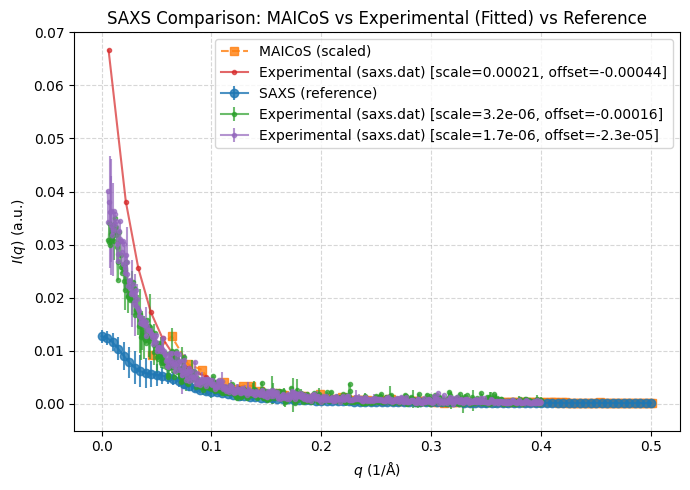

asyn [['replica_02_CHARMM36M_md_2000ns.xtc']] 57
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.28e-06, offset=5.65e-05
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000206, offset=-3.18e-05
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.74e-06, offset=0.000204


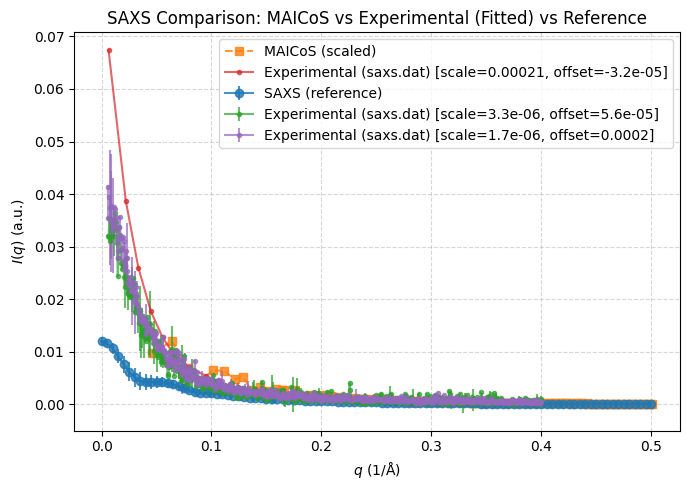

asyn [['replica_01_CHARMM36M_md_2000ns.xtc']] 61
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=4.17e-06, offset=-0.000382
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000258, offset=-0.000778
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2.17e-06, offset=-0.000202


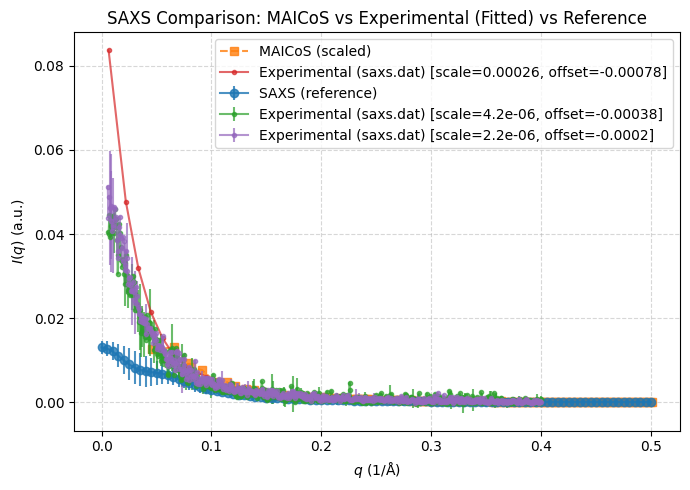

asyn [['replica_02_DESAMBER_md_2000ns.xtc']] 62
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.71e-06, offset=-0.000322
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000241, offset=-0.000665
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.98e-06, offset=-0.000151


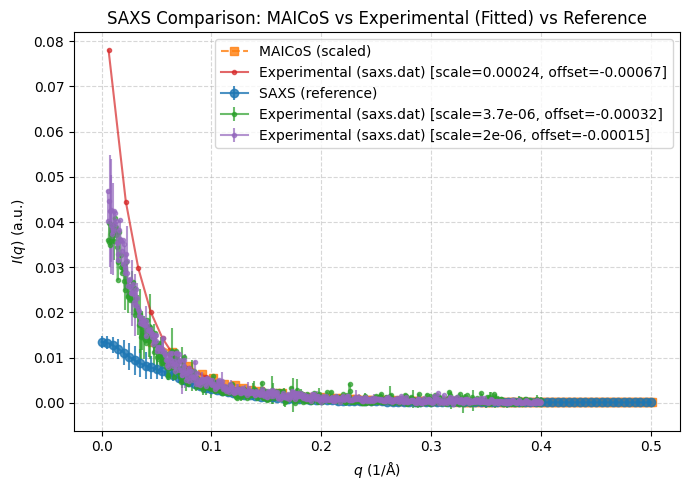

asyn [['replica_02_AMBER99SBWS_md_2000ns.xtc']] 63
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.21e-06, offset=-0.000456
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000203, offset=-0.000872
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.67e-06, offset=-0.00028


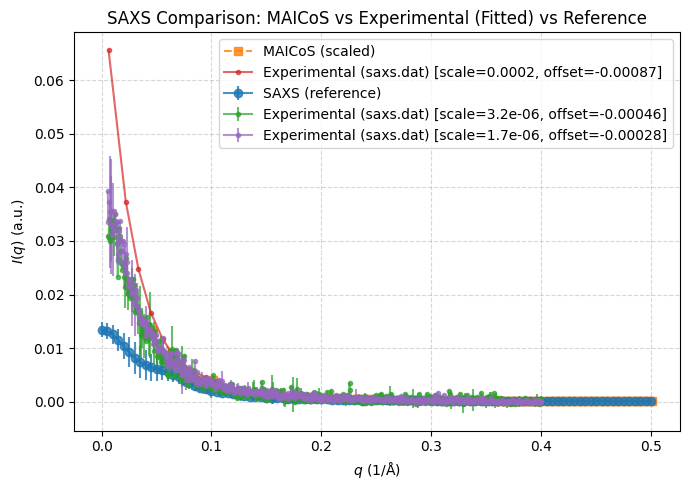

asyn [['replica_04_AMBER99SB-DISP_md_2000ns.xtc']] 65
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.94e-06, offset=-0.000399
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000257, offset=-0.000869
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2.1e-06, offset=-0.000226


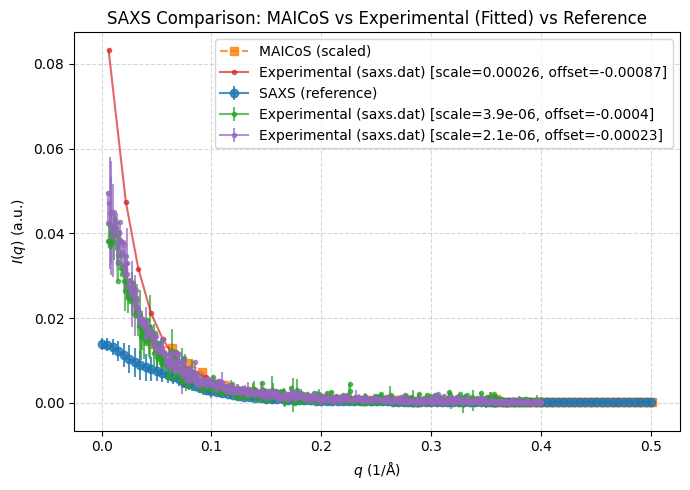

asyn [['replica_01_AMBER99SB-DISP_md_2000ns.xtc']] 66
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=4.12e-06, offset=-0.000401
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.00026, offset=-0.000839
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2.17e-06, offset=-0.000215


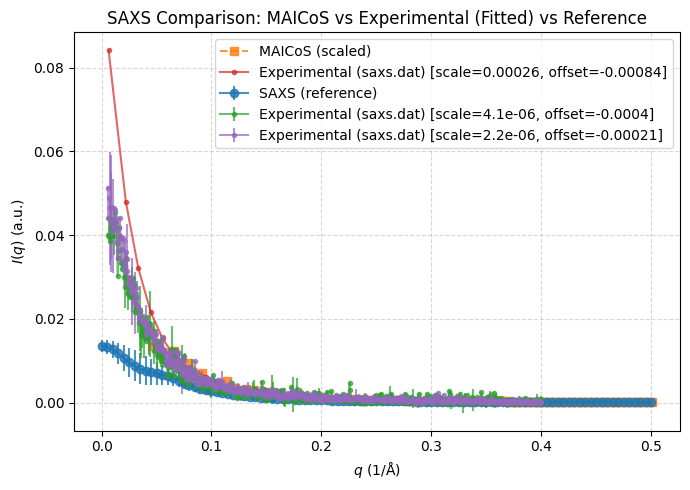

asyn [['replica_04_AMBER99SBWS_md_2000ns.xtc']] 69
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=4.03e-06, offset=-0.000492
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000262, offset=-0.00102
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2.13e-06, offset=-0.000311


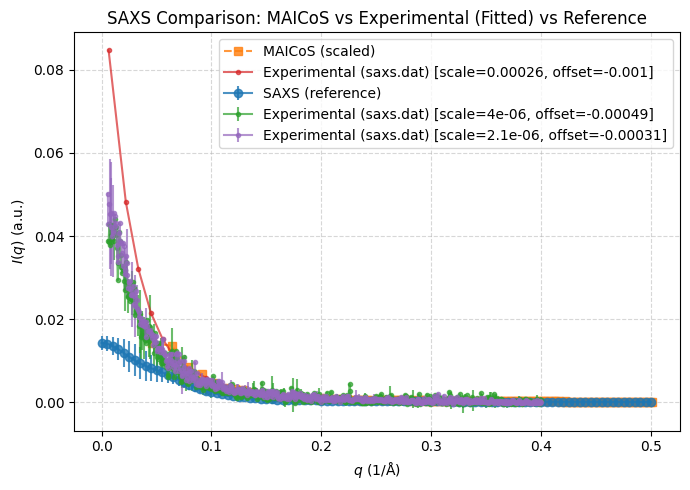

asyn [['replica_01_DESAMBER_md_2000ns.xtc']] 71
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=4.28e-06, offset=-0.000357
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000268, offset=-0.00067
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2.26e-06, offset=-0.000172


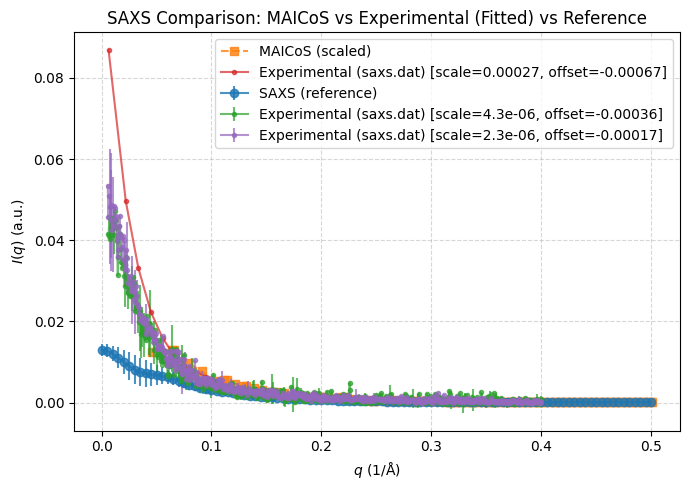

wrapping silk (AcSp1) [['model01_AMBER03WS_md_2000ns.xtc']] 184
[]


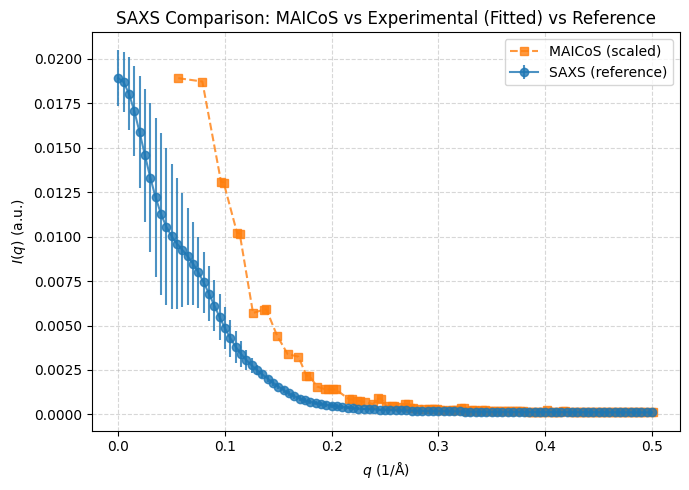

asyn [['replica_05_AMBER99SB-DISP_md_2000ns.xtc']] 73
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.33e-06, offset=-0.000193
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000169, offset=-0.000181
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.6e-06, offset=1.31e-07


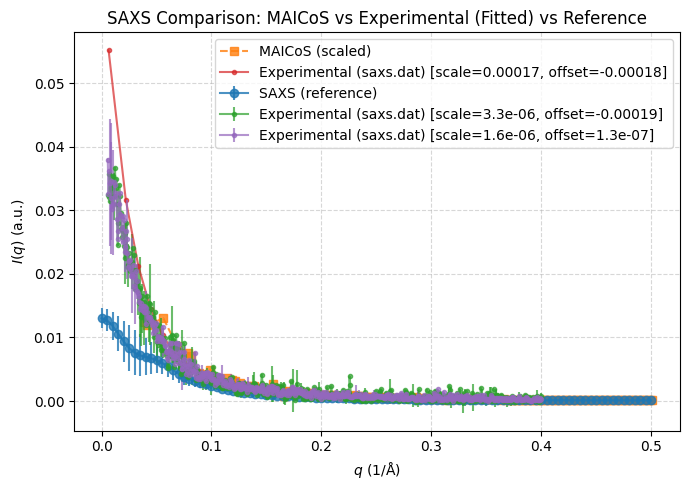

asyn [['replica_03_CHARMM36M_md_2000ns.xtc']] 74
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=4.61e-06, offset=-0.000656
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000293, offset=-0.00106
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2.37e-06, offset=-0.000355


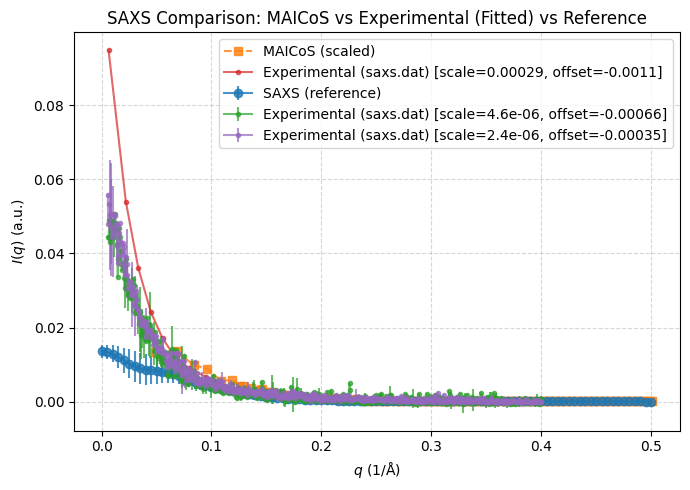

asyn [['replica_03_DESAMBER_md_2000ns.xtc']] 76
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=4.37e-06, offset=-0.000599
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000275, offset=-0.000996
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2.23e-06, offset=-0.000339


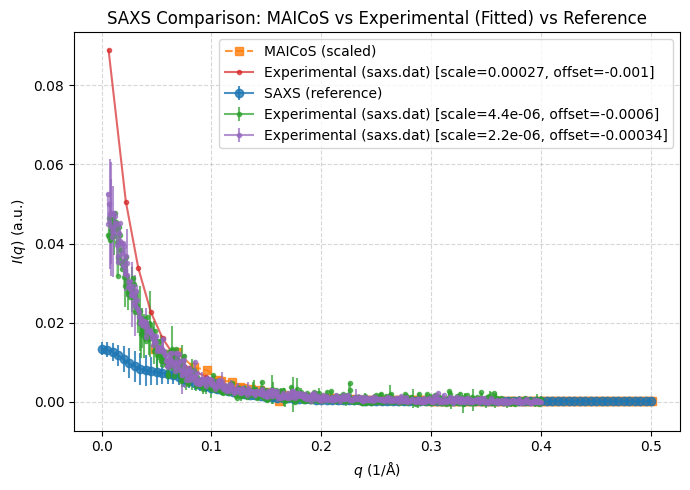

asyn [['replica_04_AMBER03WS_md_2000ns.xtc']] 77
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.74e-06, offset=-0.000568
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000246, offset=-0.00104
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2e-06, offset=-0.000381


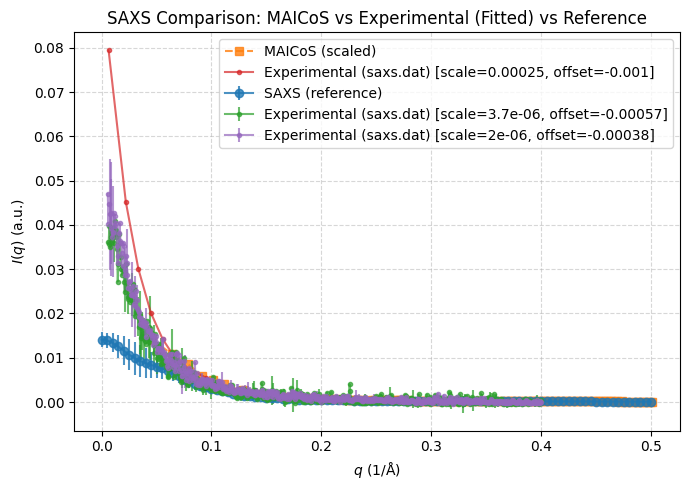

asyn [['replica_03_AMBER03WS_md_2000ns.xtc']] 81
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.77e-06, offset=-0.000608
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000238, offset=-0.00091
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.93e-06, offset=-0.000322


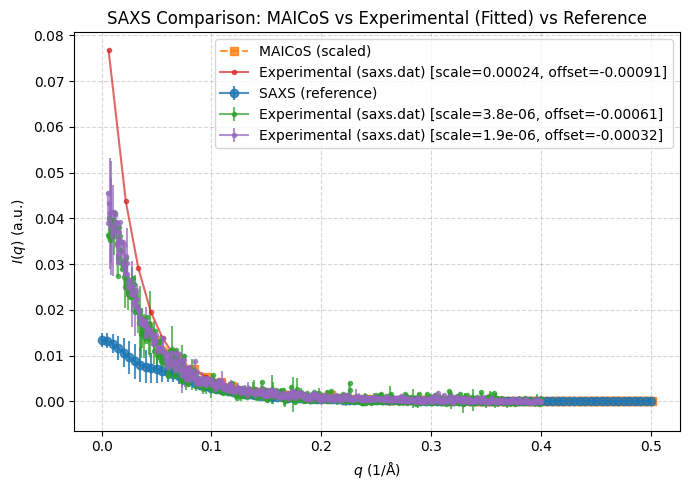

KRS1-72 [['replica_01_AMBER03WS_md_2000ns.xtc']] 99
[]


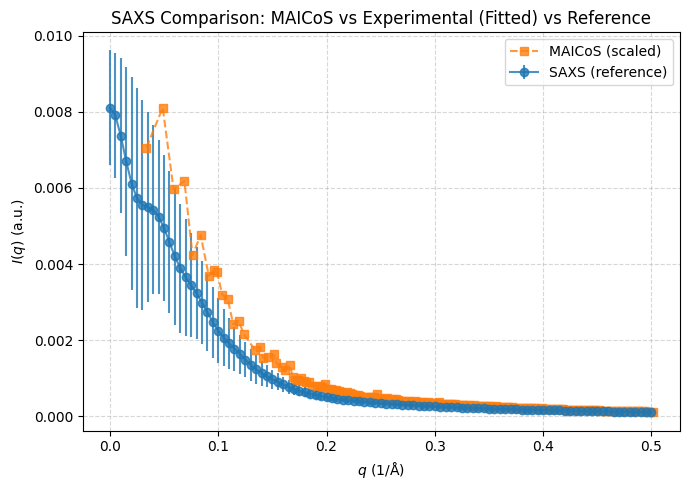

ChiZ1-64 [['replica_01_AMBER03WS_md_1500ns.xtc']] 100
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.3390/biom10060946/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.3390/biom10060946/saxs.dat: scale=3.51, offset=0.000153


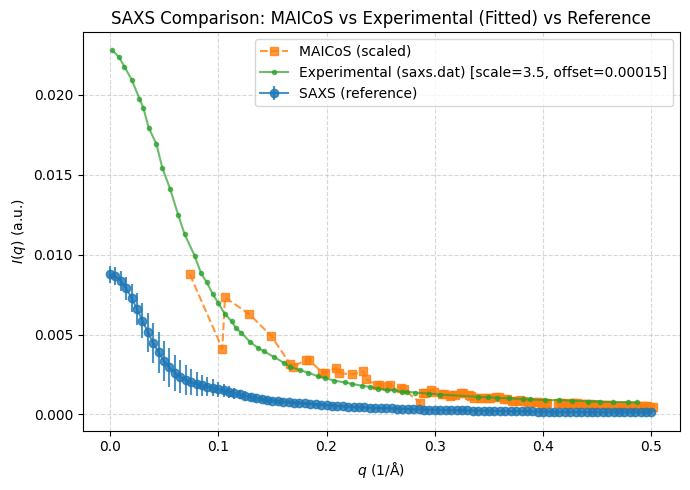

asyn [['replica_05_AMBER99SBWS_md_2000ns.xtc']] 86
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.69e-06, offset=-0.000572
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.00019, offset=-0.000751
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.75e-06, offset=-0.000336


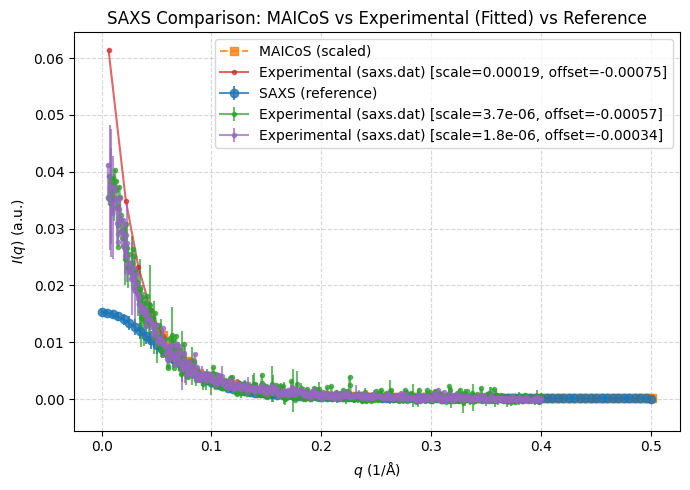

asyn [['replica_02_AMBER03WS_md_2000ns.xtc']] 87
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.46e-06, offset=-0.000519
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000225, offset=-0.000964
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.82e-06, offset=-0.000351


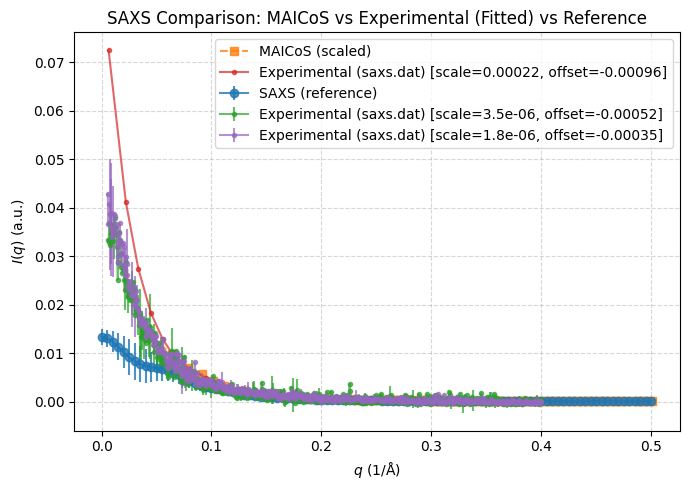

asyn [['replica_05_CHARMM36M_md_2000ns.xtc']] 88
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.44e-06, offset=-0.000295
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000177, offset=-0.000304
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.67e-06, offset=-0.000112


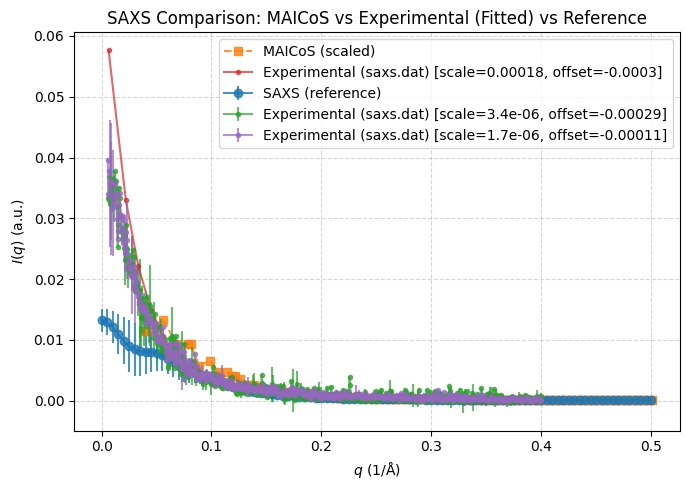

asyn [['replica_03_AMBER99SB-DISP_md_2000ns.xtc']] 89
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.94e-06, offset=-0.000523
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000247, offset=-0.000877
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2e-06, offset=-0.000271


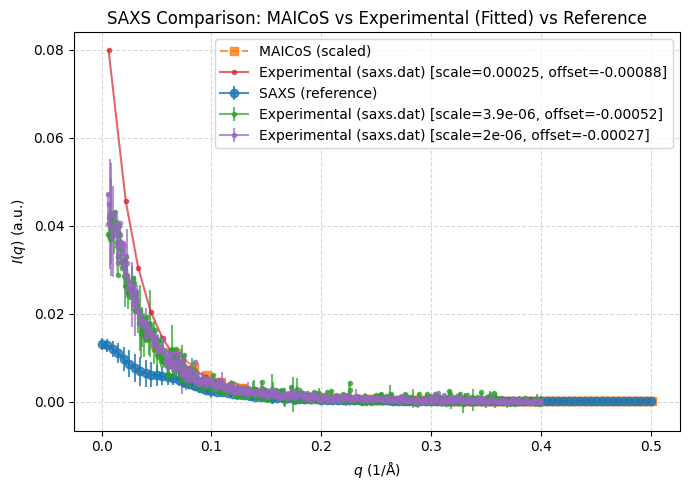

asyn [['replica_04_CHARMM36M_md_2000ns.xtc']] 90
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.27e-06, offset=0.000169
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000222, offset=-3.97e-06
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.87e-06, offset=0.00024


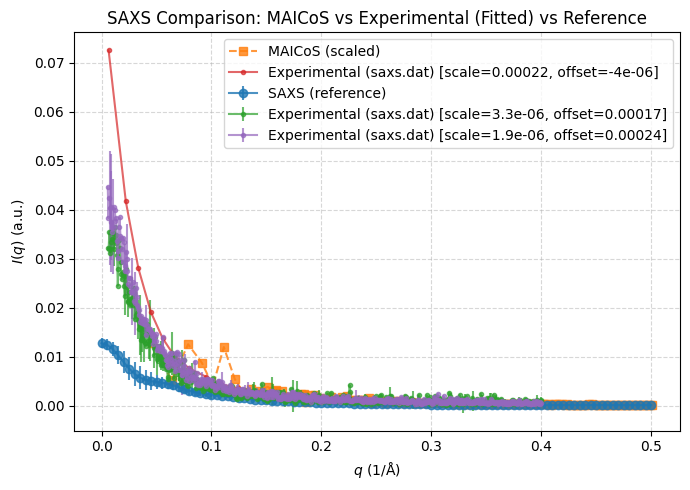

asyn [['replica_05_DESAMBER_md_2000ns.xtc']] 91
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=4.5e-06, offset=-0.000668
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000217, offset=-0.000642
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2e-06, offset=-0.000279


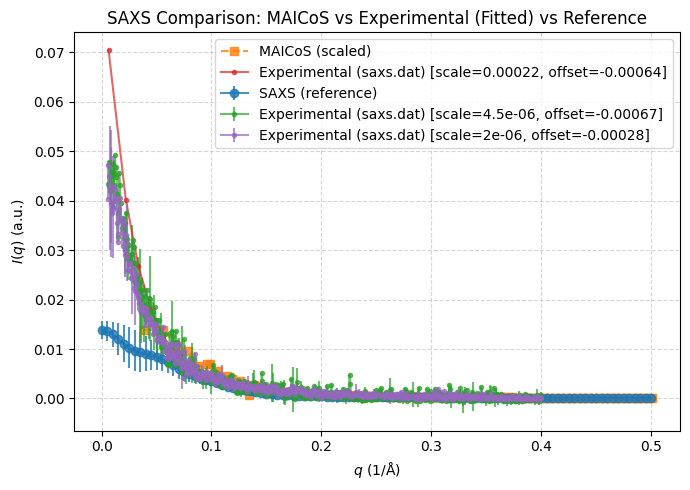

asyn [['replica_05_AMBER03WS_md_2000ns.xtc']] 92
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.62e-06, offset=-0.000557
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000174, offset=-0.000588
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.61e-06, offset=-0.000247


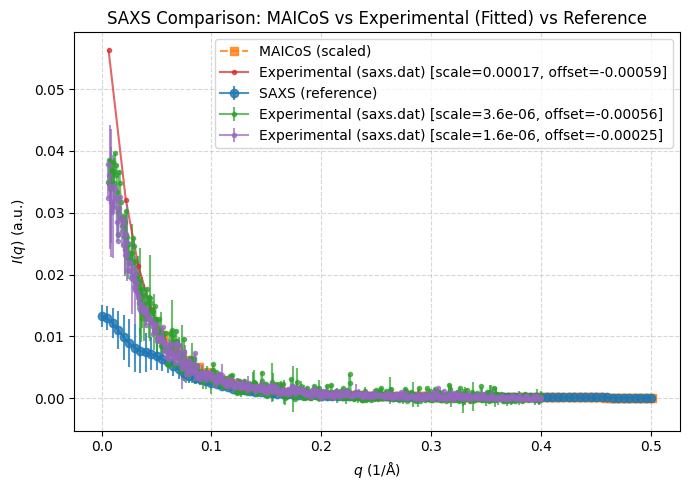

asyn [['replica_04_DESAMBER_md_2000ns.xtc']] 93
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.76e-06, offset=-0.000359
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000248, offset=-0.000757
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2.03e-06, offset=-0.000191


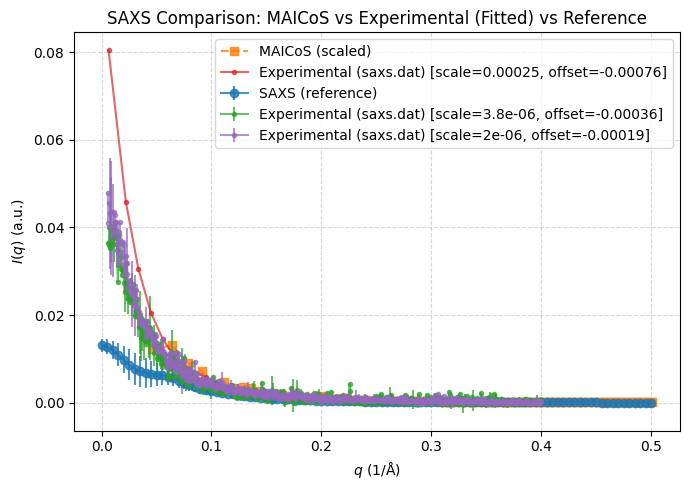

asyn [['replica_01_AMBER03WS_md_2000ns.xtc']] 102
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=3.69e-06, offset=-0.000513
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.00023, offset=-0.000998
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=1.9e-06, offset=-0.000356


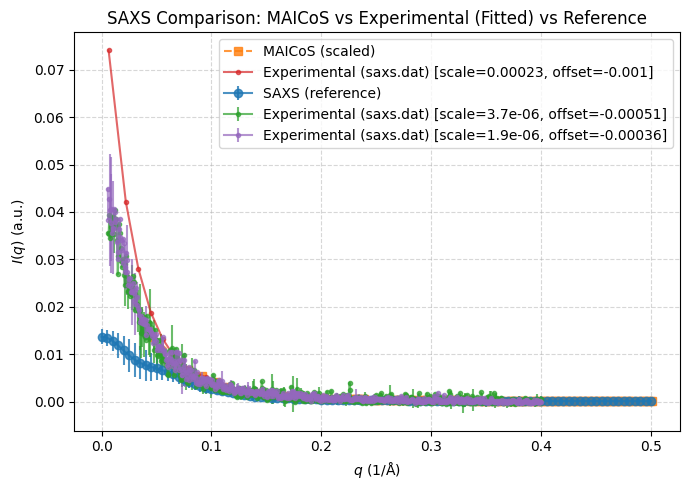

EN2 [['md2_EN2_amber99SBws_model1_nojump.xtc']] 42
[]


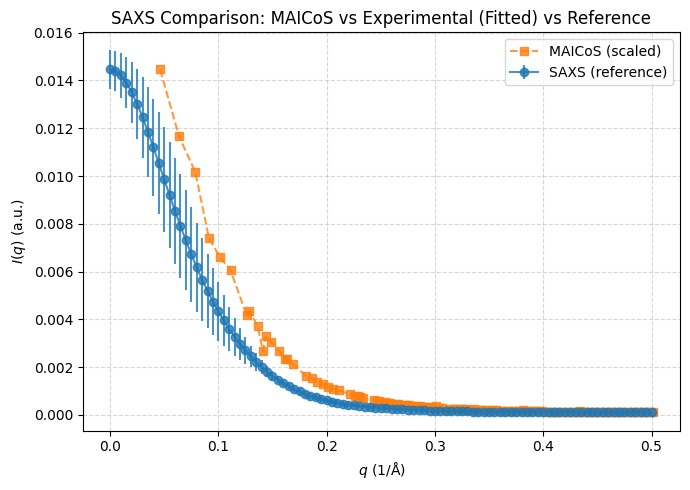

icl2 [['replica_01_AMBER03WS_md_2000ns.xtc']] 101
[]


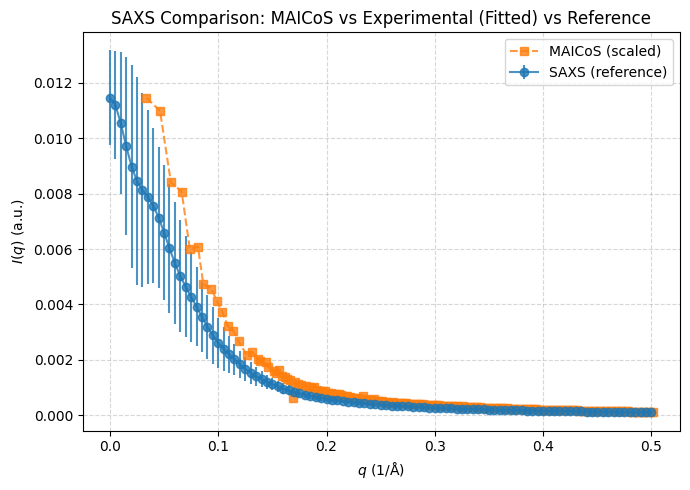

Calmodulin [['md_calmodulin_DESamber_model10_nojump.xtc']] 51
[]


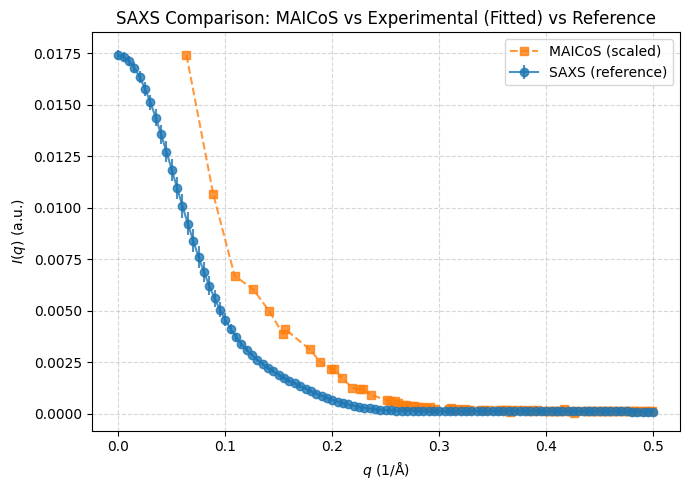

asyn [['replica_01_AMBER99SBWS_md_2000ns.xtc']] 98
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat: scale=4.16e-06, offset=-0.000534
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat: scale=0.000258, offset=-0.00111
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat: scale=2.16e-06, offset=-0.000346


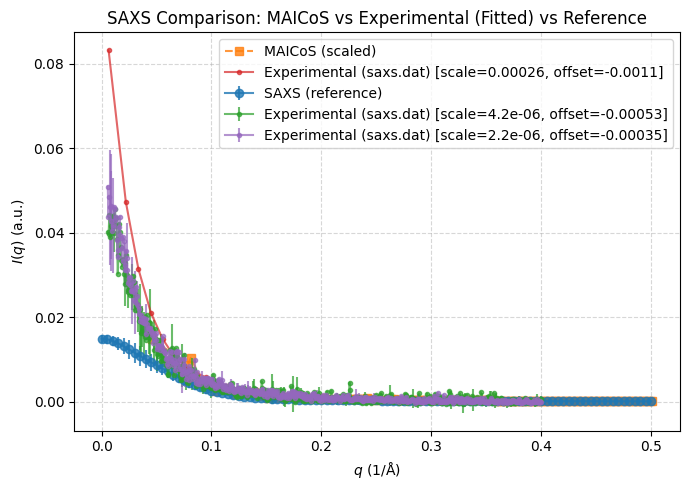

In [7]:
for system in systems:
    SAXS_file = databankPath + 'Data/Simulations/' + system['path'] + 'SAXS.yaml'
    SAXS_MAICOS_file = databankPath + 'Data/Simulations/' + system['path'] + 'SAXS_MAICoS.yaml'
    if os.path.exists(SAXS_file) and os.path.exists(SAXS_MAICOS_file):
        print(system['SYSTEM'], system['TRJ'], system['ID'])
        exp_files = []
        for exp_path in system['EXPERIMENT']['saxs']['path']:
            exp_file_path = databankPath + 'Data/Experiments/saxs/' + exp_path + '/saxs.dat'
            exp_files.append(exp_file_path)
        print(exp_files)
        plot_saxs_comparison_to_maicos(SAXS_file, SAXS_MAICOS_file,exp_files)
        
        

In [8]:
import yaml
import numpy as np
import pandas as pd

# ---------- Data readers ----------

def read_saxs_yaml(filename):
    """Read q and I(q) data from a SAXS YAML file with flexible key names."""
    with open(filename, 'r') as f:
        data = yaml.safe_load(f)

    q, I, I_std = [], [], []
    for d in data:
        q_val = d.get('q[1/A]', d.get('q', None))
        if q_val is None:
            continue

        I_key_candidates = ['mean_I(q)[a.u.]', 'mean_Inten[a.u.]', 'I(q)[a.u.]']
        I_val = next((d[k] for k in I_key_candidates if k in d), None)
        if I_val is None:
            continue

        sd_val = d.get('sd_I(q)[a.u.]', d.get('sd_Inten[a.u.]', 0.0))
        q.append(q_val)
        I.append(I_val)
        I_std.append(sd_val)

    return np.array(q), np.array(I), np.array(I_std)


def read_experimental_saxs(filename):
    """Read experimental SAXS data file (q in 1/nm → converted to 1/Å)."""
    q, I, err = [], [], []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or not (line[0].isdigit() or line[0] == '.'):
                continue
            parts = line.split()
            try:
                q_val = float(parts[0]) / 10.0  # 1/nm → 1/Å
                I_val = float(parts[1])
                if len(parts) >= 3 and float(parts[2]) >= 0:
                    err_val = float(parts[2])
                else:
                    err_val = 0.0
                q.append(q_val)
                I.append(I_val)
                err.append(err_val)
            except ValueError:
                continue
    return np.array(q), np.array(I), np.array(err)


# ---------- RMSD computation helper ----------

def compute_rmsd(q_sim, I_sim, q_exp, I_exp, fit=True):
    """Compute RMSD between simulation and experimental data."""
    # Identify overlapping q-range
    q_min, q_max = max(q_sim.min(), q_exp.min()), min(q_sim.max(), q_exp.max())
    mask_sim = (q_sim >= q_min) & (q_sim <= q_max)
    mask_exp = (q_exp >= q_min) & (q_exp <= q_max)

    if np.sum(mask_sim) < 3 or np.sum(mask_exp) < 3:
        raise ValueError("Insufficient overlap between datasets.")

    # Interpolate experimental data onto sim q-grid
    I_exp_interp = np.interp(q_sim[mask_sim], q_exp[mask_exp], I_exp[mask_exp])

    # Fit (optional)
    if fit:
        A = np.vstack([I_exp_interp, np.ones_like(I_exp_interp)]).T
        scale, offset = np.linalg.lstsq(A, I_sim[mask_sim], rcond=None)[0]
        I_exp_interp = I_exp_interp * scale + offset
    else:
        scale, offset = 1.0, 0.0

    # Compute RMSD
    diff = I_sim[mask_sim] - I_exp_interp
    rmsd = np.sqrt(np.mean(diff**2))

    return rmsd, scale, offset


# ---------- Main RMSD analysis functions ----------

def rmsd_saxs_vs_experiments(saxs_file, exp_files, fit=True):
    """Compute RMSD between SAXS simulation and a list of experimental data files."""
    q_sim, I_sim, _ = read_saxs_yaml(saxs_file)
    results = []

    for exp_file in exp_files:
        q_exp, I_exp, _ = read_experimental_saxs(exp_file)
        try:
            rmsd, scale, offset = compute_rmsd(q_sim, I_sim, q_exp, I_exp, fit)
            results.append({
                "Simulation": "SAXS",
                "Experiment": exp_file.split("/")[-1],
                "RMSD": rmsd,
                "Scale": scale,
                "Offset": offset
            })
            print(f"[SAXS vs {exp_file}] RMSD={rmsd:.4g}, scale={scale:.3g}, offset={offset:.3g}")
        except ValueError as e:
            print(f"[SAXS vs {exp_file}] Skipped: {e}")

    return pd.DataFrame(results)


def rmsd_maicos_vs_experiments(maicos_file, exp_files, fit=True):
    """Compute RMSD between MAICoS simulation and a list of experimental data files."""
    q_sim, I_sim, _ = read_saxs_yaml(maicos_file)
    results = []

    for exp_file in exp_files:
        q_exp, I_exp, _ = read_experimental_saxs(exp_file)
        try:
            rmsd, scale, offset = compute_rmsd(q_sim, I_sim, q_exp, I_exp, fit)
            results.append({
                "Simulation": "MAICoS",
                "Experiment": exp_file.split("/")[-1],
                "RMSD": rmsd,
                "Scale": scale,
                "Offset": offset
            })
            print(f"[MAICoS vs {exp_file}] RMSD={rmsd:.4g}, scale={scale:.3g}, offset={offset:.3g}")
        except ValueError as e:
            print(f"[MAICoS vs {exp_file}] Skipped: {e}")

    return pd.DataFrame(results)


Charged sequence with tris [['cKKEEKVP_Tris_HCl_CaCl2_nowater.xtc']] 285
[]
Empty DataFrame
Columns: []
Index: []


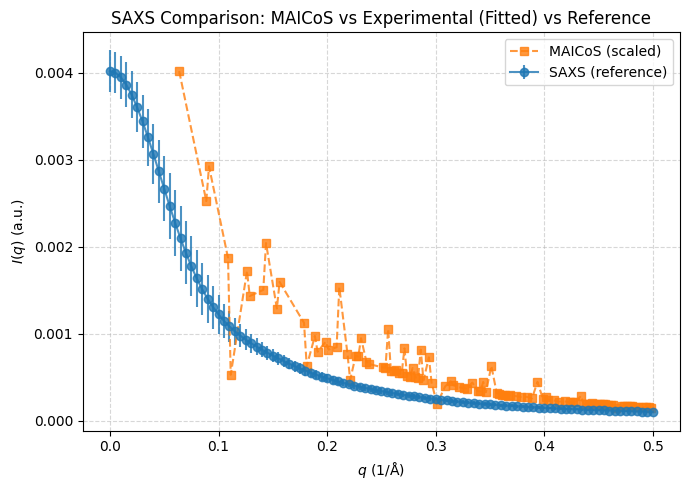

KRS1-72_salt [['KRS1-72_replica_03_CHARMM36M_2000ns.xtc']] 138
[]
Empty DataFrame
Columns: []
Index: []


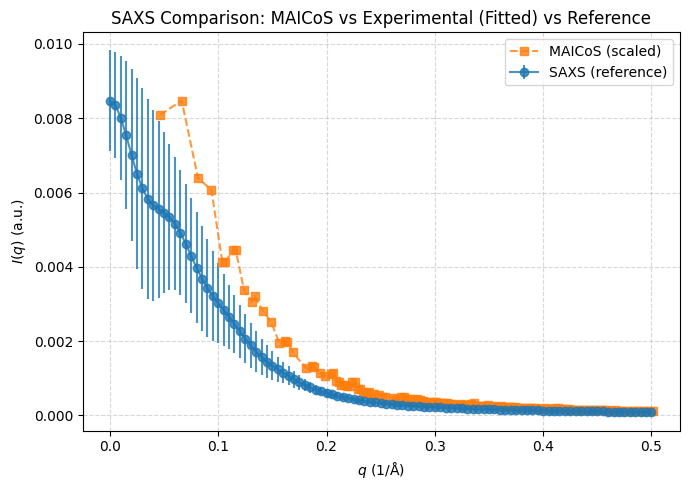

asyn_salt [['aSyn_replica_04_CHARMM36M_2000ns.xtc']] 103
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.001058, scale=1.42e-06, offset=0.000437
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.00137, scale=4.85e-05, offset=0.00105
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.001022, scale=7.11e-07, offset=0.000501
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=489.6, scale=1.75, offset=-162
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=385.2, scale=88.7, of

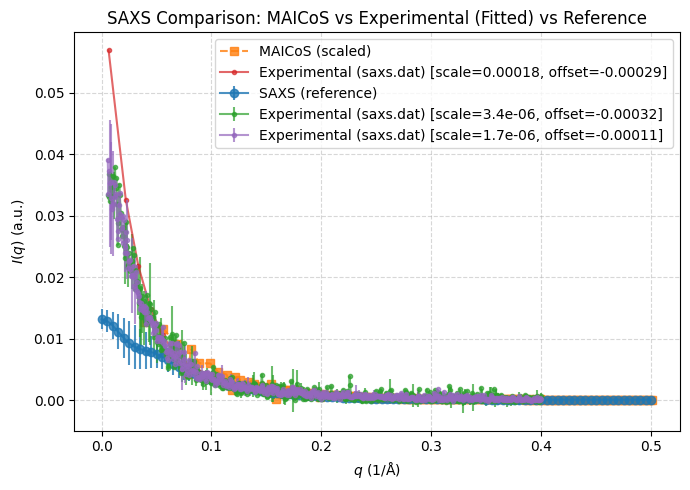

asyn [['replica_03_AMBER99SBWS_md_2000ns.xtc']] 52
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0003487, scale=1.05e-06, offset=0.000129
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.0003427, scale=3.81e-05, offset=0.00039
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0003311, scale=5.23e-07, offset=0.000177
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=214.9, scale=1.01, offset=-15.9
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=165.3, scale=61.6, off

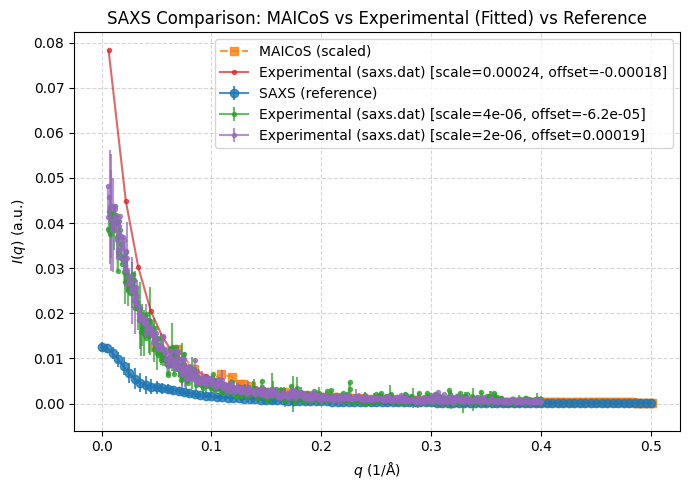

asyn [['replica_02_AMBER99SB-DISP_md_2000ns.xtc']] 53
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0006071, scale=1.21e-06, offset=0.000274
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.0008038, scale=4.24e-05, offset=0.000688
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.000577, scale=6.03e-07, offset=0.000329
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=324.2, scale=1.17, offset=-59.2
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=254.8, scale=76.1, 

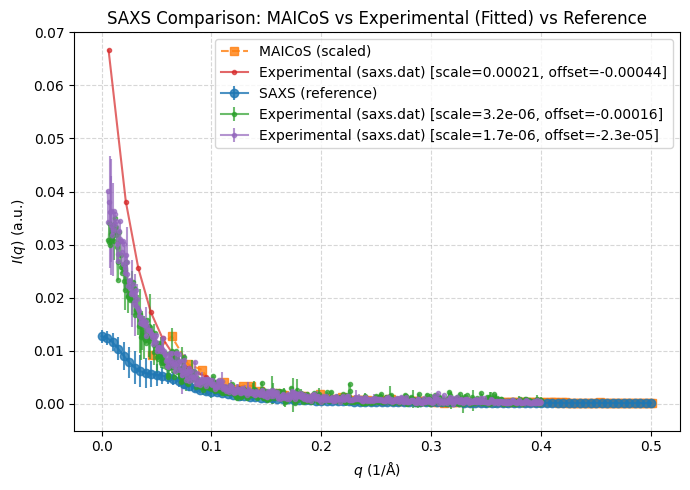

asyn [['replica_02_CHARMM36M_md_2000ns.xtc']] 57
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0005135, scale=1e-06, offset=0.000323
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.0005873, scale=3.53e-05, offset=0.000685
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.000497, scale=4.99e-07, offset=0.000371
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=366.8, scale=1.21, offset=20.8
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=304.1, scale=75.9, offset=-1

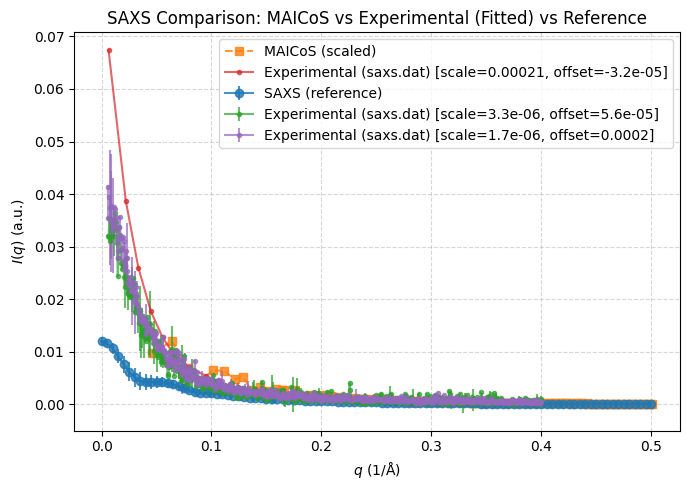

asyn [['replica_01_CHARMM36M_md_2000ns.xtc']] 61
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0009662, scale=1.38e-06, offset=0.000418
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001266, scale=4.74e-05, offset=0.000991
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0009292, scale=6.91e-07, offset=0.00048
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=470.9, scale=1.82, offset=-166
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=241, scale=113, offset=-33

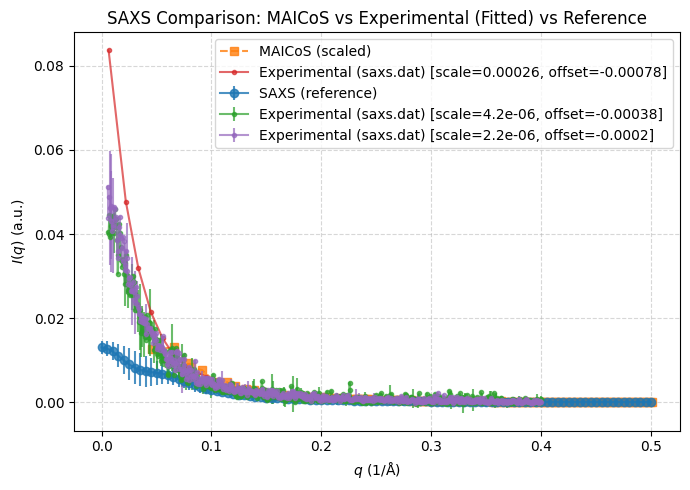

asyn [['replica_02_DESAMBER_md_2000ns.xtc']] 62
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0009769, scale=1.51e-06, offset=0.0004
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001305, scale=5.19e-05, offset=0.001
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0009314, scale=7.54e-07, offset=0.000466
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=352.2, scale=1.69, offset=-147
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=98.15, scale=110, offset=-303
[

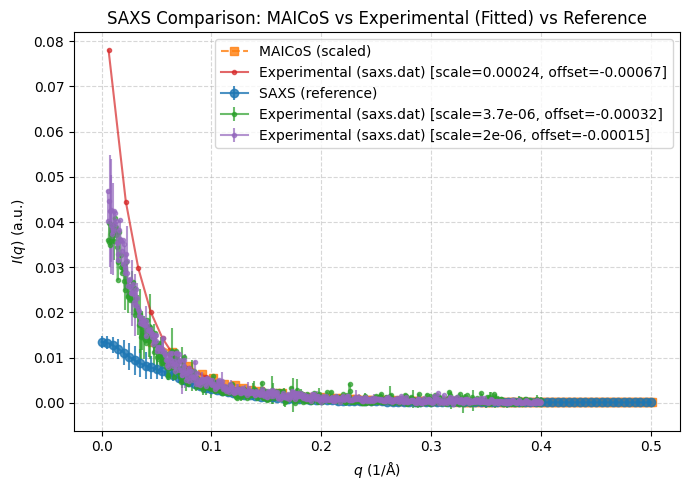

asyn [['replica_02_AMBER99SBWS_md_2000ns.xtc']] 63
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0006439, scale=1.39e-06, offset=0.000155
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.0009195, scale=4.91e-05, offset=0.000564
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0006059, scale=6.93e-07, offset=0.000215
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=211.1, scale=1.46, offset=-208
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=195.6, scale=92.9, off

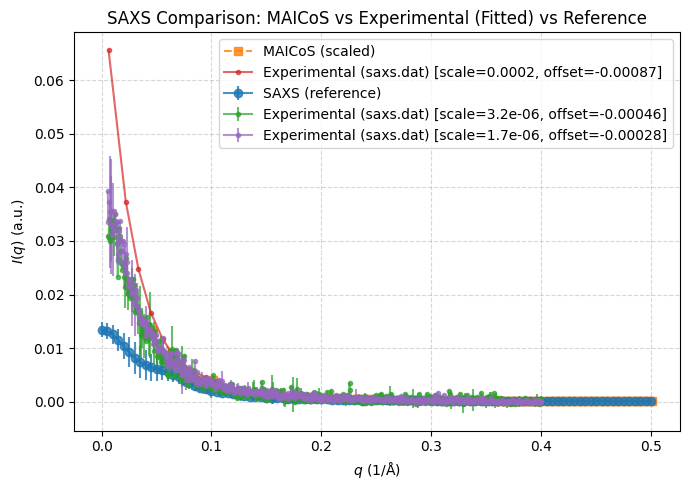

asyn [['replica_04_AMBER99SB-DISP_md_2000ns.xtc']] 65
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0009285, scale=1.54e-06, offset=0.000274
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001283, scale=5.37e-05, offset=0.000815
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.000885, scale=7.71e-07, offset=0.000341
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=306.1, scale=1.45, offset=-147
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=131, scale=94.4, offs

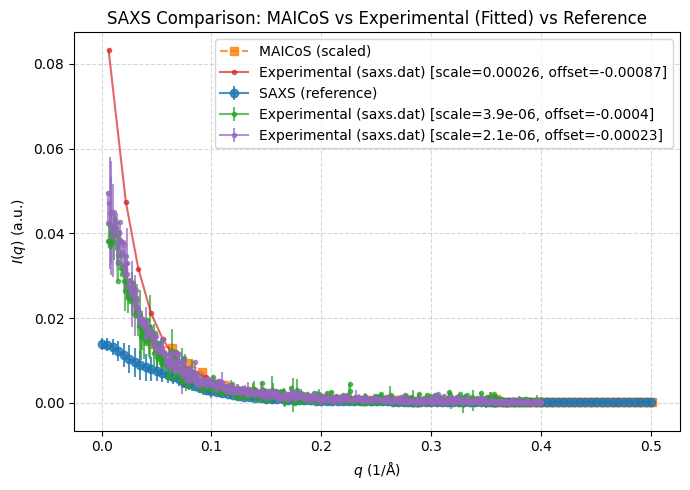

asyn [['replica_01_AMBER99SB-DISP_md_2000ns.xtc']] 66
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0008511, scale=1.45e-06, offset=0.000299
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001161, scale=5.04e-05, offset=0.000821
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0008097, scale=7.24e-07, offset=0.000363
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=385.4, scale=1.61, offset=-157
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=168.4, scale=101, of

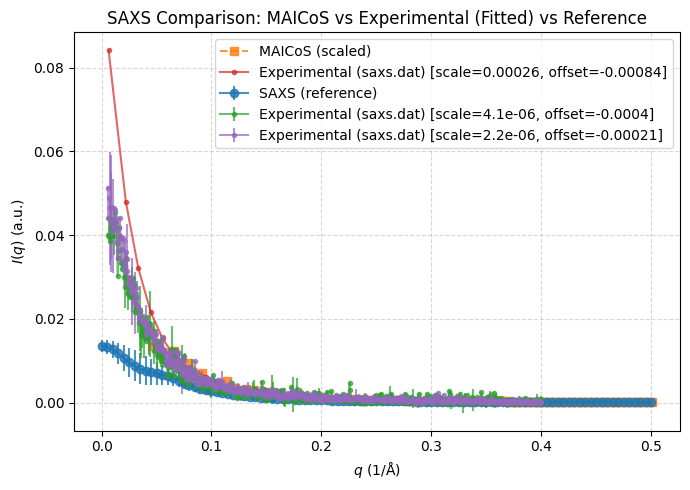

asyn [['replica_04_AMBER99SBWS_md_2000ns.xtc']] 69
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0009225, scale=1.62e-06, offset=0.000177
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001307, scale=5.69e-05, offset=0.000689
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0008788, scale=8.1e-07, offset=0.000246
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=289.3, scale=1.5, offset=-183
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=142.9, scale=97.4, offset

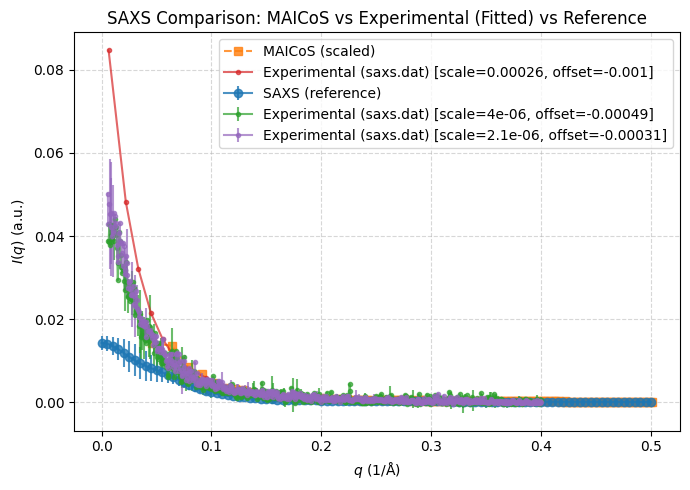

asyn [['replica_01_DESAMBER_md_2000ns.xtc']] 71
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0009443, scale=1.37e-06, offset=0.000443
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001217, scale=4.68e-05, offset=0.00103
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0009057, scale=6.83e-07, offset=0.000504
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=498.3, scale=1.83, offset=-153
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=270.6, scale=115, offset=-2

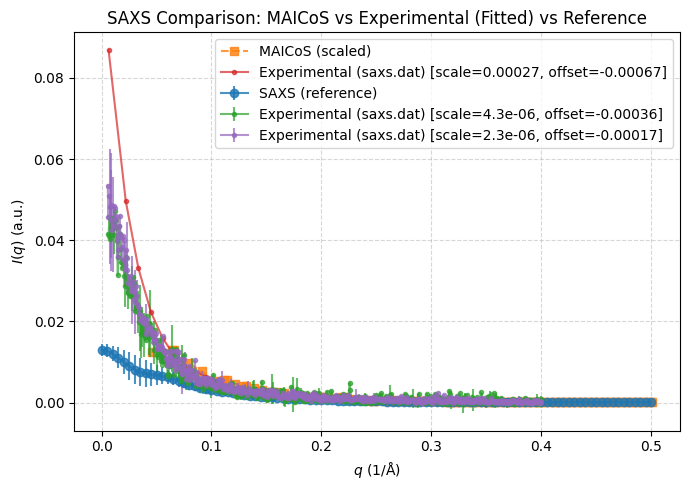

wrapping silk (AcSp1) [['model01_AMBER03WS_md_2000ns.xtc']] 184
[]
Empty DataFrame
Columns: []
Index: []


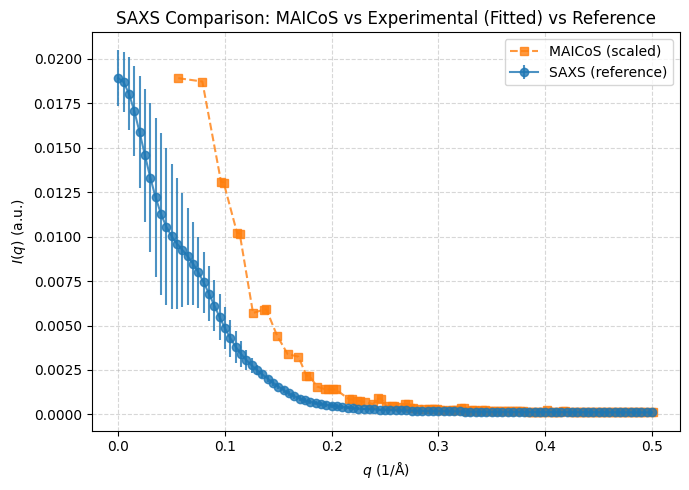

asyn [['replica_05_AMBER99SB-DISP_md_2000ns.xtc']] 73
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0007192, scale=1.3e-06, offset=0.000265
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.0009744, scale=4.54e-05, offset=0.000718
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0006945, scale=6.47e-07, offset=0.000324
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=366.1, scale=1.33, offset=-77
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=270.8, scale=67.8, of

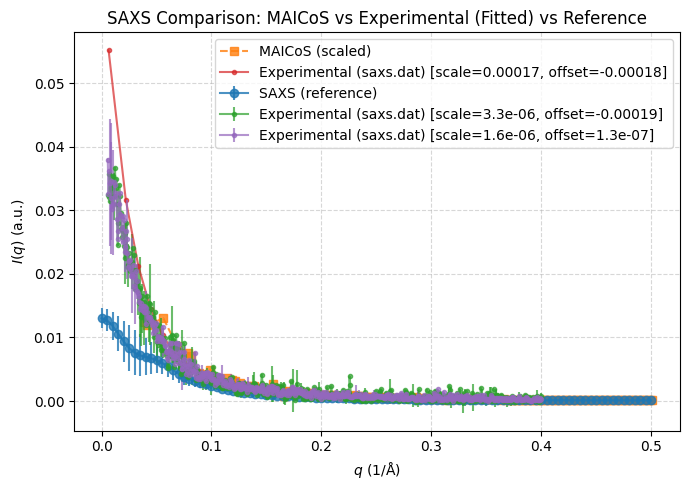

asyn [['replica_03_CHARMM36M_md_2000ns.xtc']] 74
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.001374, scale=1.56e-06, offset=0.000535
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001761, scale=5.28e-05, offset=0.00126
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.001329, scale=7.84e-07, offset=0.000603
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=487.8, scale=2.13, offset=-303
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=385.5, scale=135, offset=-48

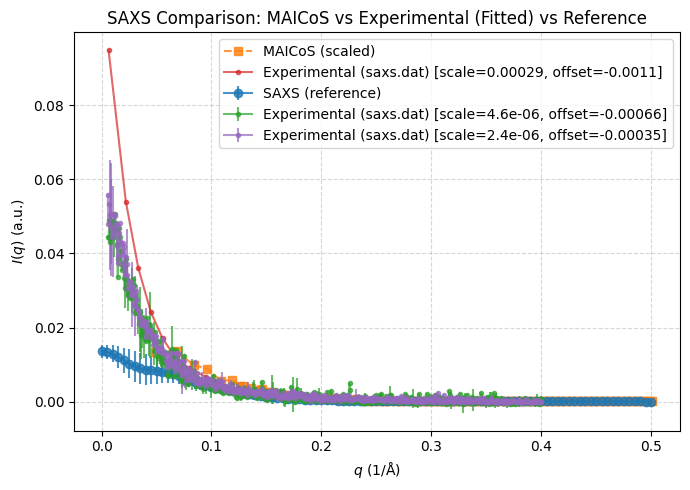

asyn [['replica_03_DESAMBER_md_2000ns.xtc']] 76
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.001146, scale=1.48e-06, offset=0.000473
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001485, scale=5.04e-05, offset=0.00112
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.001102, scale=7.4e-07, offset=0.000538
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=406.8, scale=1.99, offset=-272
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=293.8, scale=125, offset=-453


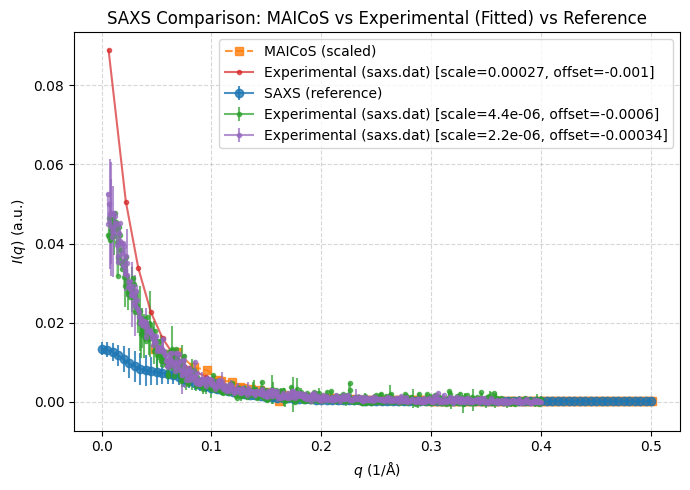

asyn [['replica_04_AMBER03WS_md_2000ns.xtc']] 77
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.001045, scale=1.6e-06, offset=0.000274
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001435, scale=5.56e-05, offset=0.000849
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.001002, scale=8.01e-07, offset=0.000343
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=391.9, scale=1.89, offset=-287
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=124.4, scale=124, offset=-52

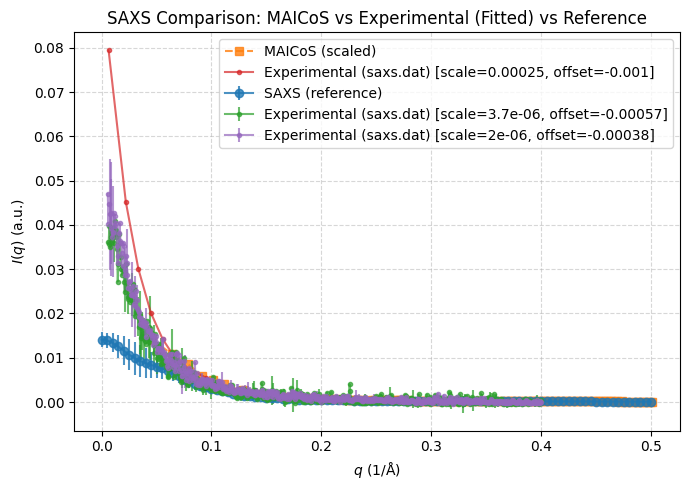

asyn [['replica_03_AMBER03WS_md_2000ns.xtc']] 81
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0009439, scale=1.45e-06, offset=0.000342
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001263, scale=5.01e-05, offset=0.000903
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0009007, scale=7.26e-07, offset=0.000405
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=321.3, scale=1.93, offset=-311
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=81.4, scale=122, offset=-

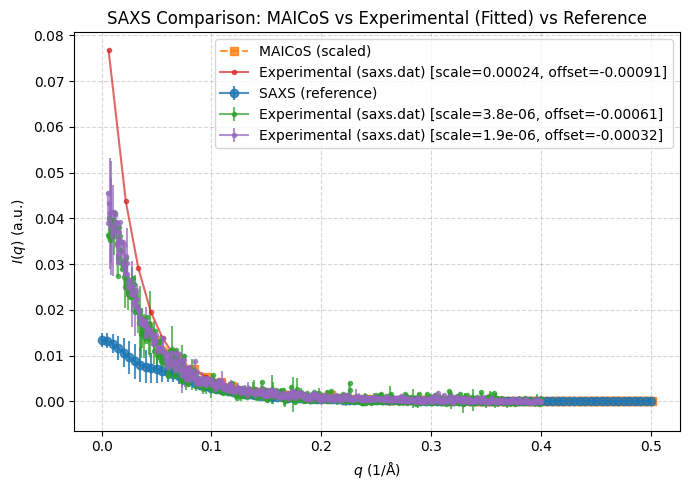

KRS1-72 [['replica_01_AMBER03WS_md_2000ns.xtc']] 99
[]
Empty DataFrame
Columns: []
Index: []


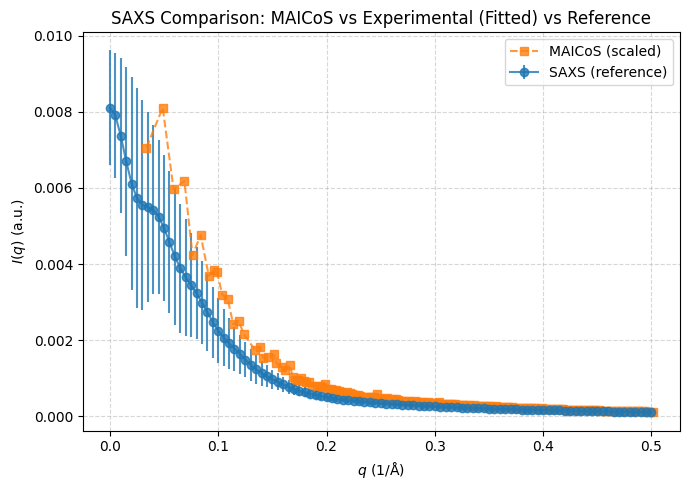

ChiZ1-64 [['replica_01_AMBER03WS_md_1500ns.xtc']] 100
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.3390/biom10060946/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.3390/biom10060946/saxs.dat] RMSD=0.0004753, scale=1.09, offset=-0.000161
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.3390/biom10060946/saxs.dat] RMSD=57.17, scale=4.29e+05, offset=18.7
  Simulation Experiment       RMSD          Scale     Offset
0       SAXS   saxs.dat   0.000475       1.088317  -0.000161
1     MAICoS   saxs.dat  57.169298  429127.344984  18.704896
/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.3390/biom10060946/saxs.dat: scale=3.51, offset=0.000153


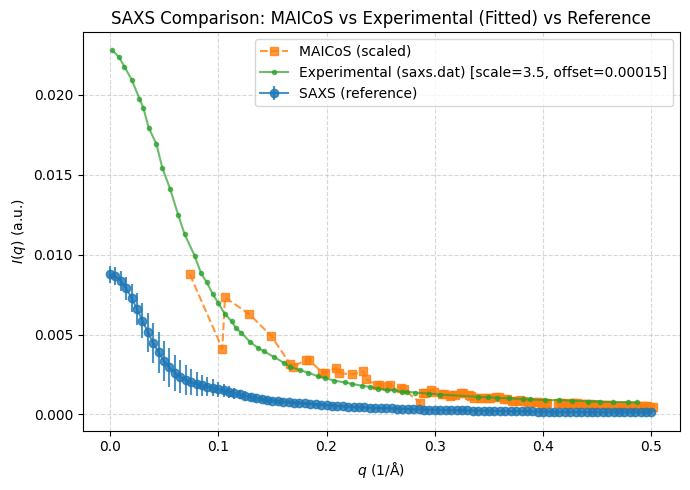

asyn [['replica_05_AMBER99SBWS_md_2000ns.xtc']] 86
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.001254, scale=1.92e-06, offset=0.000193
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001756, scale=6.7e-05, offset=0.000827
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0012, scale=9.62e-07, offset=0.000274
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=332.2, scale=1.75, offset=-271
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=129.7, scale=90, offset=-356

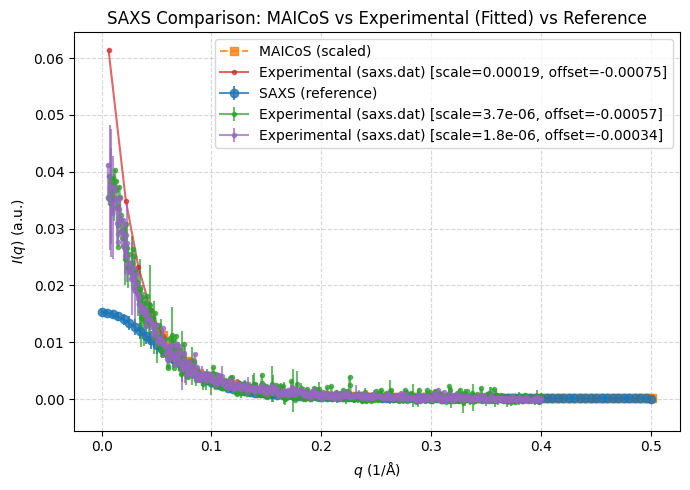

asyn [['replica_02_AMBER03WS_md_2000ns.xtc']] 87
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0009241, scale=1.41e-06, offset=0.000324
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001241, scale=4.9e-05, offset=0.000855
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0008866, scale=7.07e-07, offset=0.000387
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=325.9, scale=1.84, offset=-277
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=108.2, scale=120, offset=-

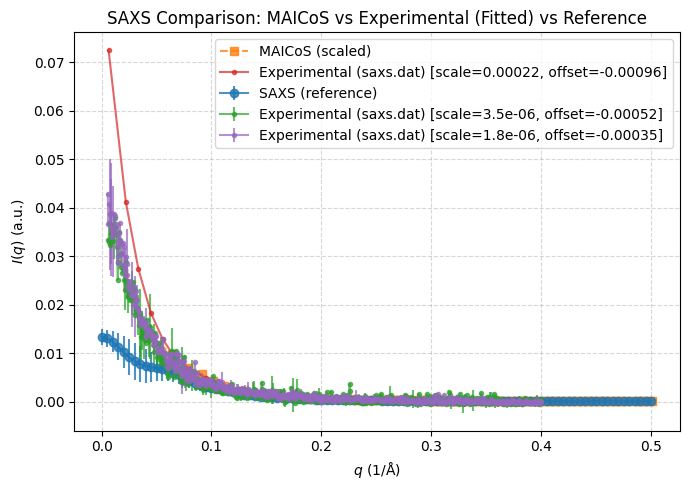

asyn [['replica_05_CHARMM36M_md_2000ns.xtc']] 88
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.001154, scale=1.41e-06, offset=0.000433
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001492, scale=4.81e-05, offset=0.00105
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.001121, scale=7.07e-07, offset=0.000496
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=615.5, scale=1.75, offset=-150
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=550.5, scale=90, offset=-154

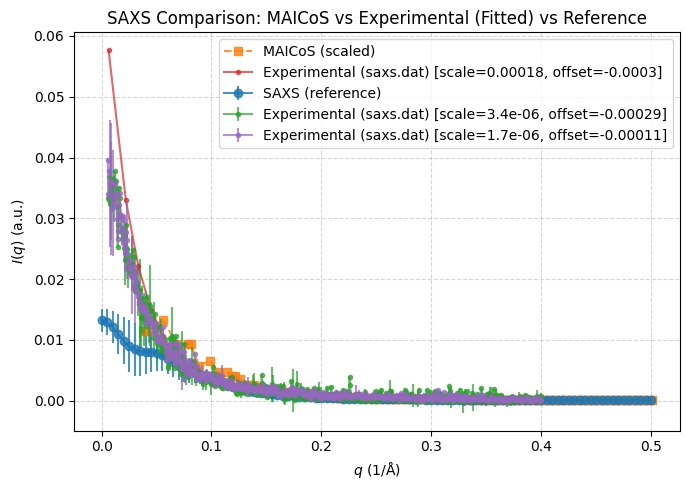

asyn [['replica_03_AMBER99SB-DISP_md_2000ns.xtc']] 89
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0007485, scale=1.32e-06, offset=0.000302
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001003, scale=4.6e-05, offset=0.00078
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0007102, scale=6.59e-07, offset=0.00036
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=300.2, scale=1.73, offset=-230
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=136.9, scale=108, offse

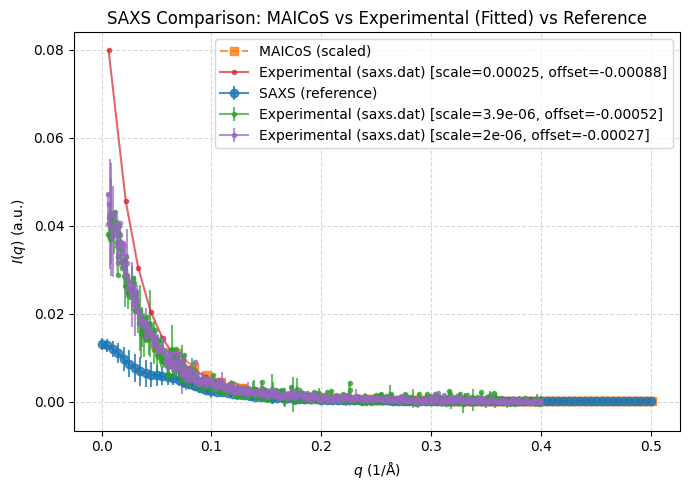

asyn [['replica_04_CHARMM36M_md_2000ns.xtc']] 90
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0005255, scale=1.16e-06, offset=0.000268
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.0006516, scale=4.1e-05, offset=0.000666
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0004925, scale=5.8e-07, offset=0.000321
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=524.3, scale=1.04, offset=53.7
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=509.4, scale=70.7, offset=

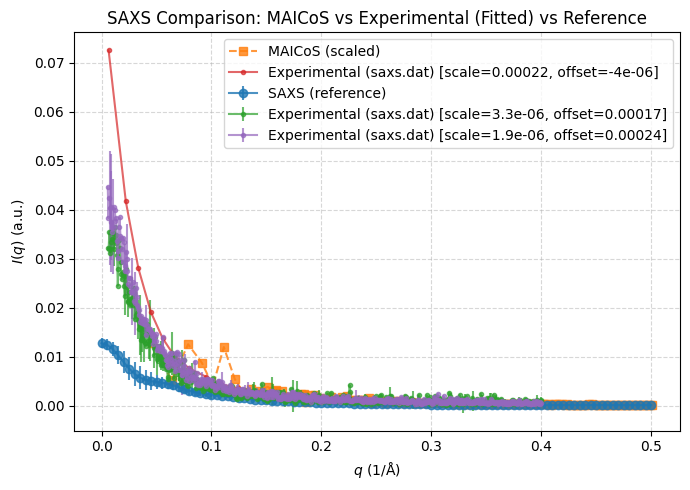

asyn [['replica_05_DESAMBER_md_2000ns.xtc']] 91
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.001194, scale=1.57e-06, offset=0.000355
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001593, scale=5.4e-05, offset=0.00097
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.001155, scale=7.86e-07, offset=0.000423
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=495.1, scale=2.1, offset=-312
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=415, scale=102, offset=-300
[MA

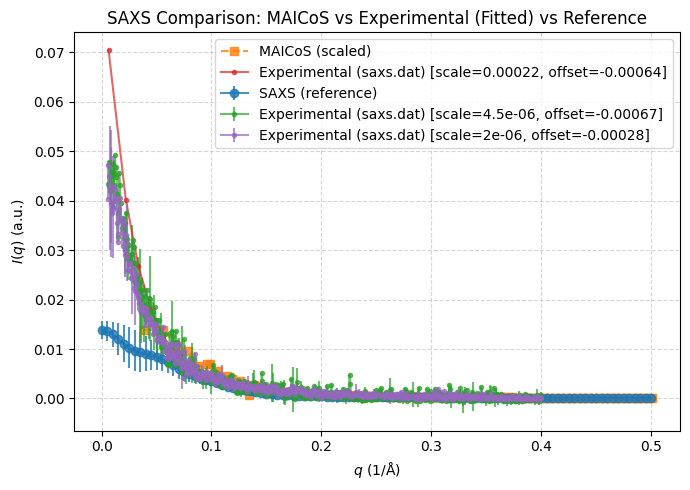

asyn [['replica_05_AMBER03WS_md_2000ns.xtc']] 92
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0008005, scale=1.37e-06, offset=0.00024
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001098, scale=4.79e-05, offset=0.000705
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0007721, scale=6.84e-07, offset=0.000301
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=333.7, scale=1.97, offset=-303
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=148.6, scale=94.6, offset=

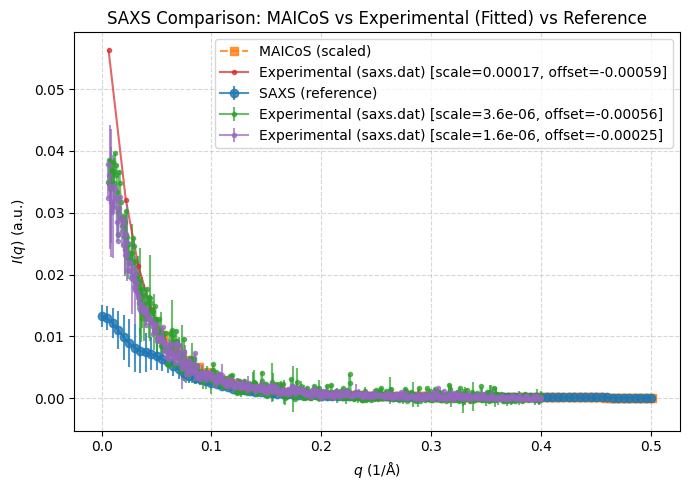

asyn [['replica_04_DESAMBER_md_2000ns.xtc']] 93
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0008358, scale=1.34e-06, offset=0.000335
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001109, scale=4.65e-05, offset=0.000847
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0007999, scale=6.7e-07, offset=0.000395
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=365.2, scale=1.48, offset=-142
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=200.4, scale=97.8, offset=-

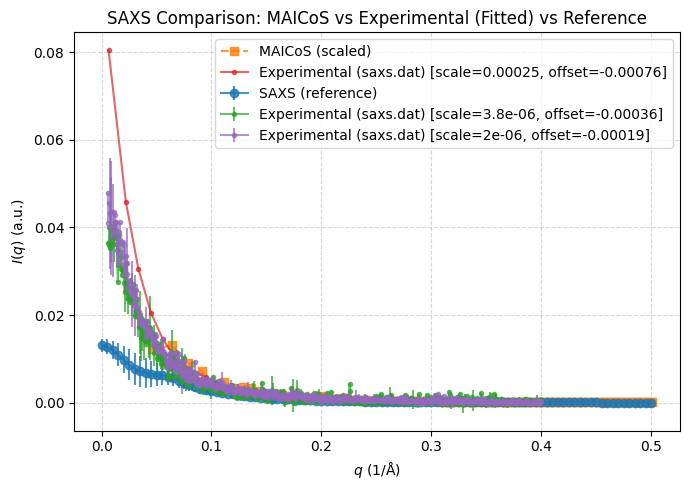

asyn [['replica_01_AMBER03WS_md_2000ns.xtc']] 102
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.0008502, scale=1.47e-06, offset=0.00024
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001178, scale=5.14e-05, offset=0.000742
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.0008103, scale=7.35e-07, offset=0.000304
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=326.6, scale=1.83, offset=-255
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=99.97, scale=114, offset=

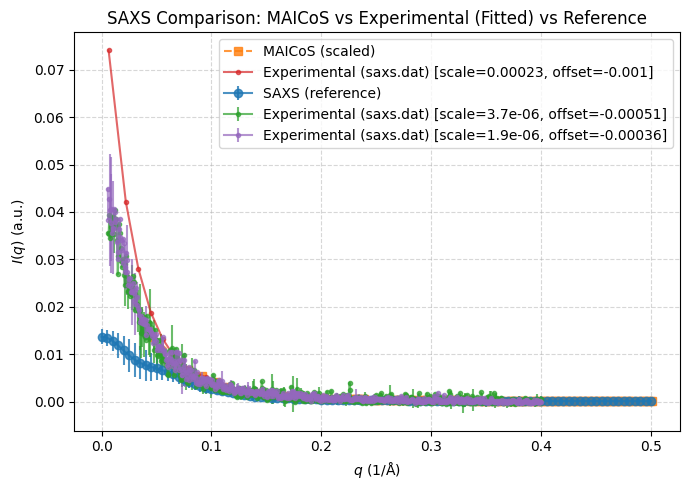

EN2 [['md2_EN2_amber99SBws_model1_nojump.xtc']] 42
[]
Empty DataFrame
Columns: []
Index: []


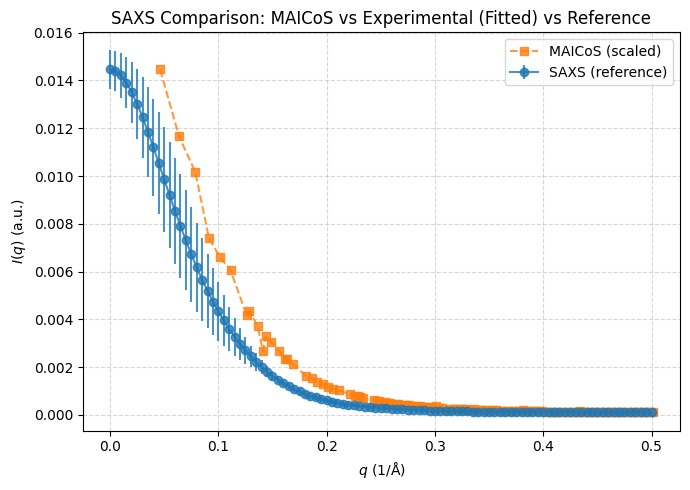

icl2 [['replica_01_AMBER03WS_md_2000ns.xtc']] 101
[]
Empty DataFrame
Columns: []
Index: []


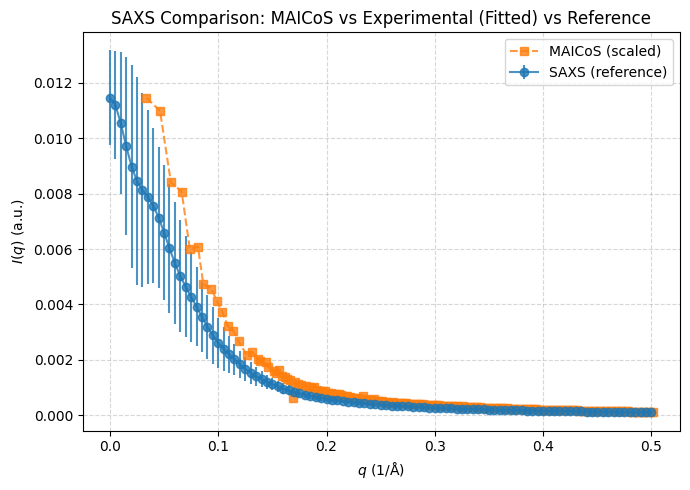

Calmodulin [['md_calmodulin_DESamber_model10_nojump.xtc']] 51
[]
Empty DataFrame
Columns: []
Index: []


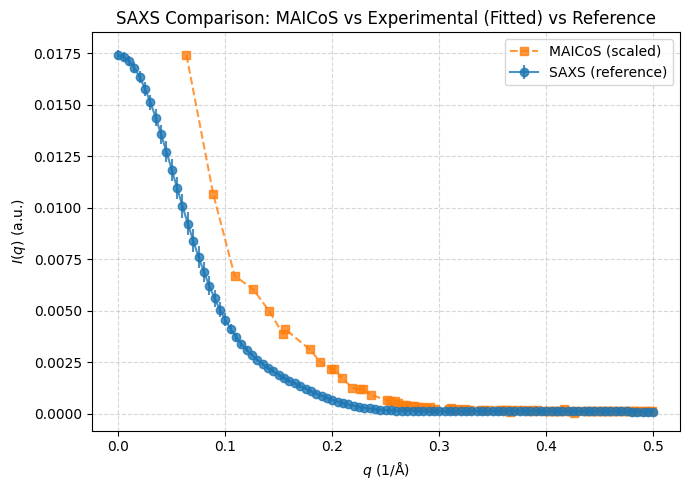

asyn [['replica_01_AMBER99SBWS_md_2000ns.xtc']] 98
['/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat', '/home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat']
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=0.001056, scale=1.79e-06, offset=0.000148
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=0.001498, scale=6.28e-05, offset=0.000703
[SAXS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQJ7/saxs.dat] RMSD=0.001007, scale=8.95e-07, offset=0.000224
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/SASDQK7/saxs.dat] RMSD=349.4, scale=1.5, offset=-193
[MAICoS vs /home/sosamuli/work/NMRlipids/IDPdatabank/Data/Experiments/saxs/10.1038/srep30473/saxs.dat] RMSD=241.1, scale=93.3, offset=

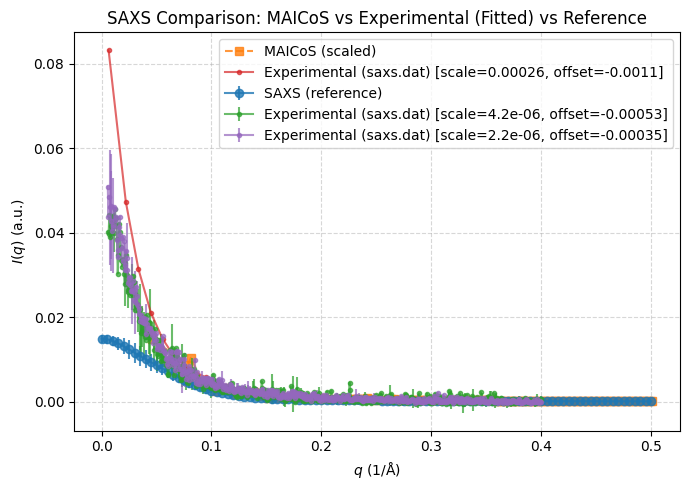

In [9]:
for system in systems:
    SAXS_file = databankPath + 'Data/Simulations/' + system['path'] + 'SAXS.yaml'
    SAXS_MAICOS_file = databankPath + 'Data/Simulations/' + system['path'] + 'SAXS_MAICoS.yaml'
    if os.path.exists(SAXS_file) and os.path.exists(SAXS_MAICOS_file):
        print(system['SYSTEM'], system['TRJ'], system['ID'])
        exp_files = []
        for exp_path in system['EXPERIMENT']['saxs']['path']:
            exp_file_path = databankPath + 'Data/Experiments/saxs/' + exp_path + '/saxs.dat'
            exp_files.append(exp_file_path)
        print(exp_files)
        df_saxs = rmsd_saxs_vs_experiments(SAXS_file, exp_files)
        df_maicos = rmsd_maicos_vs_experiments(SAXS_MAICOS_file, exp_files)

        # Combine results
        df_all = pd.concat([df_saxs, df_maicos], ignore_index=True)
        print(df_all)

        plot_saxs_comparison_to_maicos(SAXS_file, SAXS_MAICOS_file,exp_files)
        
        

In [10]:
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- Data readers ----------------

def read_saxs_yaml(filename):
    with open(filename, 'r') as f:
        data = yaml.safe_load(f)
    q, I, I_std = [], [], []
    for d in data:
        q_val = d.get('q[1/A]', d.get('q', None))
        if q_val is None:
            continue
        I_key_candidates = ['mean_I(q)[a.u.]', 'mean_Inten[a.u.]', 'I(q)[a.u.]']
        I_val = next((d[k] for k in I_key_candidates if k in d), None)
        if I_val is None:
            continue
        sd_val = d.get('sd_I(q)[a.u.]', d.get('sd_Inten[a.u.]', 0.0))
        q.append(q_val); I.append(I_val); I_std.append(sd_val)
    return np.array(q), np.array(I), np.array(I_std)

def read_experimental_saxs(filename):
    q, I, err = [], [], []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or not (line[0].isdigit() or line[0]=='.'):
                continue
            parts = line.split()
            try:
                q_val = float(parts[0]) / 10.0   # 1/nm -> 1/Å
                I_val = float(parts[1])
                if len(parts) >= 3 and float(parts[2]) >= 0:
                    err_val = float(parts[2])
                else:
                    err_val = 0.0
                q.append(q_val); I.append(I_val); err.append(err_val)
            except Exception:
                continue
    return np.array(q), np.array(I), np.array(err)

# ---------------- core utilities ----------------

def fit_exp_to_sim(q_sim, I_sim, q_exp, I_exp, min_points=3):
    """Fit experimental intensities to simulation values in overlapping q-range.
       Returns fitted experimental array (same shape as input q_exp), scale, offset,
       plus masks/info for overlap."""
    # overlapping q-range
    q_min, q_max = max(np.min(q_sim), np.min(q_exp)), min(np.max(q_sim), np.max(q_exp))
    mask_sim = (q_sim >= q_min) & (q_sim <= q_max)
    mask_exp = (q_exp >= q_min) & (q_exp <= q_max)
    n_sim = np.sum(mask_sim); n_exp = np.sum(mask_exp)
    if n_sim < min_points or n_exp < min_points:
        raise ValueError(f"Insufficient overlap: sim points={n_sim}, exp points={n_exp}, q_min={q_min}, q_max={q_max}")
    # interpolate exp onto sim q-grid (overlap region)
    I_exp_interp = np.interp(q_sim[mask_sim], q_exp[mask_exp], I_exp[mask_exp])
    # solve I_sim = scale * I_exp_interp + offset
    A = np.vstack([I_exp_interp, np.ones_like(I_exp_interp)]).T
    scale, offset = np.linalg.lstsq(A, I_sim[mask_sim], rcond=None)[0]
    # apply to full exp curve
    I_exp_fitted = I_exp * scale + offset
    return I_exp_fitted, scale, offset, mask_sim, mask_exp, (q_min, q_max)

def compute_metrics(q_sim, I_sim, q_exp, I_exp, I_err=None, fit=True):
    """Compute RMSD, relative RMSD, reduced chi2. Fit if requested."""
    if fit:
        I_exp_fitted, scale, offset, mask_sim, mask_exp, q_range = fit_exp_to_sim(q_sim, I_sim, q_exp, I_exp)
        # use overlap masks to compute metrics
        qmin, qmax = q_range
        mask_sim = (q_sim >= qmin) & (q_sim <= qmax)
        # interpolate fitted exp onto sim q points within mask_sim
        I_exp_interp = np.interp(q_sim[mask_sim], q_exp, I_exp_fitted)
    else:
        scale, offset = 1.0, 0.0
        mask_sim = (q_sim >= max(np.min(q_sim), np.min(q_exp))) & (q_sim <= min(np.max(q_sim), np.max(q_exp)))
        I_exp_interp = np.interp(q_sim[mask_sim], q_exp, I_exp)

    sim_vals = I_sim[mask_sim]
    exp_vals = I_exp_interp
    N = len(sim_vals)
    diffs = sim_vals - exp_vals
    rmsd = np.sqrt(np.mean(diffs**2))
    rel_rmsd = rmsd / np.mean(np.abs(sim_vals)) if np.mean(np.abs(sim_vals)) != 0 else np.nan

    # reduced chi2 if errors provided (use exp errors interpolated to sim q)
    if I_err is not None and np.any(I_err > 0):
        # scale errors by fitted scale (and offset doesn't affect error)
        if fit:
            # we must get error interpolation onto sim q-grid and multiply by scale
            _, _, err_exp = I_err  # expecting tuple? we'll assume I_err is raw error array aligned with q_exp
        # simpler approach: take err_exp array passed as same shape as q_exp
        err_interp = np.interp(q_sim[mask_sim], q_exp, I_err) if I_err is not None else None
        # if we have positive errors:
        if err_interp is not None and np.any(err_interp > 0):
            # if fitted, multiply errors by scale
            err_interp = err_interp * (scale if fit else 1.0)
            chi2 = np.sum((diffs / err_interp)**2)
            dof = N - 2 if fit else N - 1
            red_chi2 = chi2 / dof if dof > 0 else np.nan
        else:
            red_chi2 = np.nan
    else:
        red_chi2 = np.nan

    return {
        "N_points": int(N),
        "q_min": float(np.min(q_sim[mask_sim])),
        "q_max": float(np.max(q_sim[mask_sim])),
        "scale": float(scale),
        "offset": float(offset),
        "RMSD": float(rmsd),
        "RelRMSD": float(rel_rmsd),
        "RedChi2": float(red_chi2)
    }

# ---------------- high-level wrapper ----------------

def compare_simulations_to_experiments(saxs_file, maicos_file, experimental_files, fit=True, plot=False):
    """Compare both SAXS and MAICoS to every experimental file.
       Returns a pandas DataFrame with diagnostics and metrics."""
    q_saxs, I_saxs, _ = read_saxs_yaml(saxs_file)
    q_maicos, I_maicos, _ = read_saxs_yaml(maicos_file)

    rows = []
    for exp in experimental_files:
        q_exp, I_exp, I_err = read_experimental_saxs(exp)
        # SAXS comparison
        try:
            sax_metrics = compute_metrics(q_saxs, I_saxs, q_exp, I_exp, I_err, fit=fit)
        except Exception as e:
            sax_metrics = {"error": str(e)}
        # MAICoS comparison
        try:
            mai_metrics = compute_metrics(q_maicos, I_maicos, q_exp, I_exp, I_err, fit=fit)
        except Exception as e:
            mai_metrics = {"error": str(e)}

        row = {
            "Experimental": exp.split('/')[-1],
            "SAXS_N": sax_metrics.get("N_points", np.nan),
            "SAXS_qmin": sax_metrics.get("q_min", np.nan),
            "SAXS_qmax": sax_metrics.get("q_max", np.nan),
            "SAXS_scale": sax_metrics.get("scale", np.nan),
            "SAXS_offset": sax_metrics.get("offset", np.nan),
            "SAXS_RMSD": sax_metrics.get("RMSD", np.nan),
            "SAXS_RelRMSD": sax_metrics.get("RelRMSD", np.nan),
            "SAXS_RedChi2": sax_metrics.get("RedChi2", np.nan),
            "MAICOS_N": mai_metrics.get("N_points", np.nan),
            "MAICOS_qmin": mai_metrics.get("q_min", np.nan),
            "MAICOS_qmax": mai_metrics.get("q_max", np.nan),
            "MAICOS_scale": mai_metrics.get("scale", np.nan),
            "MAICOS_offset": mai_metrics.get("offset", np.nan),
            "MAICOS_RMSD": mai_metrics.get("RMSD", np.nan),
            "MAICOS_RelRMSD": mai_metrics.get("RelRMSD", np.nan),
            "MAICOS_RedChi2": mai_metrics.get("RedChi2", np.nan),
        }
        rows.append(row)

        # optional quick plot to inspect (overlay)
        if plot:
            plt.figure(figsize=(7,4))
            plt.title(row["Experimental"])
            # plot experiment raw and fitted-to-saxs and fitted-to-maicos
            # fit and get fitted arrays
            try:
                exp_fitted_saxs, s_s, o_s, *_ = fit_exp_to_sim(q_saxs, I_saxs, q_exp, I_exp)
                plt.plot(q_exp, exp_fitted_saxs, '-', label=f"Exp fitted->SAXS (s={s_s:.3g},o={o_s:.3g})")
            except Exception:
                pass
            try:
                exp_fitted_mai, s_m, o_m, *_ = fit_exp_to_sim(q_maicos, I_maicos, q_exp, I_exp)
                #print(exp_fitted_mai,q_maicos, I_maicos, q_exp, I_exp)
                plt.plot(q_exp, exp_fitted_mai, '--', label=f"Exp fitted->MAICoS (s={s_m:.3g},o={o_m:.3g})")
            except Exception:
                pass
            plt.plot(q_exp, I_exp, '.', alpha=0.6, label="Exp raw (converted q)")
            plt.plot(q_saxs, I_saxs, 'o-', alpha=0.6, label="SAXS sim")
            plt.plot(q_maicos, I_maicos, 's--', alpha=0.6, label="MAICoS sim")
            plt.xscale('linear')
            plt.yscale('log')
            plt.legend()
            plt.tight_layout()
            plt.show()

    df = pd.DataFrame(rows)
    return df


asyn [['replica_03_AMBER99SBWS_md_2000ns.xtc']] 52


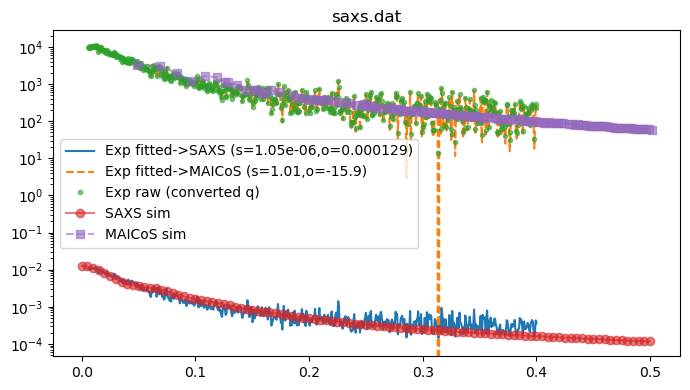

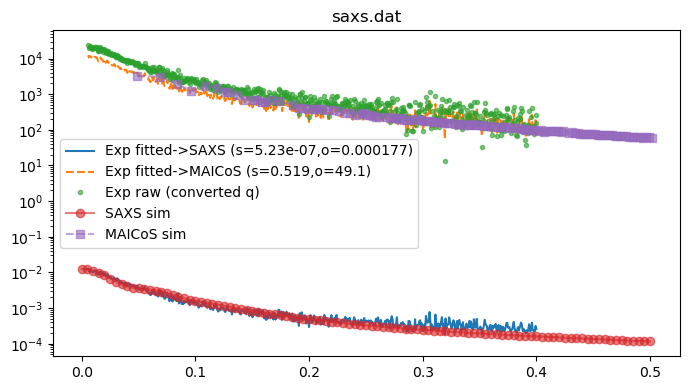

asyn [['replica_02_AMBER99SB-DISP_md_2000ns.xtc']] 53


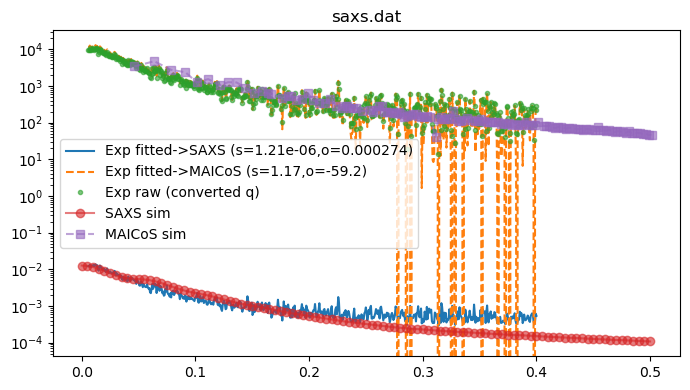

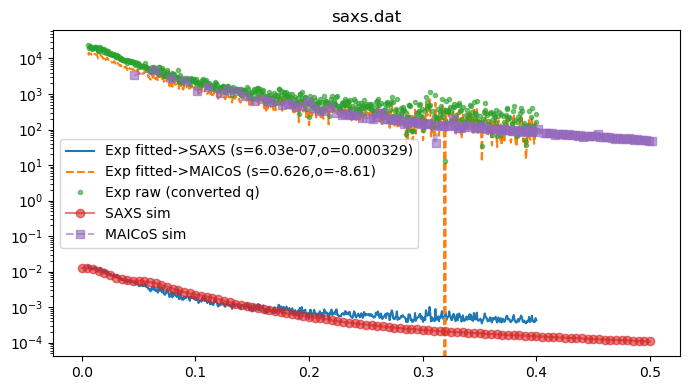

asyn [['replica_02_CHARMM36M_md_2000ns.xtc']] 57


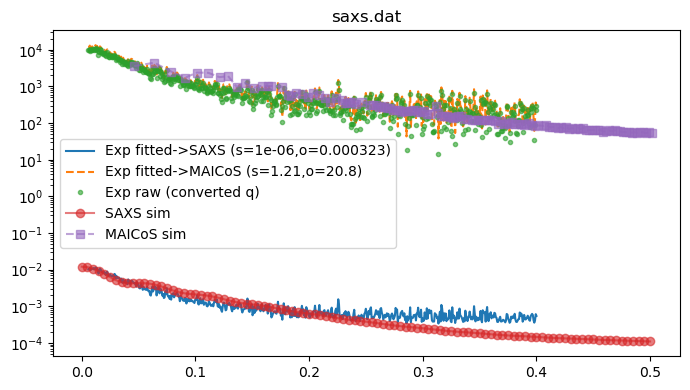

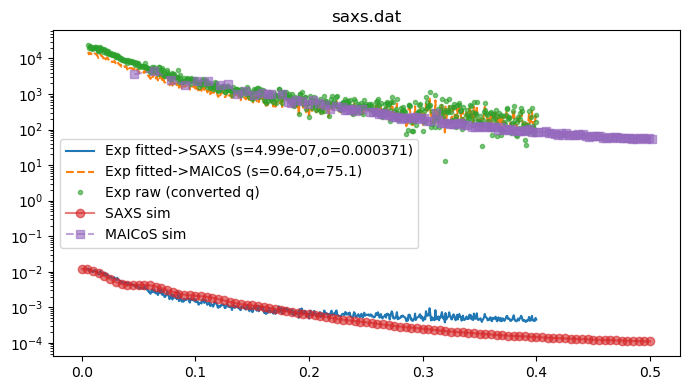

asyn [['replica_01_CHARMM36M_md_2000ns.xtc']] 61


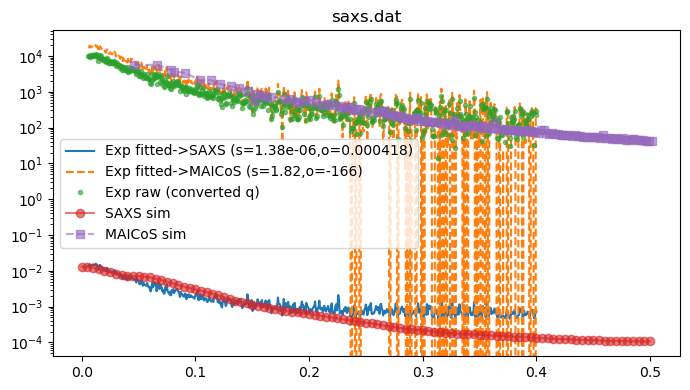

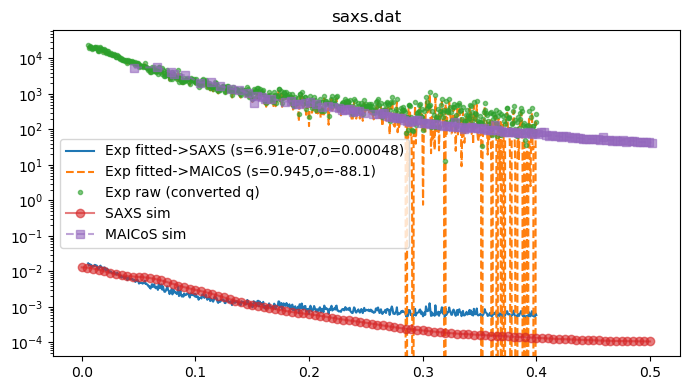

asyn [['replica_02_DESAMBER_md_2000ns.xtc']] 62


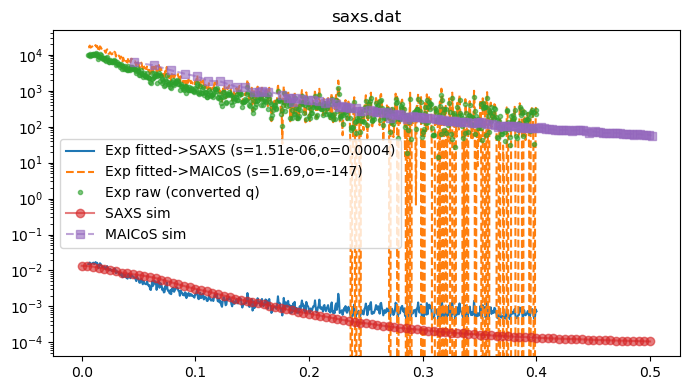

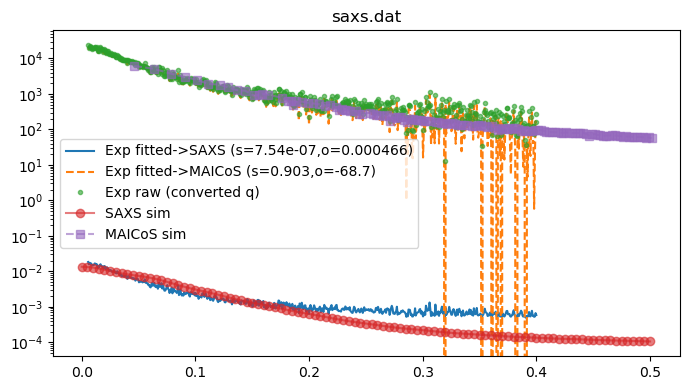

asyn [['replica_02_AMBER99SBWS_md_2000ns.xtc']] 63


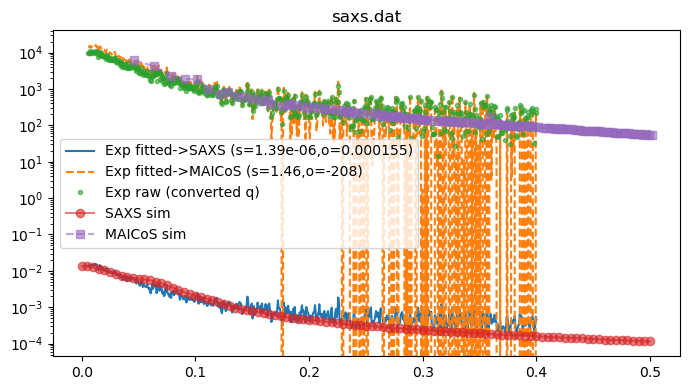

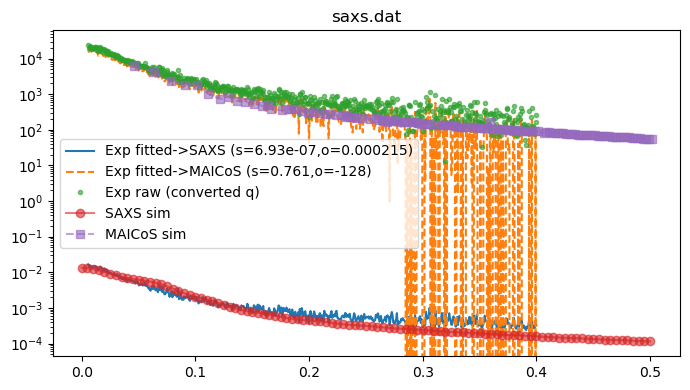

asyn [['replica_04_AMBER99SB-DISP_md_2000ns.xtc']] 65


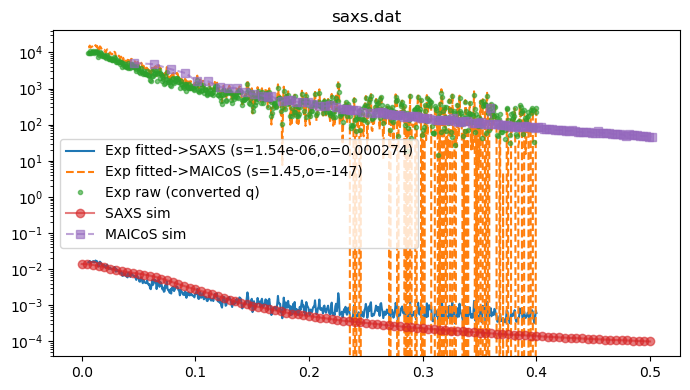

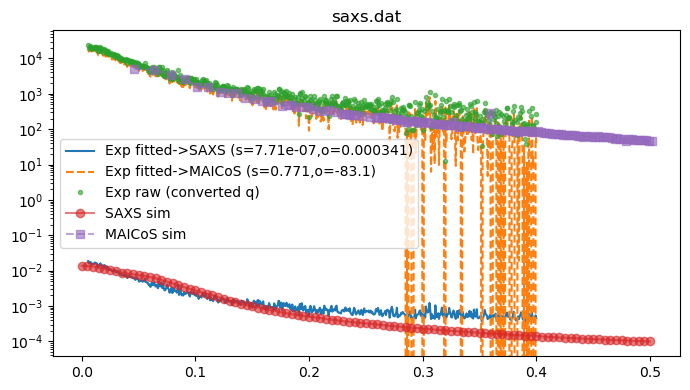

asyn [['replica_01_AMBER99SB-DISP_md_2000ns.xtc']] 66


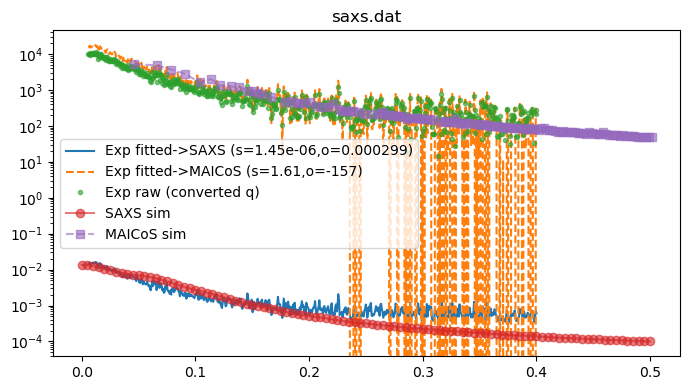

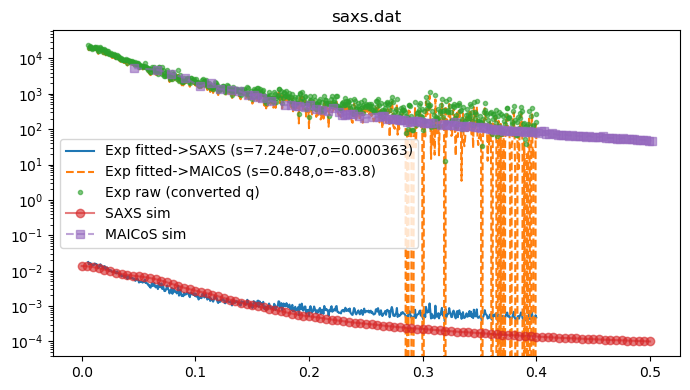

asyn [['replica_04_AMBER99SBWS_md_2000ns.xtc']] 69


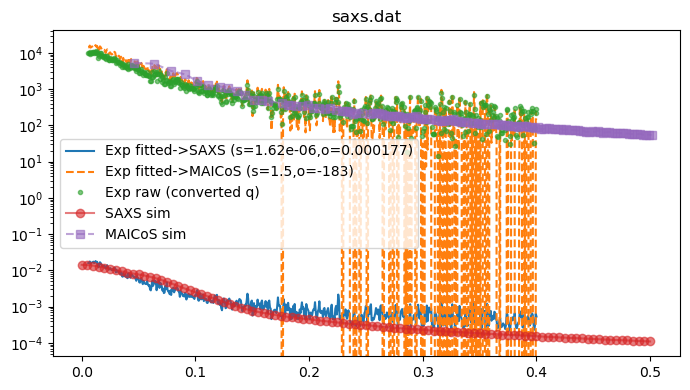

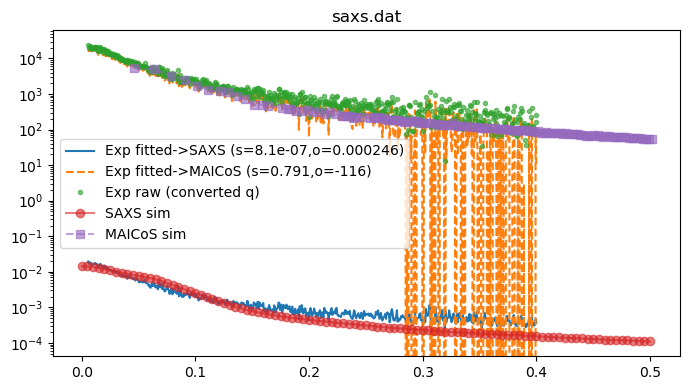

asyn [['replica_01_DESAMBER_md_2000ns.xtc']] 71


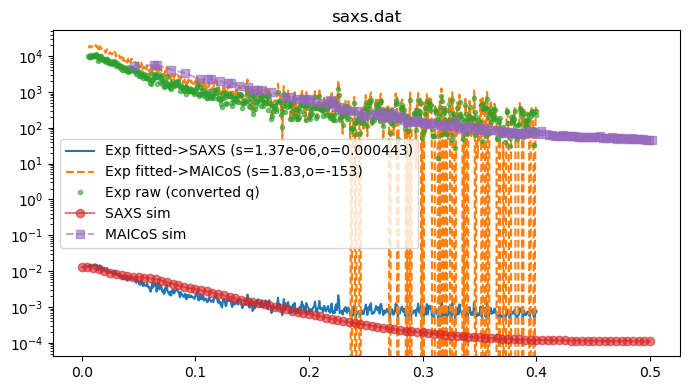

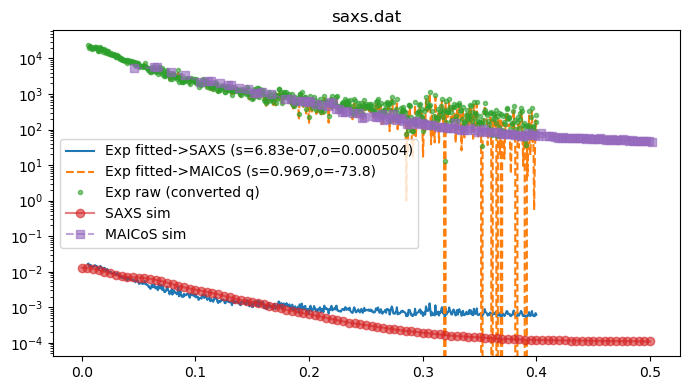

asyn [['replica_05_AMBER99SB-DISP_md_2000ns.xtc']] 73


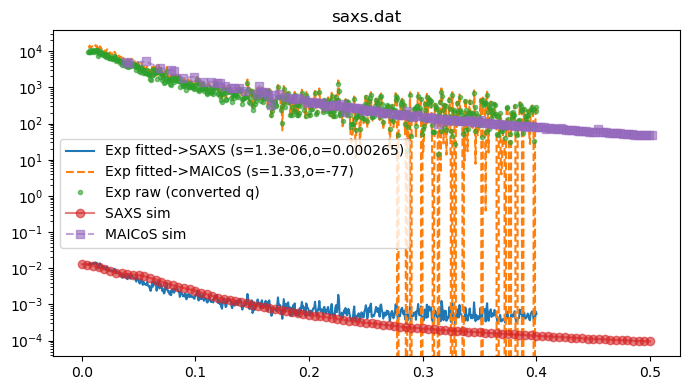

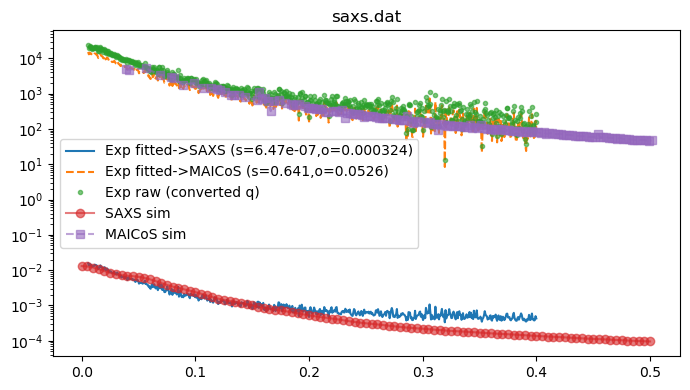

asyn [['replica_03_CHARMM36M_md_2000ns.xtc']] 74


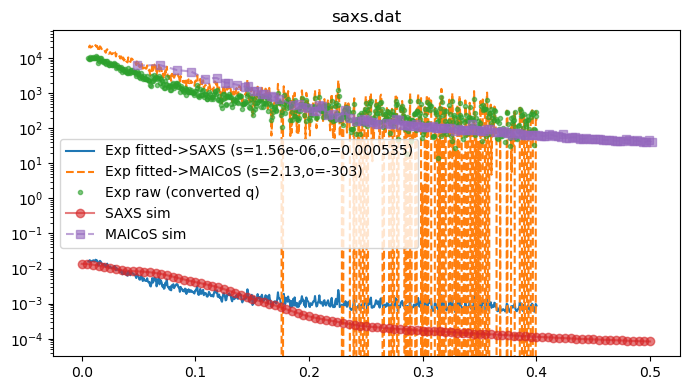

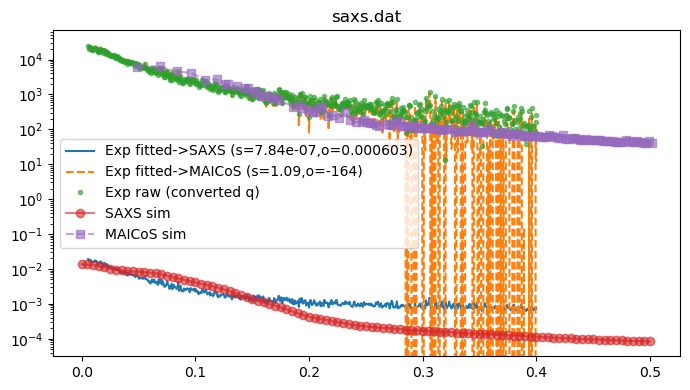

asyn [['replica_03_DESAMBER_md_2000ns.xtc']] 76


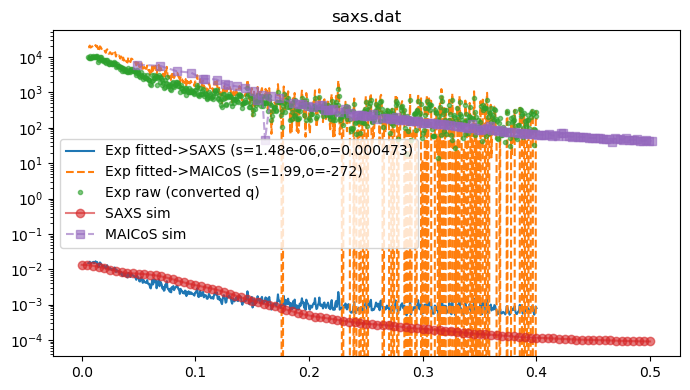

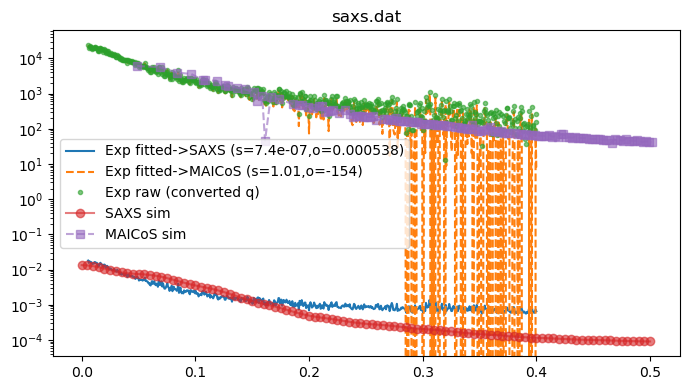

asyn [['replica_04_AMBER03WS_md_2000ns.xtc']] 77


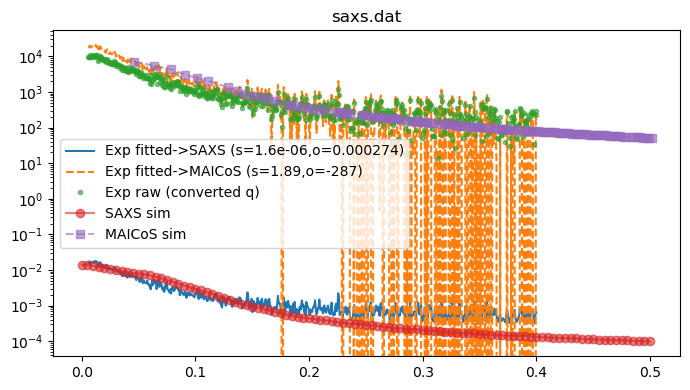

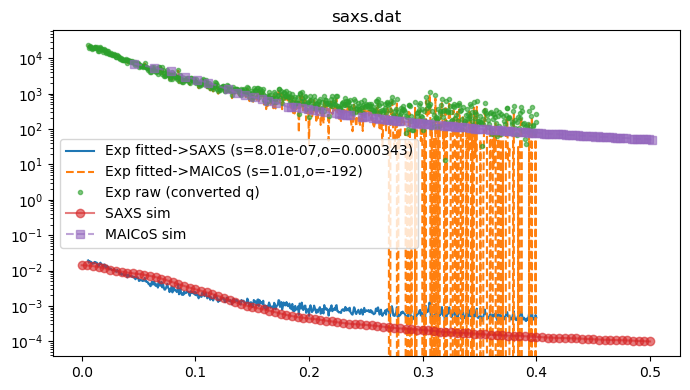

asyn [['replica_03_AMBER03WS_md_2000ns.xtc']] 81


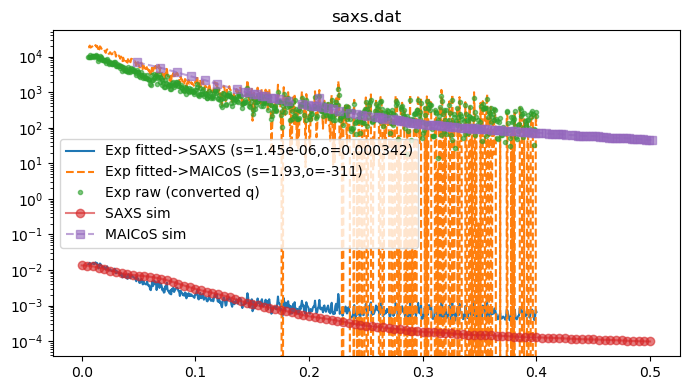

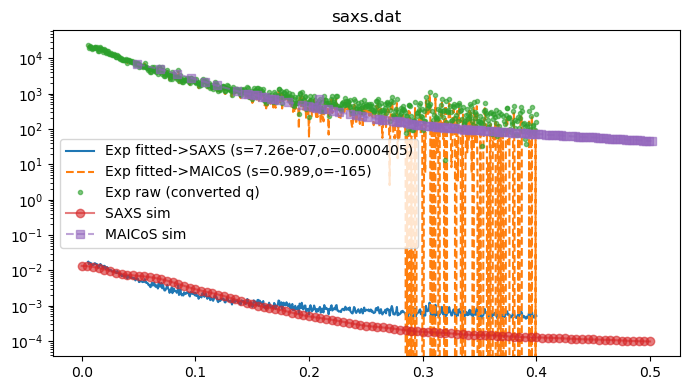

KRS1-72 [['replica_01_AMBER03WS_md_2000ns.xtc']] 99
ChiZ1-64 [['replica_01_AMBER03WS_md_1500ns.xtc']] 100
asyn [['replica_05_AMBER99SBWS_md_2000ns.xtc']] 86


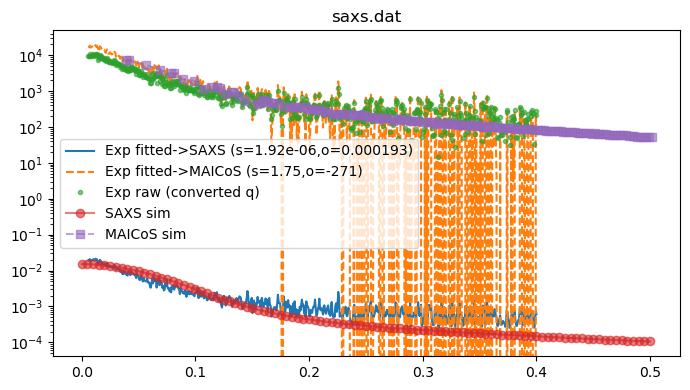

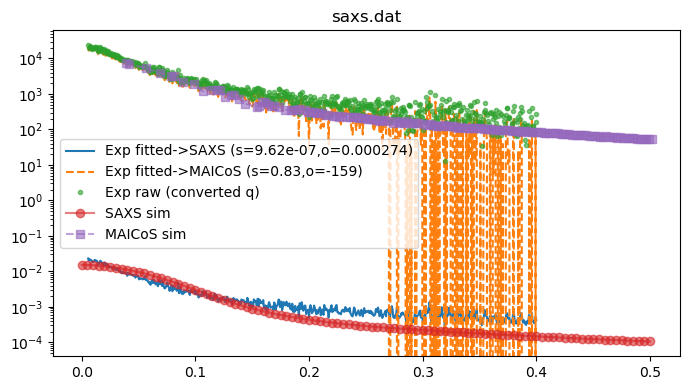

asyn [['replica_02_AMBER03WS_md_2000ns.xtc']] 87


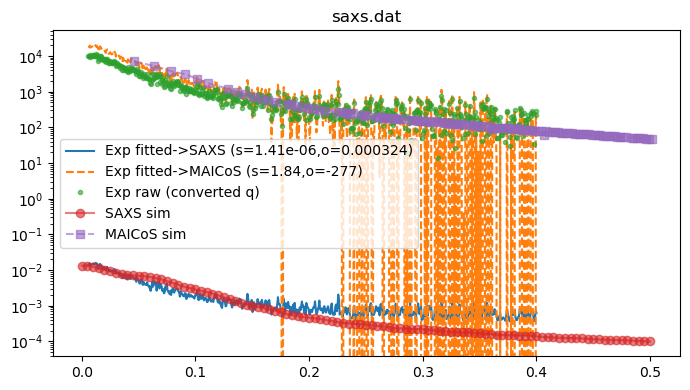

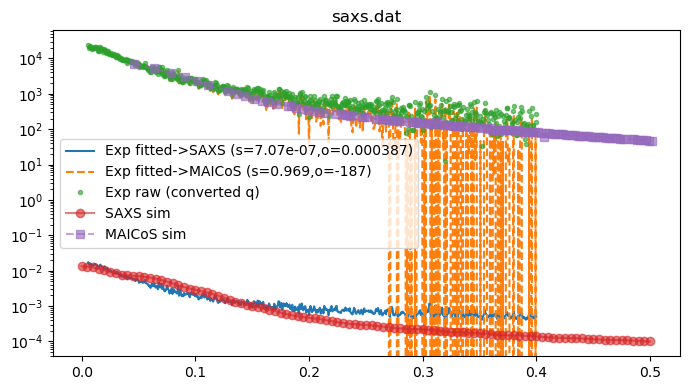

asyn [['replica_05_CHARMM36M_md_2000ns.xtc']] 88


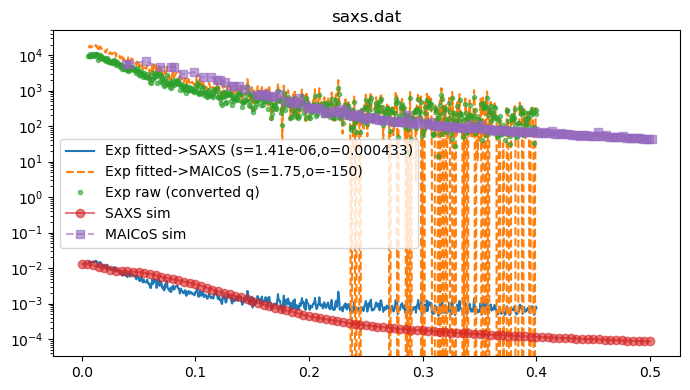

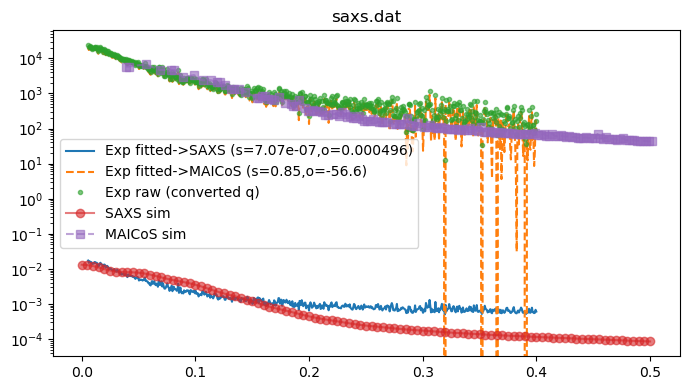

asyn [['replica_03_AMBER99SB-DISP_md_2000ns.xtc']] 89


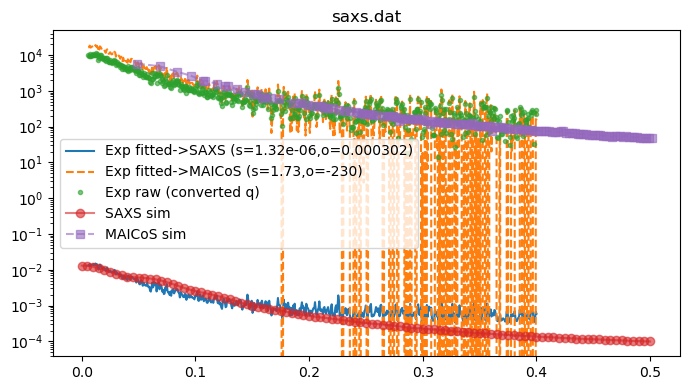

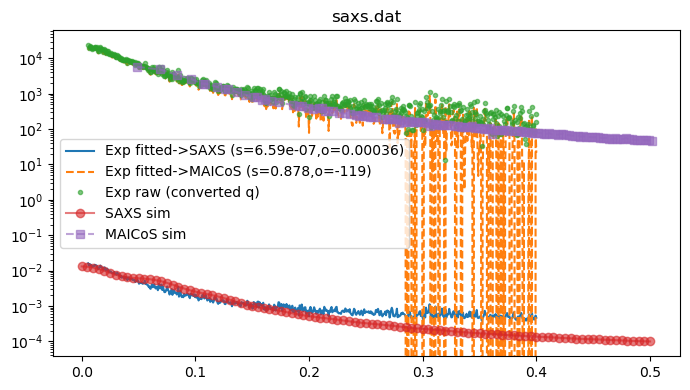

asyn [['replica_04_CHARMM36M_md_2000ns.xtc']] 90


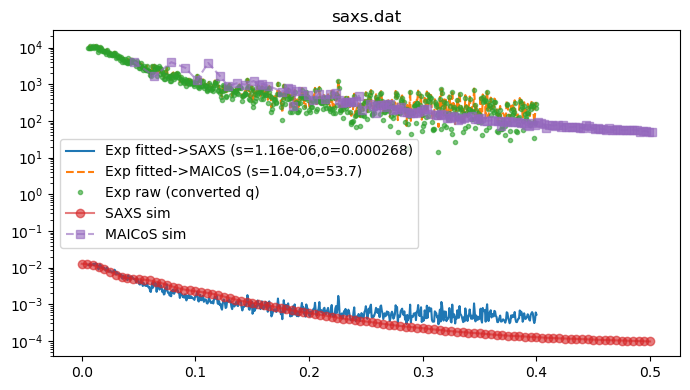

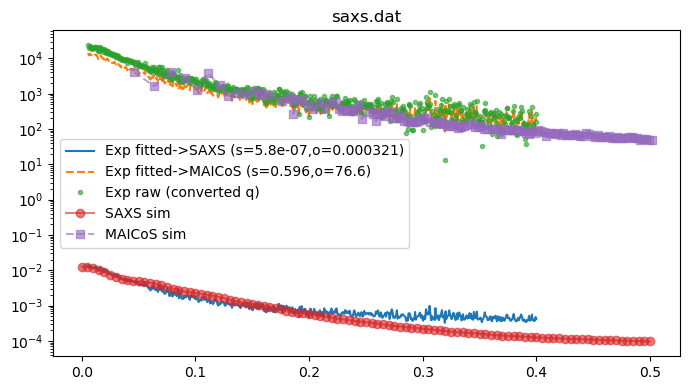

asyn [['replica_05_DESAMBER_md_2000ns.xtc']] 91


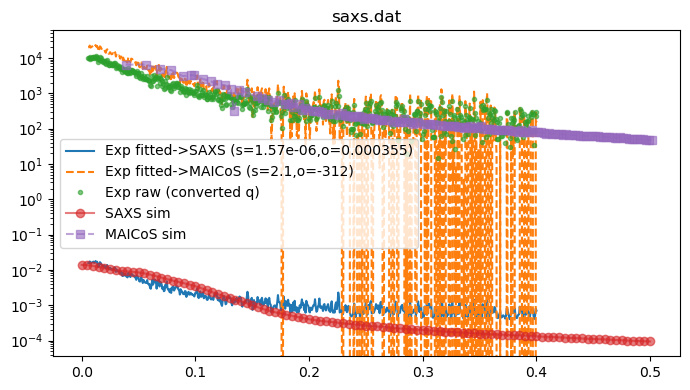

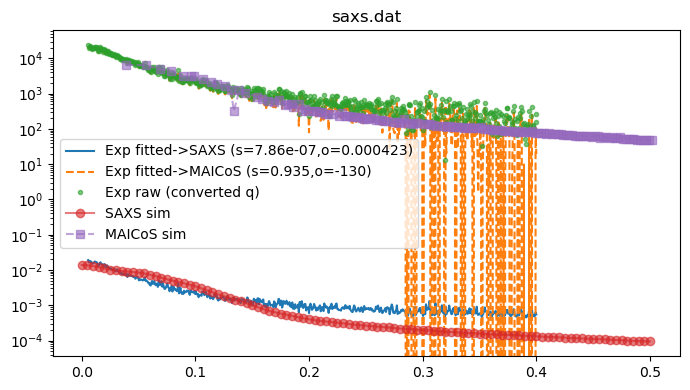

asyn [['replica_05_AMBER03WS_md_2000ns.xtc']] 92


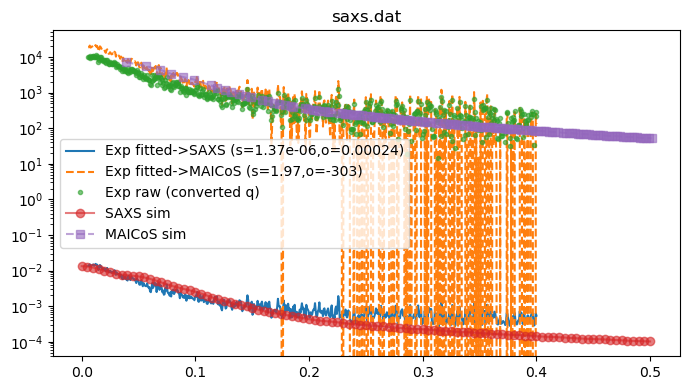

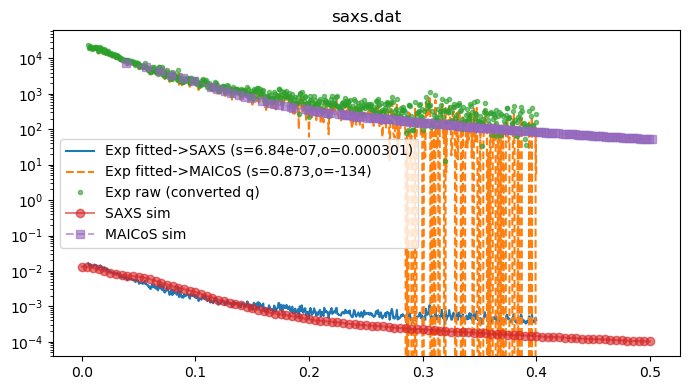

asyn [['replica_04_DESAMBER_md_2000ns.xtc']] 93


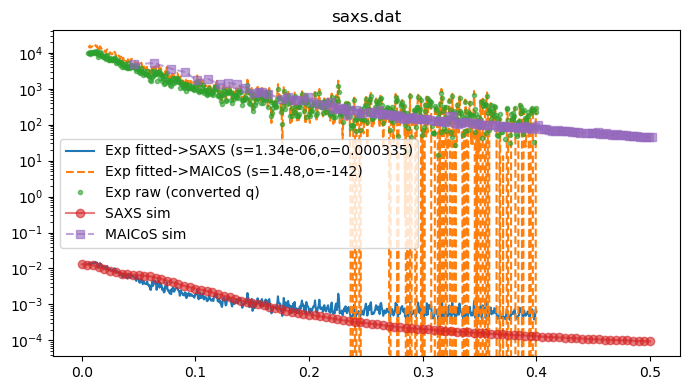

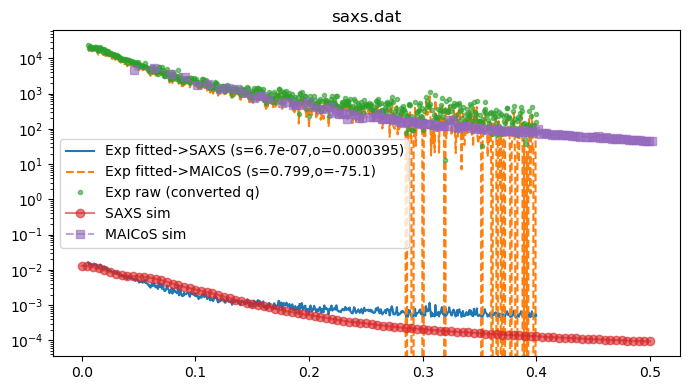

asyn [['replica_01_AMBER03WS_md_2000ns.xtc']] 102


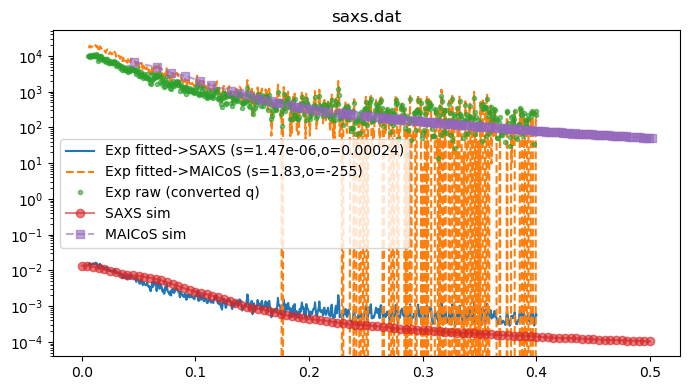

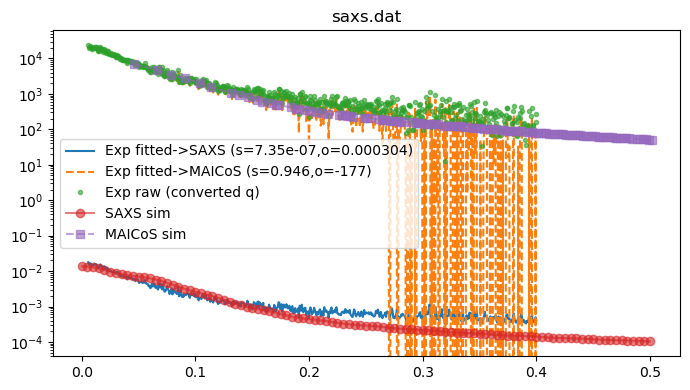

EN2 [['md2_EN2_amber99SBws_model1_nojump.xtc']] 42
icl2 [['replica_01_AMBER03WS_md_2000ns.xtc']] 101
Calmodulin [['md_calmodulin_DESamber_model10_nojump.xtc']] 51
asyn [['replica_01_AMBER99SBWS_md_2000ns.xtc']] 98


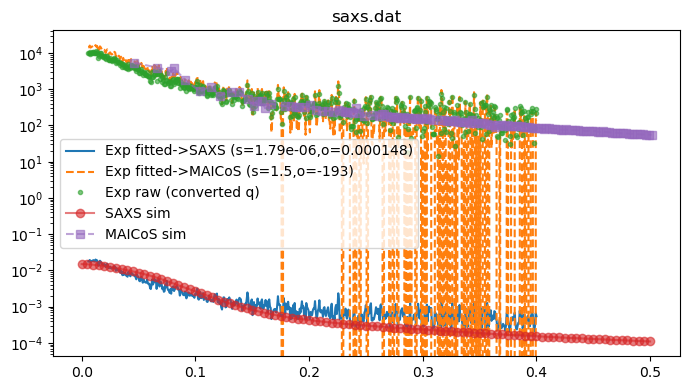

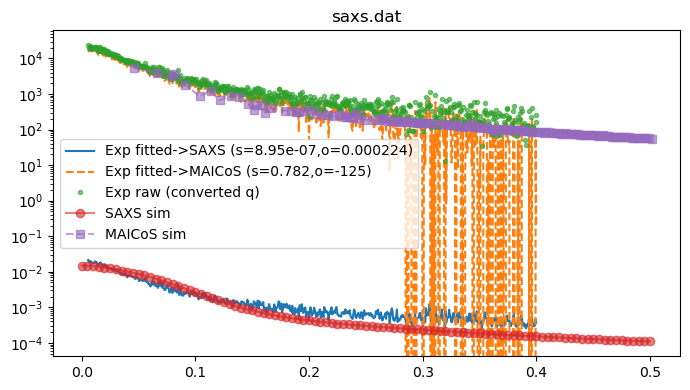

  Experimental  SAXS_N  SAXS_qmin  SAXS_qmax  SAXS_scale  SAXS_offset  \
0     saxs.dat     NaN        NaN        NaN         NaN          NaN   
1     saxs.dat     NaN        NaN        NaN         NaN          NaN   

   SAXS_RMSD  SAXS_RelRMSD  SAXS_RedChi2  MAICOS_N  MAICOS_qmin  MAICOS_qmax  \
0        NaN           NaN           NaN       NaN          NaN          NaN   
1        NaN           NaN           NaN       NaN          NaN          NaN   

   MAICOS_scale  MAICOS_offset  MAICOS_RMSD  MAICOS_RelRMSD  MAICOS_RedChi2  
0           NaN            NaN          NaN             NaN             NaN  
1           NaN            NaN          NaN             NaN             NaN  


In [11]:
for system in systems:
    SAXS_file = databankPath + 'Data/Simulations/' + system['path'] + 'SAXS.yaml'
    SAXS_MAICOS_file = databankPath + 'Data/Simulations/' + system['path'] + 'SAXS_MAICoS.yaml'
    if os.path.exists(SAXS_file) and os.path.exists(SAXS_MAICOS_file):
        print(system['SYSTEM'], system['TRJ'], system['ID'])
        exp_files = []
        for exp_path in system['EXPERIMENT']['saxs']['path']:
            exp_file_path = databankPath + 'Data/Experiments/saxs/' + exp_path + '/saxs.dat'
            exp_files.append(exp_file_path)
        #print(exp_files)
        df = compare_simulations_to_experiments(SAXS_file, SAXS_MAICOS_file, exp_files, fit=True, plot=True)
print(df)
        
        
        

In [46]:
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- Reading helpers ----------

def read_saxs_yaml(filename):
    with open(filename, 'r') as f:
        data = yaml.safe_load(f)
    q, I, I_std = [], [], []
    for d in data:
        q_val = d.get('q[1/A]', d.get('q', None))
        if q_val is None:
            continue
        I_key_candidates = ['mean_I(q)[a.u.]', 'mean_Inten[a.u.]', 'I(q)[a.u.]']
        I_val = next((d[k] for k in I_key_candidates if k in d), None)
        if I_val is None:
            continue
        sd_val = d.get('sd_I(q)[a.u.]', d.get('sd_Inten[a.u.]', 0.0))
        q.append(q_val)
        I.append(I_val)
        I_std.append(sd_val)
    return np.array(q), np.array(I), np.array(I_std)


def read_experimental_saxs(filename):
    """Reads experimental SAXS in 1/nm units → converts q to 1/Å."""
    q, I, err = [], [], []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or not (line[0].isdigit() or line[0]=='.'):
                continue
            parts = line.split()
            try:
                q_val = float(parts[0]) / 10.0  # convert 1/nm → 1/Å
                I_val = float(parts[1])
                err_val = float(parts[2]) if len(parts) >= 3 and float(parts[2]) >= 0 else 0.0
                q.append(q_val); I.append(I_val); err.append(err_val)
            except ValueError:
                continue
    return np.array(q), np.array(I), np.array(err)

# ---------- Core utilities ----------

def fit_scale_offset(x, y_ref, y_fit):
    """Fit scale and offset: y_ref ≈ scale*y_fit + offset"""
    A = np.vstack([y_fit, np.ones_like(y_fit)]).T
    scale, offset = np.linalg.lstsq(A, y_ref, rcond=None)[0]
    return scale, offset


def compute_rmsd_scaled(q_sim, I_sim, q_exp, I_exp, fit_scale=True):
    """Compute RMSD after fitting experimental I(q) to simulation scale and offset."""
    # Overlap region
    q_min, q_max = max(q_sim.min(), q_exp.min()), min(q_sim.max(), q_exp.max())
    mask_sim = (q_sim >= q_min) & (q_sim <= q_max)
    mask_exp = (q_exp >= q_min) & (q_exp <= q_max)
    if np.sum(mask_sim) < 3 or np.sum(mask_exp) < 3:
        raise ValueError("Not enough overlap between q ranges.")
    q_common = q_sim[mask_sim]
    I_sim_common = I_sim[mask_sim]
    I_exp_interp = np.interp(q_common, q_exp[mask_exp], I_exp[mask_exp])

    # Fit scale and offset if requested
    if fit_scale:
        scale, offset = fit_scale_offset(q_common, I_sim_common, I_exp_interp)
    else:
        scale, offset = 1.0, 0.0

    I_exp_fit = I_exp_interp * scale + offset
    diffs = I_sim_common - I_exp_fit
    rmsd = np.sqrt(np.mean(diffs**2))
    rel_rmsd = rmsd / np.mean(np.abs(I_sim_common))
    return rmsd, rel_rmsd, scale, offset, (q_min, q_max)


def compare_simulations_to_experiments_scaled(saxs_file, maicos_file, experimental_files, plot=False):
    """Compare SAXS and MAICoS vs multiple experimental datasets using scaled RMSD."""
    q_saxs, I_saxs, _ = read_saxs_yaml(saxs_file)
    q_maicos, I_maicos, _ = read_saxs_yaml(maicos_file)

    results = []
    for exp_file in experimental_files:
        q_exp, I_exp, _ = read_experimental_saxs(exp_file)

        try:
            rmsd_saxs, relrmsd_saxs, scale_saxs, offset_saxs, qrange_saxs = compute_rmsd_scaled(q_saxs, I_saxs, q_exp, I_exp)
        except Exception as e:
            rmsd_saxs, relrmsd_saxs, scale_saxs, offset_saxs, qrange_saxs = (np.nan, np.nan, np.nan, np.nan, (np.nan, np.nan))
            print(f"⚠️ SAXS failed for {exp_file}: {e}")

        try:
            rmsd_maicos, relrmsd_maicos, scale_maicos, offset_maicos, qrange_maicos = compute_rmsd_scaled(q_maicos, I_maicos, q_exp, I_exp)
        except Exception as e:
            rmsd_maicos, relrmsd_maicos, scale_maicos, offset_maicos, qrange_maicos = (np.nan, np.nan, np.nan, np.nan, (np.nan, np.nan))
            print(f"⚠️ MAICoS failed for {exp_file}: {e}")

        results.append({
            "Experimental": exp_file.split('/')[-1],
            "SAXS_RMSD": rmsd_saxs, "SAXS_relRMSD": relrmsd_saxs,
            "SAXS_scale": scale_saxs, "SAXS_offset": offset_saxs,
            "MAICoS_RMSD": rmsd_maicos, "MAICoS_relRMSD": relrmsd_maicos,
            "MAICoS_scale": scale_maicos, "MAICoS_offset": offset_maicos
        })

        if plot:
            plt.figure(figsize=(7,5))
            plt.title(exp_file.split('/')[-1])
            plt.yscale('log')
            plt.xlabel(r"$q$ (1/Å)")
            plt.ylabel(r"$I(q)$ (a.u.)")

            # Apply fitted scaling
            q_min, q_max = qrange_maicos
            mask_exp = (q_exp >= q_min) & (q_exp <= q_max)
            plt.plot(q_exp[mask_exp], I_exp[mask_exp]*scale_saxs+offset_saxs, '-', label=f"Exp→SAXS fit (×{scale_saxs:.2e}, +{offset_saxs:.2e})")
            plt.plot(q_exp[mask_exp], I_exp[mask_exp]*scale_maicos+offset_maicos, '--', label=f"Exp→MAICoS fit (×{scale_maicos:.2e}, +{offset_maicos:.2e})")

            plt.plot(q_saxs, I_saxs, 'o-', alpha=0.7, label="SAXS sim")
            plt.plot(q_maicos, I_maicos, 's--', alpha=0.7, label="MAICoS sim")

            plt.legend()
            plt.tight_layout()
            plt.show()

    df = pd.DataFrame(results)
    return df


asyn [['replica_02_AMBER03WS_md_2000ns.xtc']] 87


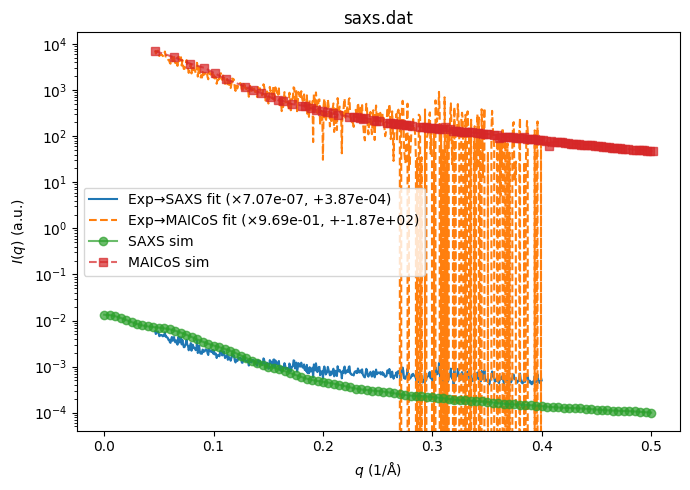

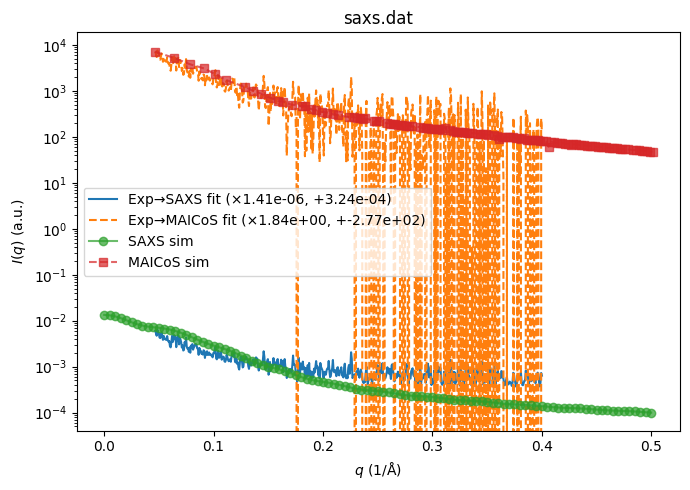

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000887      0.428748  7.070149e-07     0.000387   
1     saxs.dat   0.000924      0.452191  1.412655e-06     0.000324   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   188.062300        0.379604      0.969458    -187.239631  
1   325.947421        0.657925      1.843676    -276.540046  
asyn [['replica_04_DESAMBER_md_2000ns.xtc']] 93


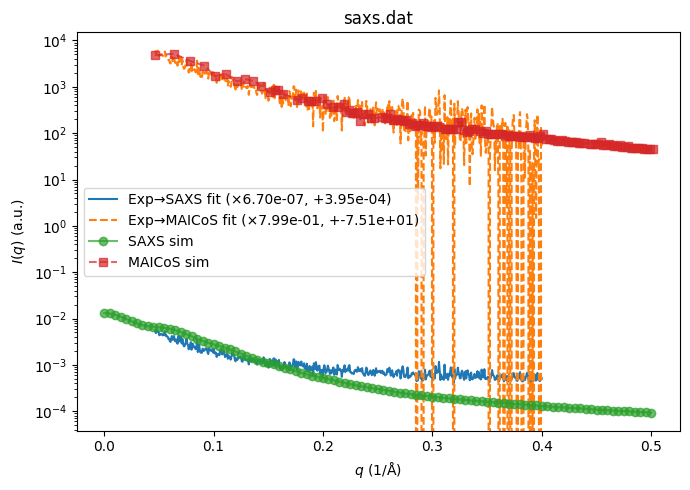

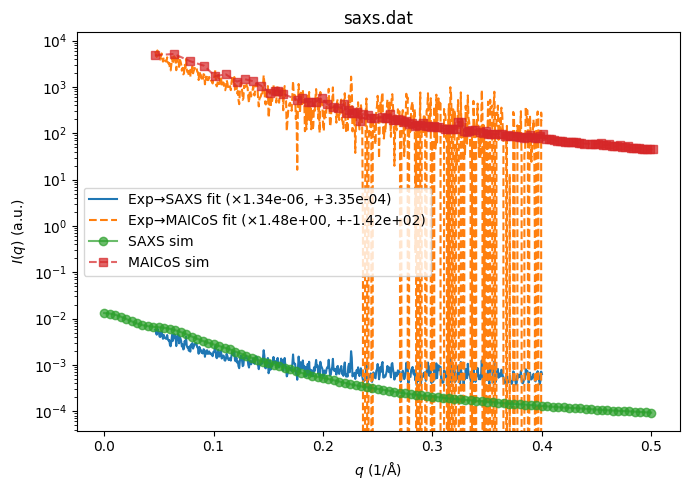

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000800      0.402332  6.700521e-07     0.000395   
1     saxs.dat   0.000836      0.425410  1.339202e-06     0.000335   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   249.630550        0.522503      0.799154     -75.128382  
1   365.195993        0.764393      1.481178    -141.590478  
KRS1-72 [['replica_01_AMBER03WS_md_2000ns.xtc']] 99
Empty DataFrame
Columns: []
Index: []
asyn [['replica_04_CHARMM36M_md_2000ns.xtc']] 90


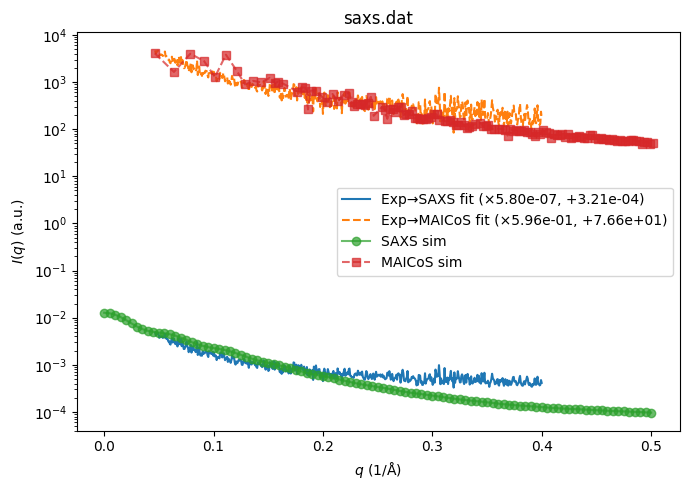

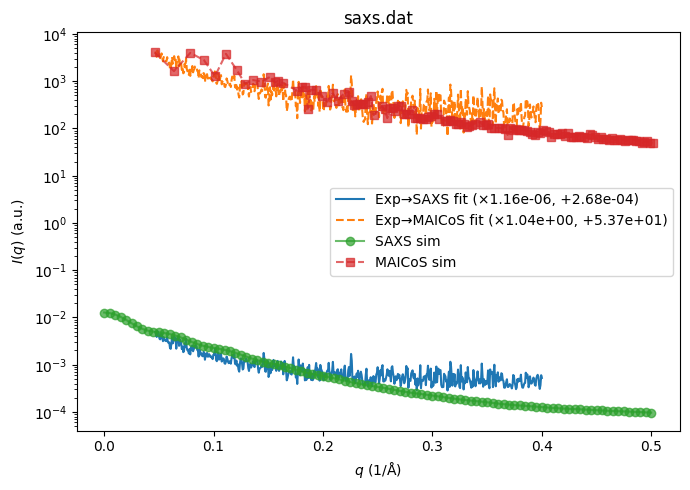

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000493      0.289511  5.803845e-07     0.000321   
1     saxs.dat   0.000525      0.312555  1.161260e-06     0.000268   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   444.096034        0.909454      0.595672      76.623249  
1   524.290673        1.073683      1.042619      53.747869  
asyn [['replica_01_DESAMBER_md_2000ns.xtc']] 71


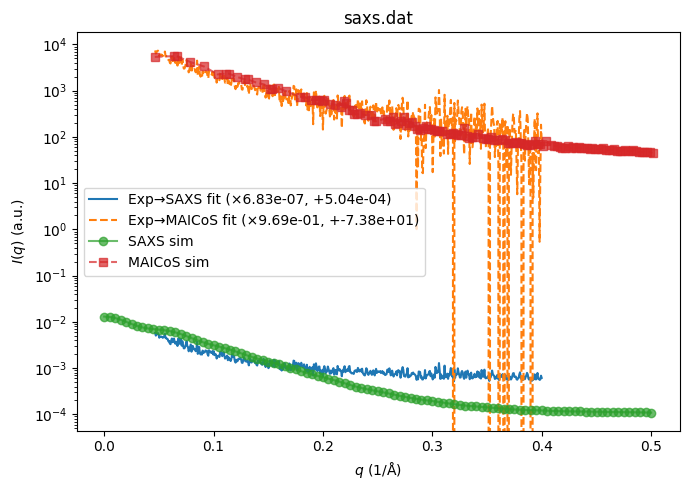

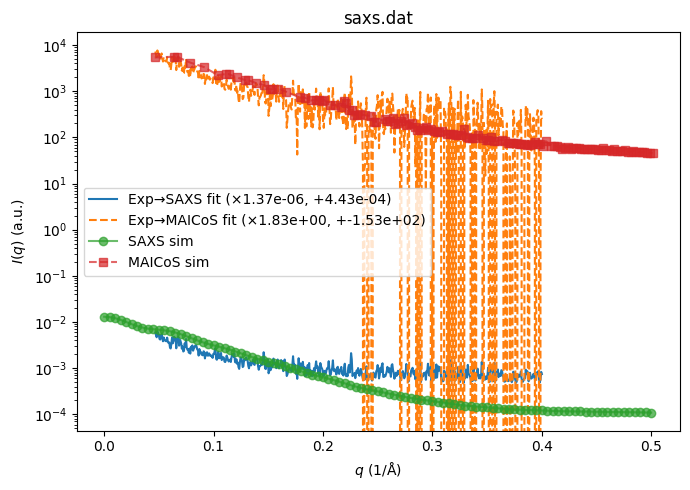

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000906      0.425288  6.833762e-07     0.000504   
1     saxs.dat   0.000944      0.448809  1.365210e-06     0.000443   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   360.282495        0.552396      0.969424     -73.811421  
1   498.317706        0.764036      1.833757    -153.039352  
asyn [['replica_03_DESAMBER_md_2000ns.xtc']] 76


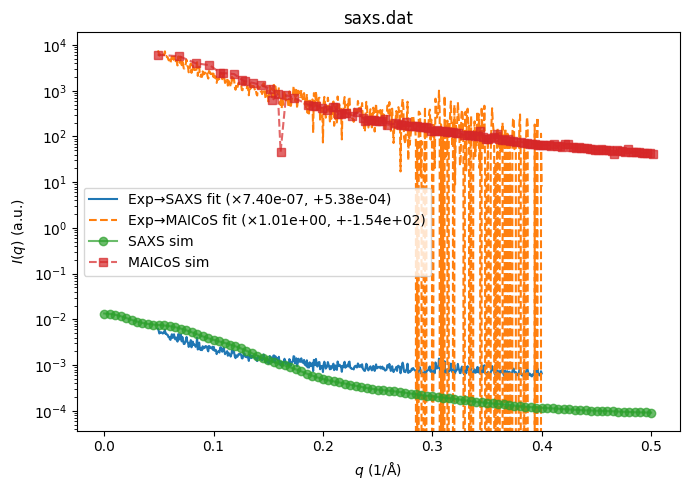

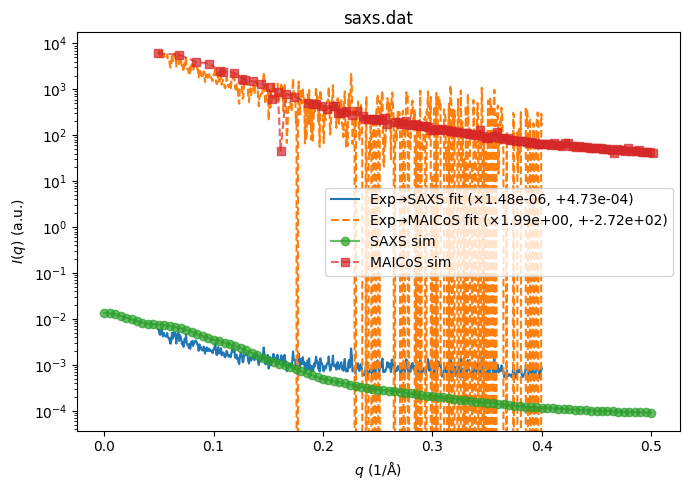

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.001102      0.479740  7.401655e-07     0.000538   
1     saxs.dat   0.001146      0.504963  1.477179e-06     0.000473   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   331.033619        0.605627      1.014270    -154.339780  
1   406.772485        0.744191      1.986665    -272.280907  
Calmodulin [['md_calmodulin_DESamber_model10_nojump.xtc']] 51
Empty DataFrame
Columns: []
Index: []
asyn [['replica_05_CHARMM36M_md_2000ns.xtc']] 88


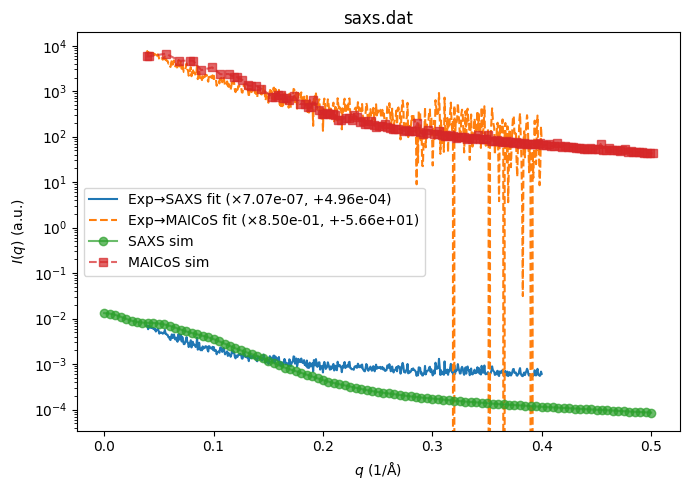

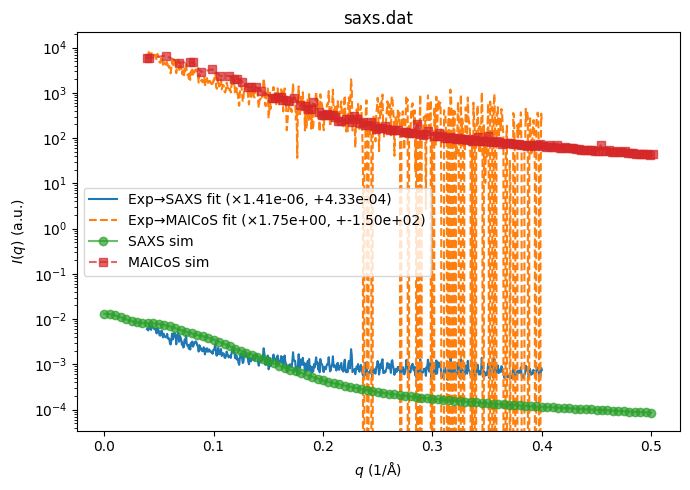

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.001121      0.514767  7.072718e-07     0.000496   
1     saxs.dat   0.001154      0.536296  1.412619e-06     0.000433   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   479.788475        0.700879      0.850001     -56.632251  
1   615.513112        0.899146      1.745507    -149.522781  
asyn [['replica_01_CHARMM36M_md_2000ns.xtc']] 61


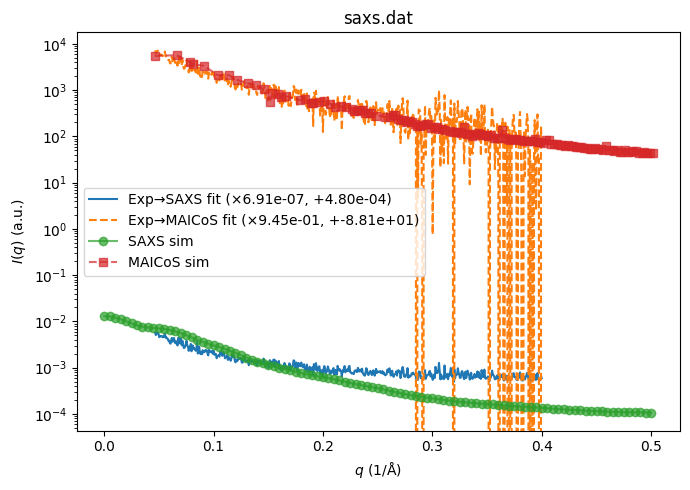

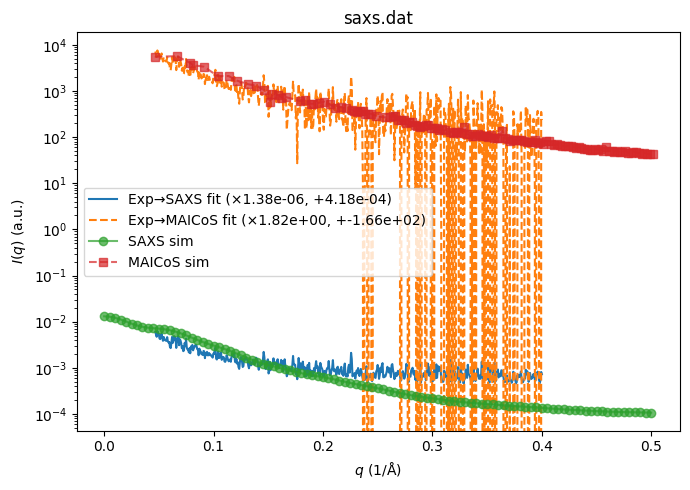

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000929      0.437351  6.914474e-07     0.000480   
1     saxs.dat   0.000966      0.460214  1.381396e-06     0.000418   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   329.309822         0.57934      0.945062     -88.062184  
1   470.892552         0.82842      1.815917    -166.495148  
asyn [['replica_04_AMBER99SB-DISP_md_2000ns.xtc']] 65


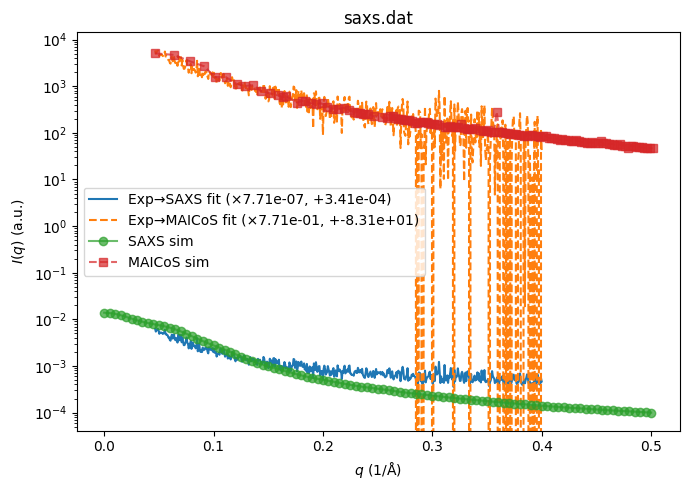

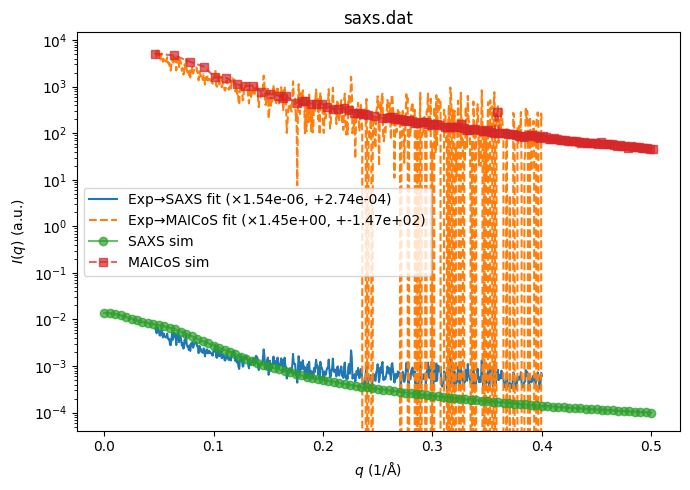

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000885      0.407259  7.705283e-07     0.000341   
1     saxs.dat   0.000928      0.432385  1.539552e-06     0.000274   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   188.814873        0.419475      0.771016     -83.084057  
1   306.065664        0.679961      1.446528    -146.603052  
asyn [['replica_01_AMBER99SB-DISP_md_2000ns.xtc']] 66


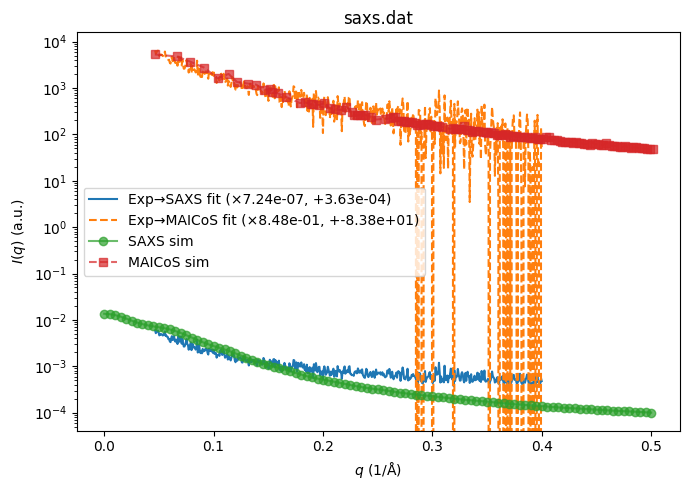

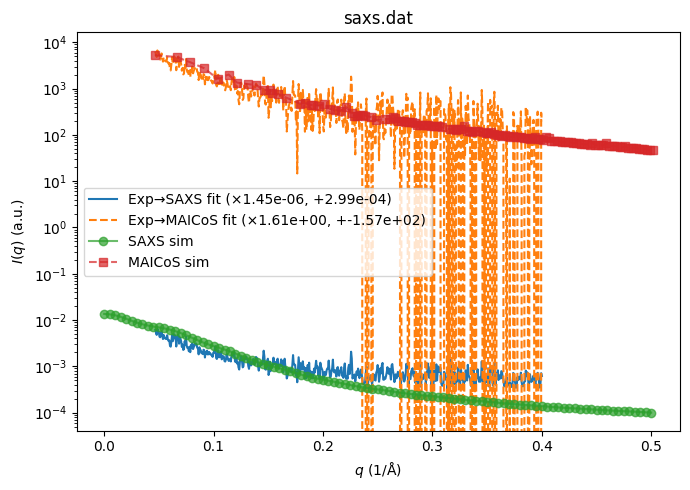

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000810      0.388477  7.238772e-07     0.000363   
1     saxs.dat   0.000851      0.413244  1.446592e-06     0.000299   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   245.246448        0.506408      0.848071     -83.821540  
1   385.418983        0.795850      1.606535    -156.625121  
asyn [['replica_05_AMBER99SB-DISP_md_2000ns.xtc']] 73


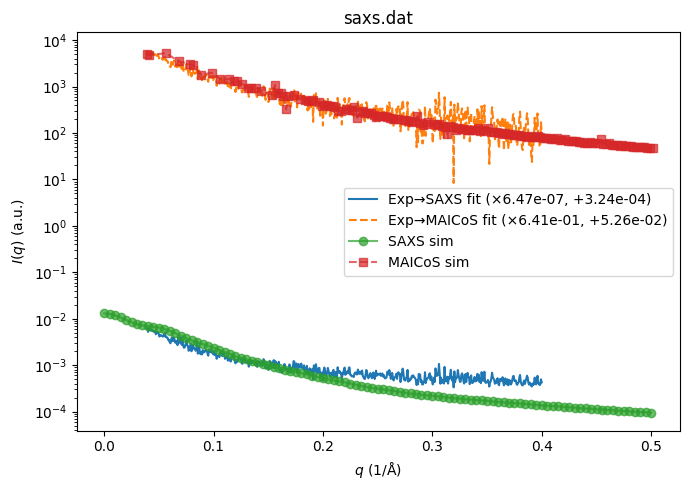

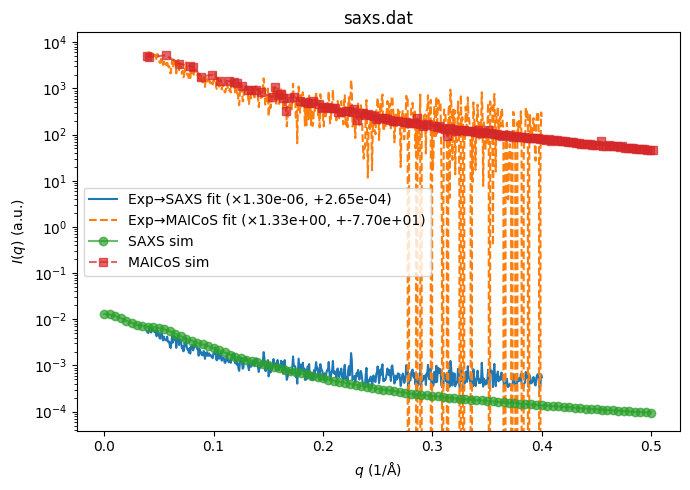

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000695      0.372643  6.473912e-07     0.000324   
1     saxs.dat   0.000719      0.390486  1.295639e-06     0.000265   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   257.418876        0.460505      0.641000       0.052561  
1   366.074763        0.654883      1.330997     -77.013142  
asyn [['replica_04_AMBER99SBWS_md_2000ns.xtc']] 69


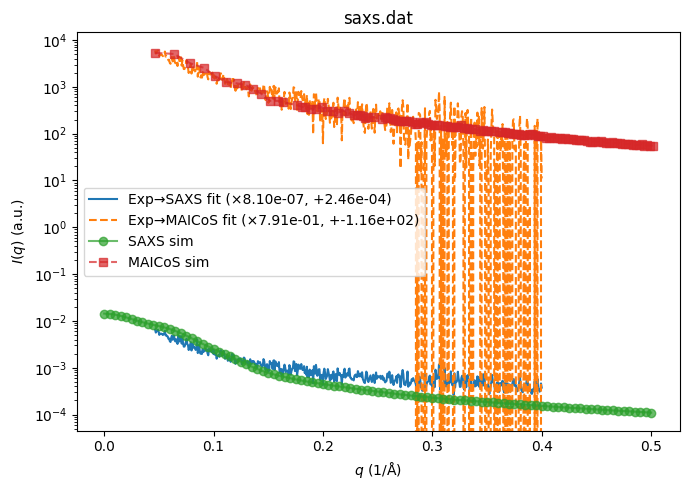

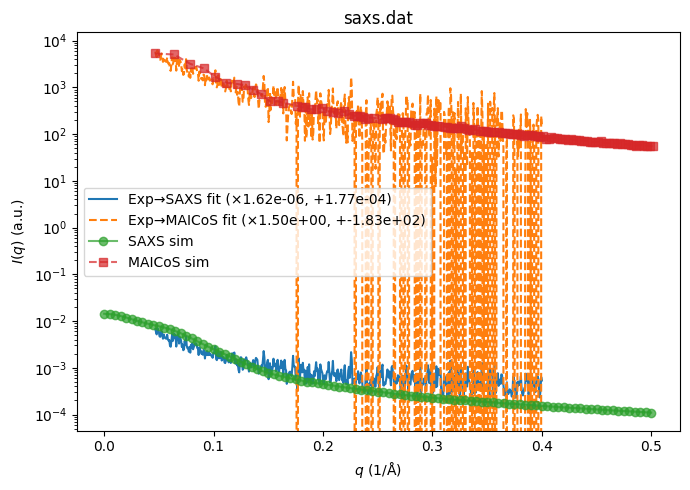

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000879      0.404675  8.097597e-07     0.000246   
1     saxs.dat   0.000923      0.429855  1.618197e-06     0.000177   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   184.216828        0.425950      0.791138    -115.589144  
1   289.333430        0.669003      1.495909    -182.830920  
asyn [['replica_02_CHARMM36M_md_2000ns.xtc']] 57


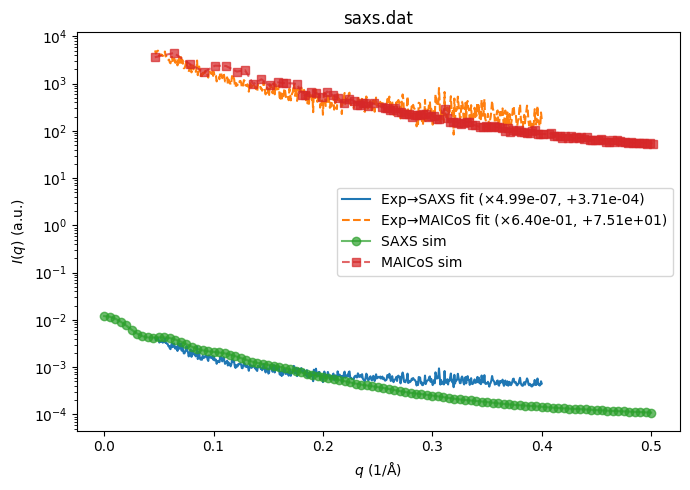

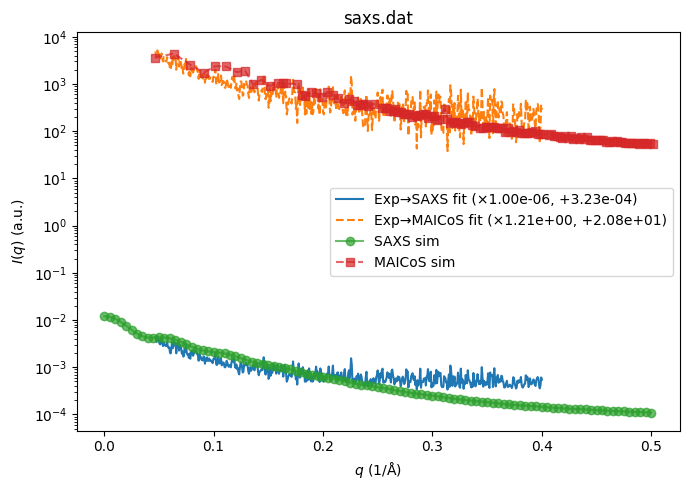

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000497      0.319036  4.990963e-07     0.000371   
1     saxs.dat   0.000513      0.333456  9.997544e-07     0.000323   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   314.750806        0.611213      0.639706      75.068137  
1   366.790121        0.712268      1.205438      20.780670  
asyn [['replica_05_DESAMBER_md_2000ns.xtc']] 91


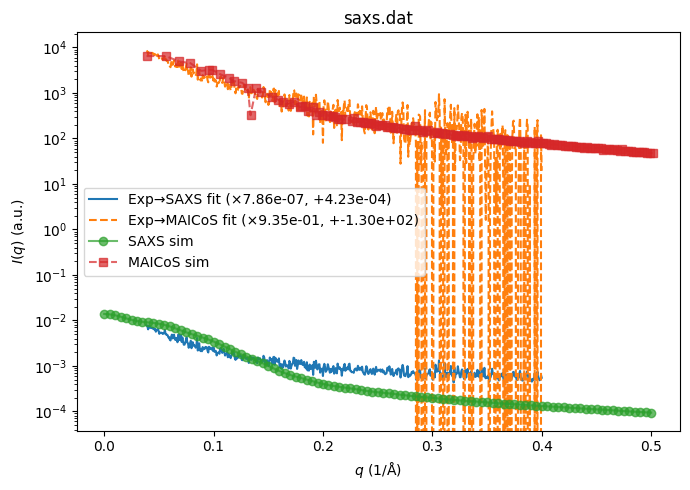

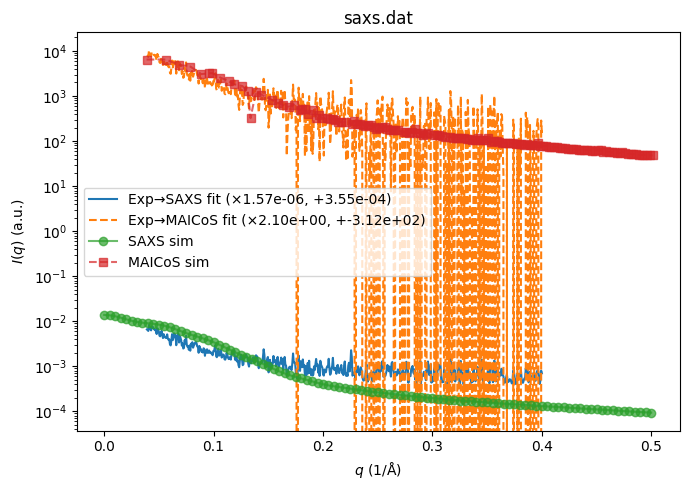

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.001155      0.503812  7.863206e-07     0.000423   
1     saxs.dat   0.001194      0.527192  1.570179e-06     0.000355   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   377.408032        0.619002      0.934615    -130.185147  
1   495.063300        0.811973      2.098641    -311.651087  
ChiZ1-64 [['replica_01_AMBER03WS_md_1500ns.xtc']] 100
Empty DataFrame
Columns: []
Index: []
asyn [['replica_01_AMBER99SBWS_md_2000ns.xtc']] 98


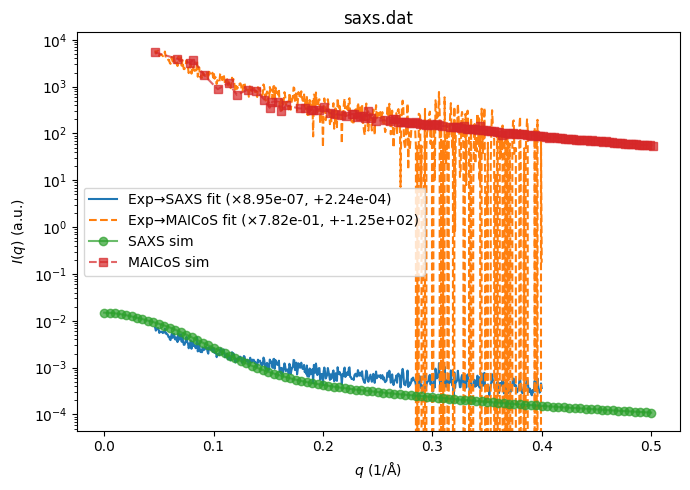

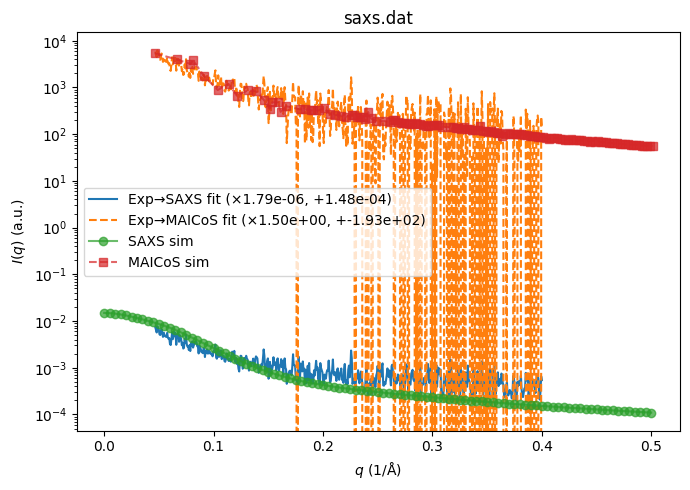

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.001007      0.428076  8.951075e-07     0.000224   
1     saxs.dat   0.001056      0.454101  1.788298e-06     0.000148   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   210.158617        0.503434      0.781983    -125.034218  
1   349.385331        0.836950      1.503613    -193.033769  
EN2 [['md2_EN2_amber99SBws_model1_nojump.xtc']] 42
Empty DataFrame
Columns: []
Index: []
asyn [['replica_02_AMBER99SBWS_md_2000ns.xtc']] 63


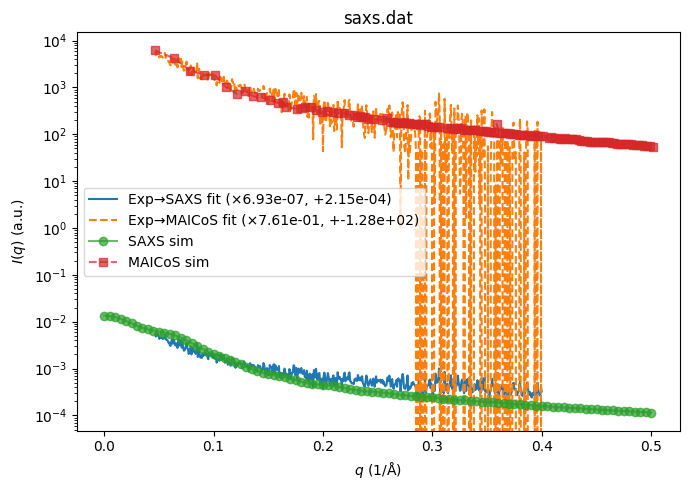

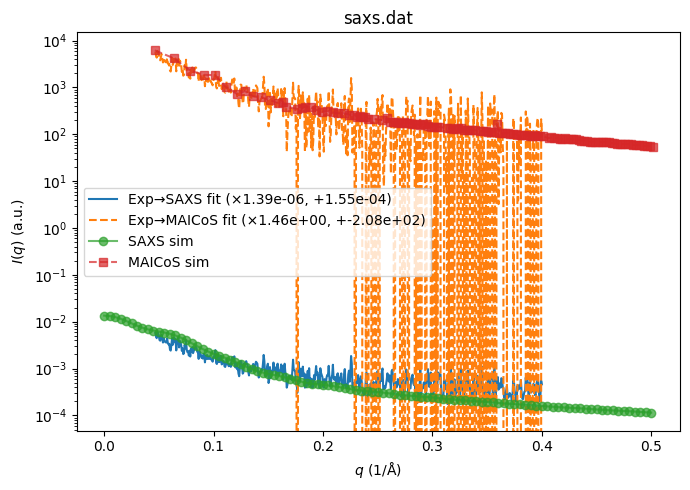

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000606      0.325356  6.927019e-07     0.000215   
1     saxs.dat   0.000644      0.349789  1.385302e-06     0.000155   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   136.138198        0.342004      0.761481    -127.801646  
1   211.079192        0.530269      1.464745    -208.284613  
asyn [['replica_04_AMBER03WS_md_2000ns.xtc']] 77


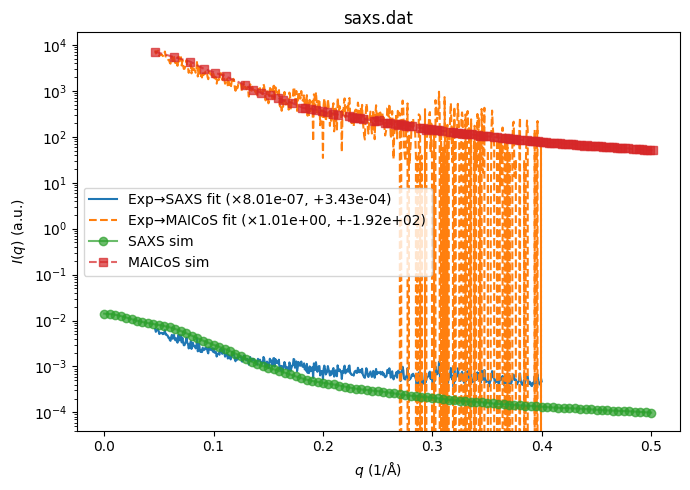

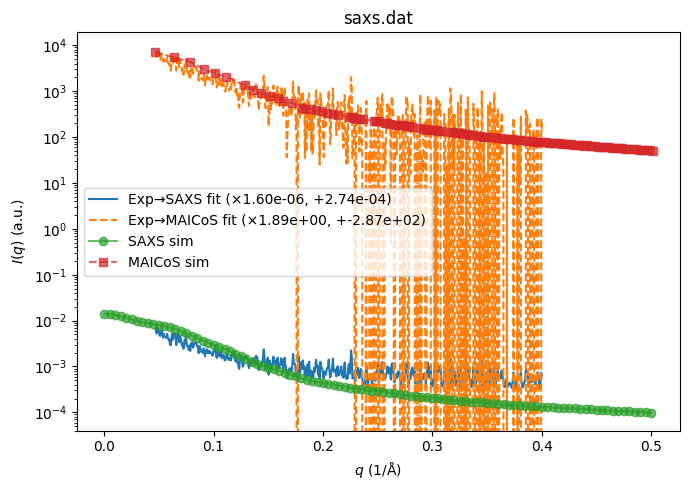

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.001002      0.445493  8.010638e-07     0.000343   
1     saxs.dat   0.001045      0.470639  1.600060e-06     0.000274   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   211.505611        0.399854      1.007329    -192.006927  
1   391.885018        0.740864      1.886592    -286.566162  
asyn [['replica_03_AMBER03WS_md_2000ns.xtc']] 81


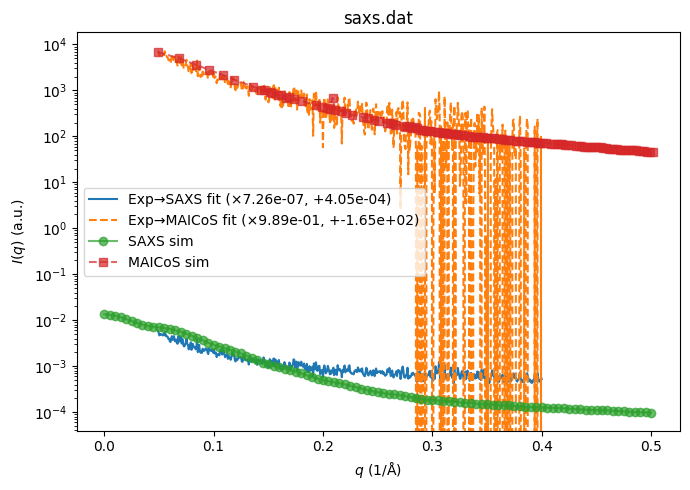

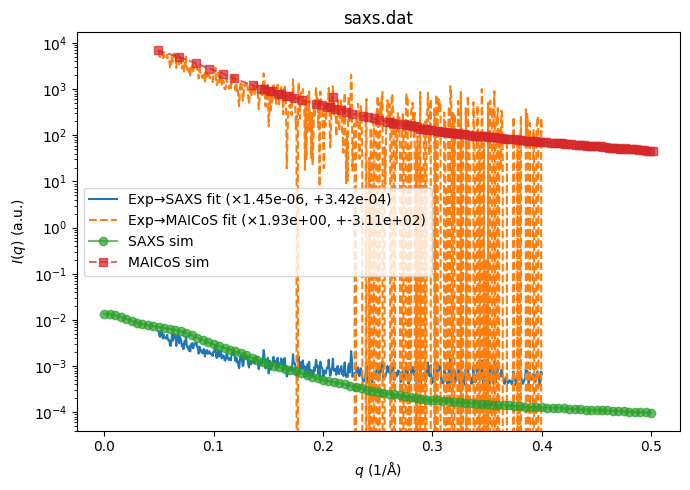

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000901      0.422694  7.257704e-07     0.000405   
1     saxs.dat   0.000944      0.448316  1.449543e-06     0.000342   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   218.609054        0.417882      0.989286    -164.675653  
1   321.325231        0.614229      1.928887    -310.916876  
asyn [['replica_03_CHARMM36M_md_2000ns.xtc']] 74


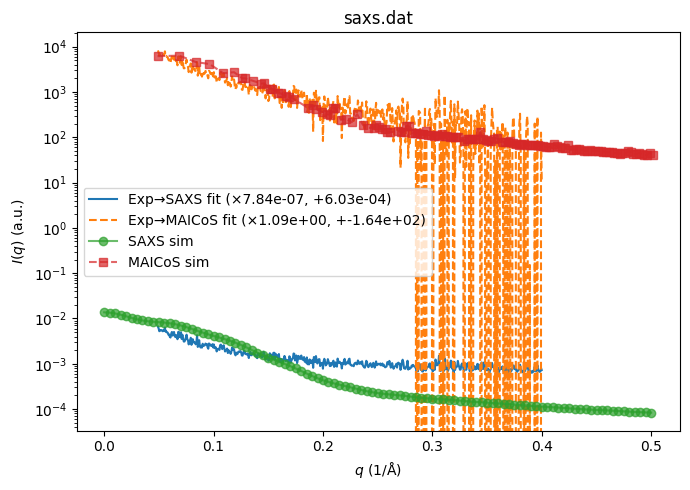

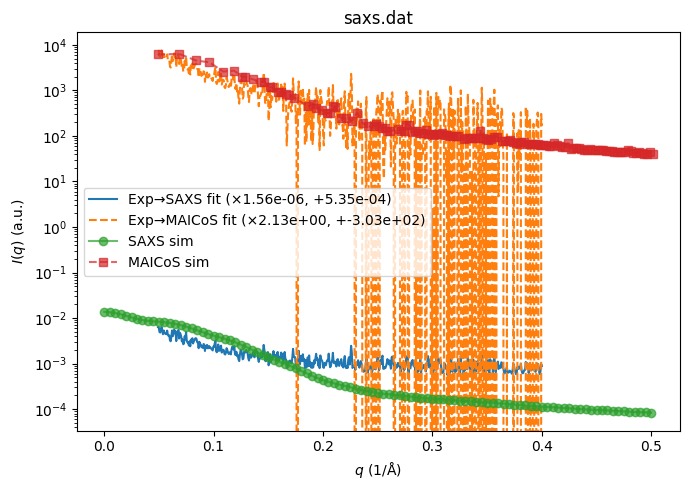

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.001329      0.538451  7.839367e-07     0.000603   
1     saxs.dat   0.001374      0.563791  1.563351e-06     0.000535   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   427.806268        0.733869      1.094079    -163.754700  
1   487.815955        0.836811      2.128507    -302.650107  
asyn [['replica_03_AMBER99SB-DISP_md_2000ns.xtc']] 89


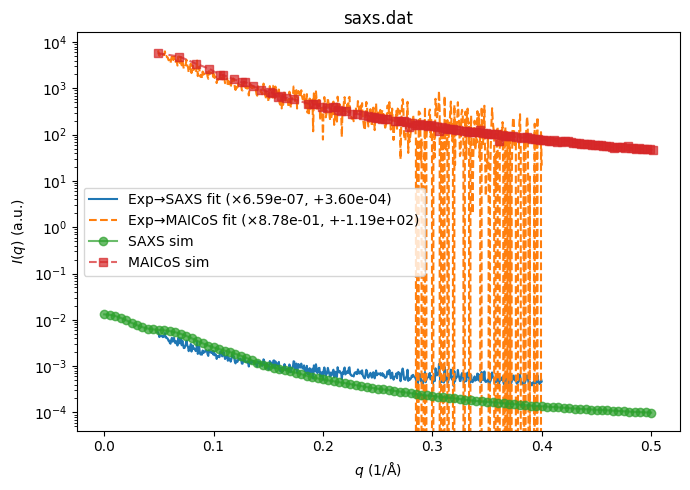

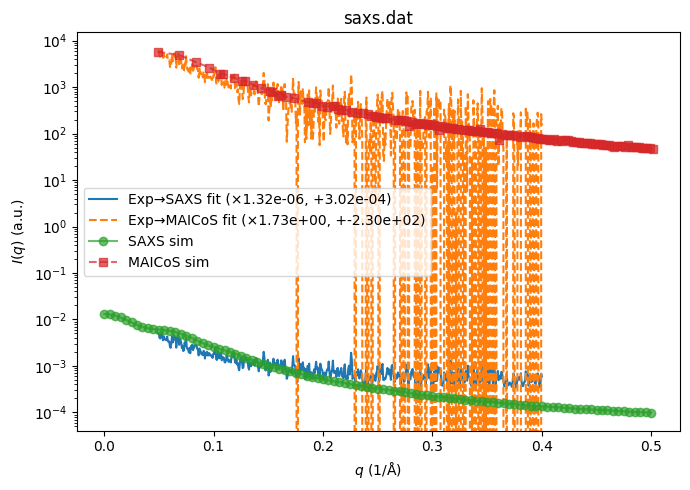

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000710      0.368261  6.594068e-07     0.000360   
1     saxs.dat   0.000748      0.392720  1.318006e-06     0.000302   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   234.223272        0.476702      0.877695    -119.042851  
1   300.221937        0.611026      1.730103    -229.589009  
icl2 [['replica_01_AMBER03WS_md_2000ns.xtc']] 101
Empty DataFrame
Columns: []
Index: []
asyn [['replica_05_AMBER99SBWS_md_2000ns.xtc']] 86


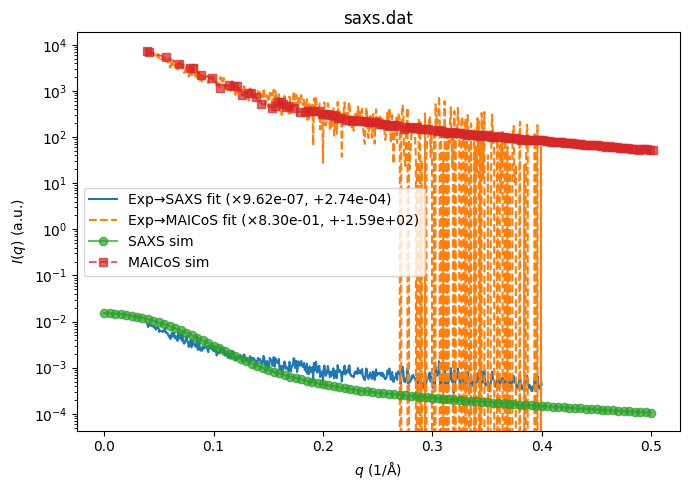

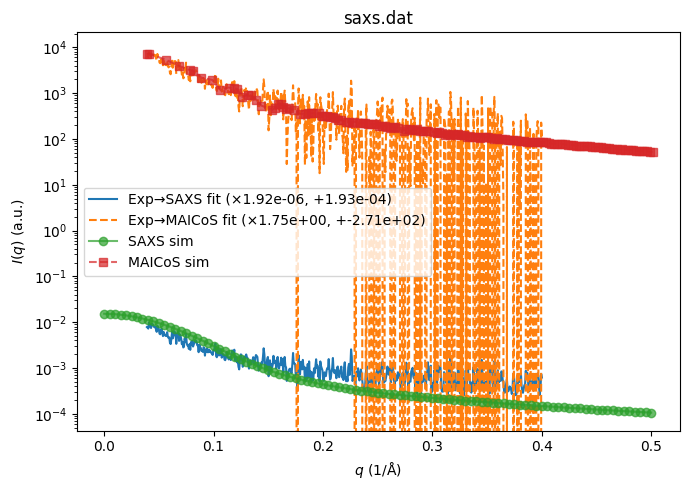

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.001200      0.468548  9.618939e-07     0.000274   
1     saxs.dat   0.001254      0.495469  1.920661e-06     0.000193   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   182.247579        0.321084      0.829701    -158.913980  
1   332.245292        0.585350      1.747670    -270.858254  
asyn [['replica_01_AMBER03WS_md_2000ns.xtc']] 102


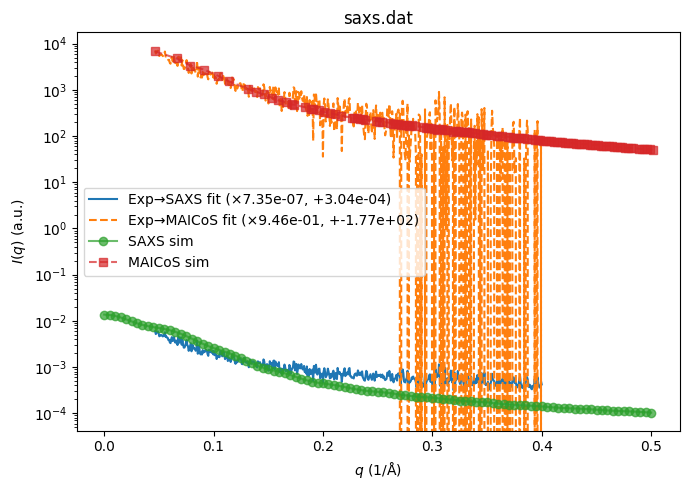

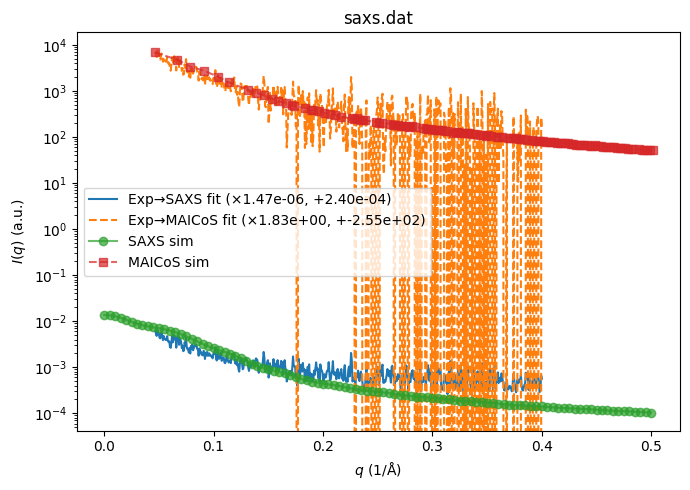

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat    0.00081      0.394958  7.347342e-07     0.000304   
1     saxs.dat    0.00085      0.419336  1.468440e-06     0.000240   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   191.787103        0.405268      0.946406    -177.007848  
1   326.623670        0.690193      1.834081    -255.094158  
asyn [['replica_03_AMBER99SBWS_md_2000ns.xtc']] 52


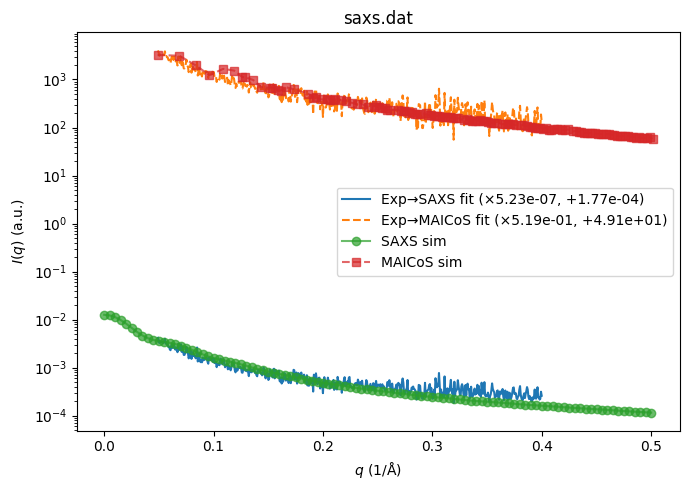

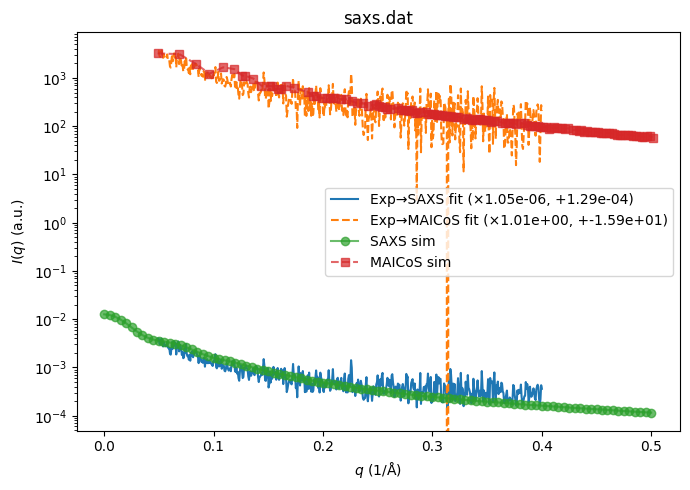

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000331      0.233043  5.232586e-07     0.000177   
1     saxs.dat   0.000349      0.248224  1.048251e-06     0.000129   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   184.032368        0.453685      0.518979      49.081174  
1   214.918795        0.529827      1.014887     -15.885180  
asyn [['replica_02_AMBER99SB-DISP_md_2000ns.xtc']] 53


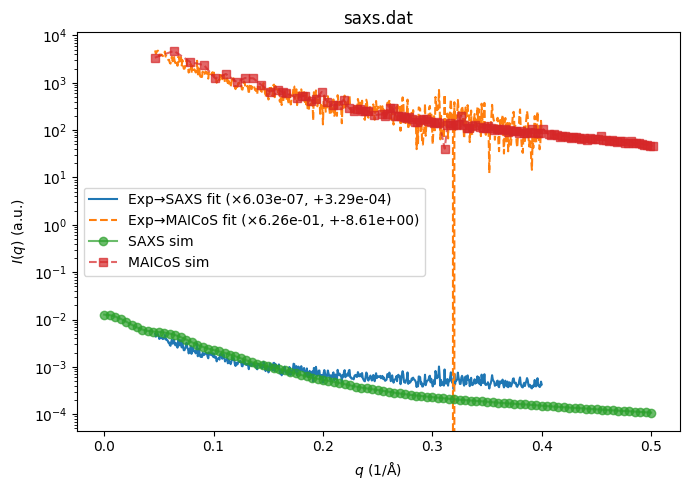

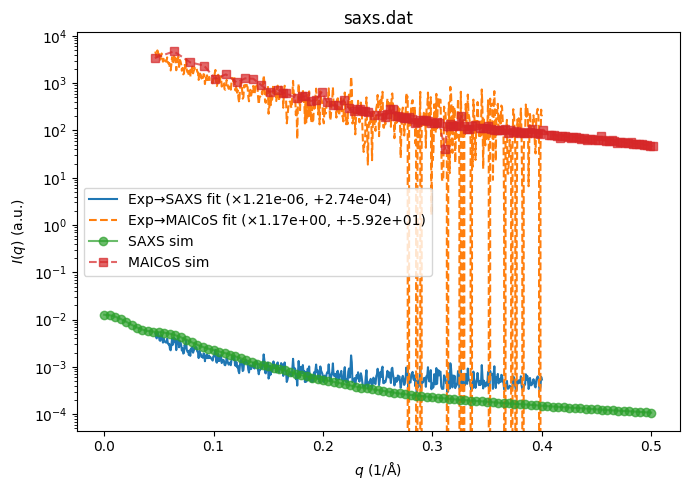

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000577      0.327571  6.025633e-07     0.000329   
1     saxs.dat   0.000607      0.348695  1.205498e-06     0.000274   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   258.584255        0.612957      0.626013      -8.612553  
1   324.237578        0.768583      1.173461     -59.207252  
asyn [['replica_05_AMBER03WS_md_2000ns.xtc']] 92


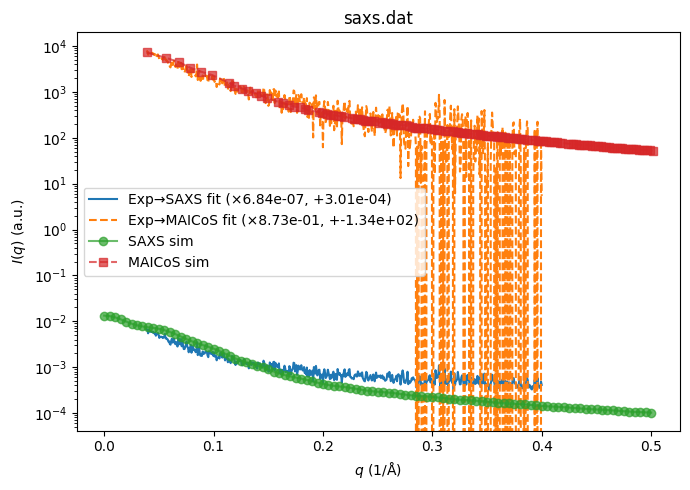

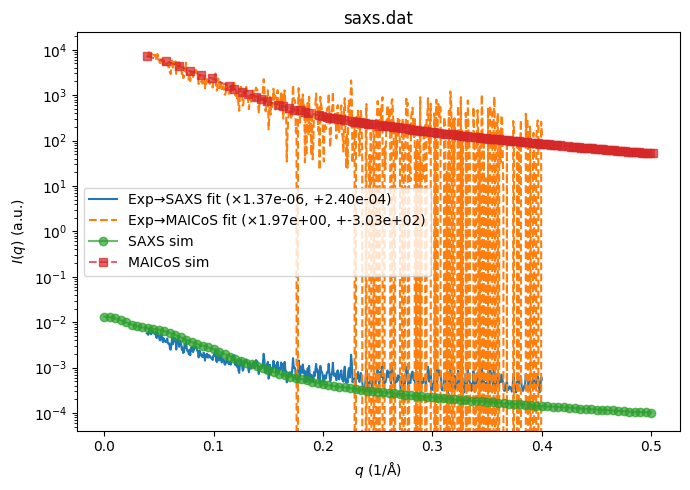

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000772      0.400266  6.844247e-07     0.000301   
1     saxs.dat   0.000800      0.419919  1.369026e-06     0.000240   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   200.358111        0.372456      0.873181    -134.401053  
1   333.675266        0.620286      1.970025    -302.934648  
asyn [['replica_02_DESAMBER_md_2000ns.xtc']] 62


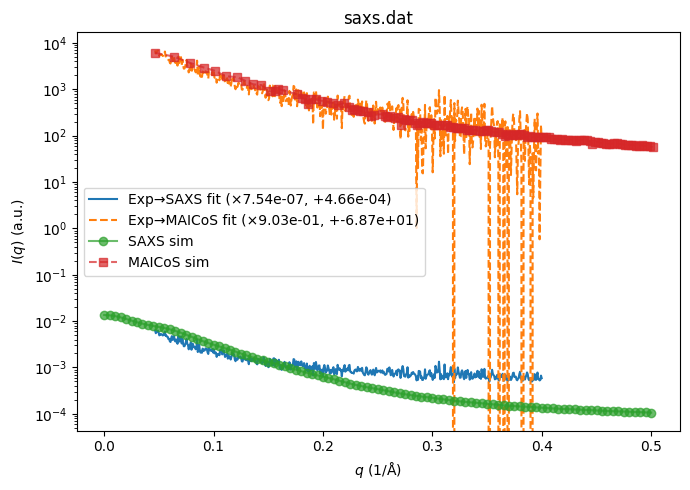

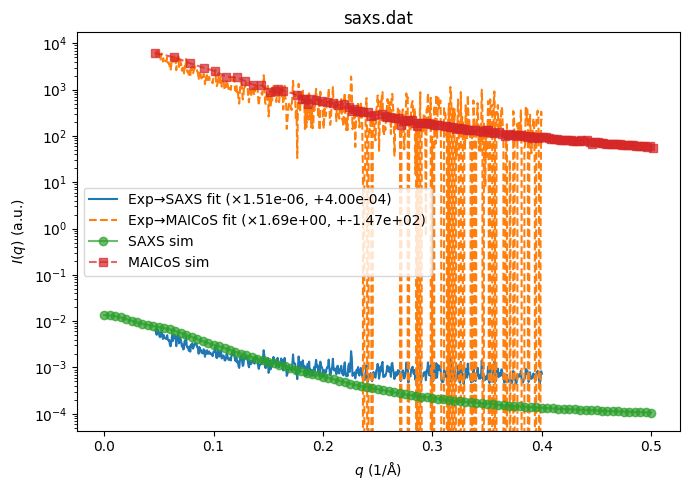

  Experimental  SAXS_RMSD  SAXS_relRMSD    SAXS_scale  SAXS_offset  \
0     saxs.dat   0.000931      0.412226  7.540184e-07     0.000466   
1     saxs.dat   0.000977      0.437588  1.506083e-06     0.000400   

   MAICoS_RMSD  MAICoS_relRMSD  MAICoS_scale  MAICoS_offset  
0   218.937341        0.389751      0.903364     -68.703873  
1   352.156640        0.626907      1.690111    -146.735479  


In [47]:
for system in systems:
    SAXS_file = databankPath + 'Data/Simulations/' + system['path'] + 'SAXS.yaml'
    SAXS_MAICOS_file = databankPath + 'Data/Simulations/' + system['path'] + 'SAXS_MAICoS.yaml'
    if os.path.exists(SAXS_file) and os.path.exists(SAXS_MAICOS_file):
        print(system['SYSTEM'], system['TRJ'], system['ID'])
        exp_files = []
        for exp_path in system['EXPERIMENT']['saxs']['path']:
            exp_file_path = databankPath + 'Data/Experiments/saxs/' + exp_path + '/saxs.dat'
            exp_files.append(exp_file_path)
        df = compare_simulations_to_experiments_scaled(
            SAXS_file,
            SAXS_MAICOS_file,
            exp_files,
            plot=True
        )
        print(df)